# trackastra 090326 — summary figures

Successor to `trackastra_figures_082026.ipynb`, which is now closed. That notebook derived
everything from the two raw pipeline CSVs on every run — 2,442 lines of code across 45 cells.
This one **loads** the state it exported and calls into `mmtrack.figures`, so what is left here
is the analysis choices, not the plumbing.

### What it reads

| file | one row is |
|---|---|
| `data/all_data_annotated_082026.csv` | one cell at one frame (90,010 × 41) |
| `data/track_pairs_annotated_082026.csv` | one cell pair, `within_track` or `division` (88,890 × 61) |
| `data/bursts_082026.csv` | one detected burst peak (91 × 16) |
| `data/divisions_082026.csv` | one observed division — written by this notebook on first run |

Both annotated files carry **all 23 experiments** and tag the three failed acquisitions with
`is_failed_experiment`. `load_annotated()` drops them by default, which reproduces every number
the 082026 notebook published.

### Units — the one thing to get right

Four fluorescence columns, and they are **not** interchangeable:

| column | meaning |
|---|---|
| `intensity_mean_fluor` | raw a.u. Not comparable across experiments, which run at 150–500 ms exposure. |
| `fluor_per_ms` | raw / `fluor_exposure_ms`. **The default everywhere below**, and the only one comparable across genes. |
| `fluor_filtered` | re-measured on median-filtered images. 0.41–1.00× the raw value depending on how noise-dominated the run is, so it sits on its own scale. |
| `fluor_filtered_per_ms` | the filtered column, exposure-normalised. |

Same on the pair table: `delta_fluor` is **raw a.u.**; `delta_fluor_per_ms` is the normalised
one. `mmtrack.figures` defaults to the per-ms columns and takes the column name as an argument,
so the choice is visible at every call site.

### What is not here

**Burst detection.** It needs ~600 lines of envelope, MAD-baseline, lineage-family and
spatial-cluster machinery, and it lives in the 082026 notebook. Its output is
`data/bursts_082026.csv`, which is what section 6 reads. Changing a burst definition means going
back to that notebook — the frozen parameters the shipped table was made with are recorded in
`mmtrack.figures.BURST_DEF`.

Bursts were detected on the 20 kept experiments, so a burst *rate* against a 23-experiment
denominator is silently wrong. `load_bursts(cells=cells)` checks the two scopes agree.

**Per-kymograph min–max.** The exports carry `{base}_kymo_min/_max/_kymo_minmax` for all four
units, grouped by one kymograph (292 groups). Section 7's histograms scale within
*(gene, experiment)* instead (~30 groups) — a different partition and a different answer, so the
two are not substitutes. The exported columns are there for anything that wants a per-kymograph
scale; `rescale_within_group` is what section 7 uses.

In [1]:
import os
import sys

REPO_ROOT = '/Users/adrianjuarez/Documents/Covert_lab/repos/mother_machine_cell_tracker'
sys.path.insert(0, REPO_ROOT)          # belt-and-braces; mmtrack is also pip-installed -e
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import mmtrack
assert os.path.realpath(mmtrack.__file__).startswith(os.path.realpath(REPO_ROOT)), (
    f'mmtrack resolves to {mmtrack.__file__}, not this repo.\n'
    f'Fix with:  {sys.executable} -m pip install -e . --no-deps   (run from {REPO_ROOT})')

# The figure layer. Everything plot-shaped lives here now, so this notebook is calls.
import mmtrack.figures as F
from mmtrack.lineage_stats import division_events, doubling_by_experiment, doubling_by_gene

%load_ext autoreload
%autoreload 2

# ---- CONFIG: the only cell to edit --------------------------------------------------------
FIG_DIR = f'{REPO_ROOT}/notebooks/figures/summary_090326'
SAVE_FIGS = True
DROP_FAILED = True          # False keeps all 23 experiments; see the header for the caveat
DIVISIONS_CSV = f'{REPO_ROOT}/data/divisions_082026.csv'

F.configure(out_dir=FIG_DIR, save=SAVE_FIGS,
            label=F.scope_label(drop_failed=DROP_FAILED), suffix='')

pd.set_option('display.max_rows', 300)
pd.set_option('display.width', 220)
pd.set_option('display.max_colwidth', None)   # peak_id lists must not be truncated
print(f'figures -> {FIG_DIR}  (save={SAVE_FIGS})')

figures -> /Users/adrianjuarez/Documents/Covert_lab/repos/mother_machine_cell_tracker/notebooks/figures/summary_090326  (save=True)


In [2]:
cells, pairs = F.load_annotated(data_root=REPO_ROOT, drop_failed=DROP_FAILED)

# `bursts` is the ACTIVE definition's events. The CSV on disk is the union of every
# definition -- 91 rows, of which 73 are v1 and 89 are v3 -- so it has to be filtered, and
# not filtering it was a bug: Table F used to report 91 bursts and lacZ 35.
bursts = F.load_bursts(data_root=REPO_ROOT, cells=cells)
bursts_all = F.load_bursts(data_root=REPO_ROOT, cells=cells, version=None)   # the union

# Handy derived views, named once so no figure below has to re-filter inline.
clean = cells[~cells['is_degenerate_mask']]              # 1-px masks dropped
within = pairs[pairs['pair_type'] == 'within_track']
good_within = within[~within['is_jump']]

F.describe_scope(cells, 'cells ')
print(f'pairs : {len(pairs):,} rows | '
      + ' | '.join(f'{k} {v:,}' for k, v in pairs.pair_type.value_counts().items())
      + f' | {int(pairs.is_jump.sum()):,} flagged as jumps')
print(f'bursts: {len(bursts)} peaks [{F.BURST_DEF["version"]}] | '
      f'{len(bursts_all)} in the union | '
      + ' | '.join(f'{v} {int(bursts_all[f"burst_{v}"].sum())}' for v in ('v1', 'v2', 'v3')))
print(f'clean : {len(clean):,} cell-frames '
      f'({int(cells.is_degenerate_mask.sum()):,} degenerate masks excluded)')


bursts_082026.csv: 89 v3 bursts (2 rows belong to other definitions only)
cells : 81,920 rows | 20 experiments | 10 genes | 255 kymographs | 11,476 unique cells
pairs : 81,002 rows | within_track 70,444 | division 10,558 | 1,456 flagged as jumps
bursts: 89 peaks [v3] | 91 in the union | v1 73 | v2 89 | v3 89
clean : 81,799 cell-frames (121 degenerate masks excluded)


---
# 1 — Inventory

`n_singleton` counts cells observed in exactly one frame — the most likely segmentation noise,
so read the count and its percentage as a data-quality signal rather than biology.

TOTAL rows are **recomputed over the whole frame, not summed**: 10 of the 23 experiments hold
two genes in different FOVs, so summing a per-gene column would double-count them. The same rule
applies to every TOTAL in this notebook.

### What excluding the failed runs costs

Three acquisitions are considered failed and are tagged `is_failed_experiment`:

| experiment | holds | note |
|---|---|---|
| `DUMM_alkA_chpS_111325` | alkA (9 trenches), chpS (15) | |
| `DUMM_baeS_gfcE_112025` | gfcE (7 trenches) | **no baeS data despite the name** |
| `DUMM_giTG068_059__lactose_062025` | lacZ (4), hupA (1) | |

Together: **1,220 of 12,696 unique cells (9.6%)** and 37 of 292 trenches, touching 5 genes —
chpS −37%, gfcE −20%, alkA −18%, hupA −18%, lacZ −7%. araB, baeS, gldA, mazF and murQ are
untouched. All 10 genes and all 4 exposure settings survive, so no palette or axis behaviour
changes.

**Dropping them is equivalent to re-detecting bursts on the filtered frame**, because burst
baselines are per `(gene, experiment_name)`: removing whole experiments cannot move a kept
group's median or MAD.

**The effect on doubling time is not a uniform deflation**, which is worth stating because it is
the opposite of the obvious guess: chpS −6.07 min and gfcE/hupA about −2, but alkA and lacZ go
*up*, and the pooled mean barely moves (66.01 → 65.87 min over 5,788 → 5,279 divisions). Only
chpS is a real move, and it is the gene losing 37% of its divisions.

       n_experiments  n_FOVs  n_kymographs  n_unique_cells  n_singleton  pct_singleton  median_cells_per_kymo  median_track_frames  max_track_frames  n_rows  cell_hours
gene                                                                                                                                                                    
baeS               3      11            53            2673          276           10.3                   52.0                  6.0                67   18255      2972.2
araB               3      13            56            2240          308           13.8                   35.5                  6.0                53   14156      2359.3
gfcE               3       8            37            1537          174           11.3                   32.0                  6.0                31   11505      1386.4
lacZ               3       4            23            1483          140            9.4                   69.0                  7.0                44   1193

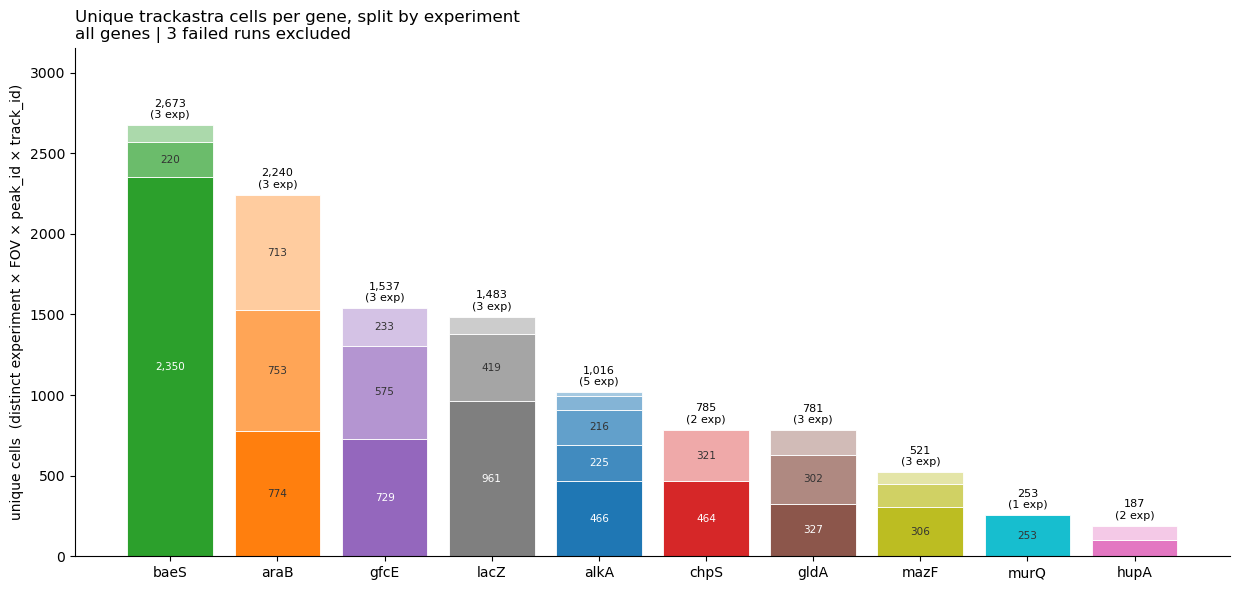

In [3]:
print(F.summarize_by_gene(cells).to_string())
F.fig_cells_per_gene(cells);

---
# 2 — Δy displacement QC

The pair table is built by stage 7, then annotated by section 11 of the 082026 notebook.
Regenerating it from scratch:

```bash
python 07_track_displacement_analysis.py --gene all \
    --pairs-csv data/track_pairs_082026.csv --fluor-method none \
    --out-dir notebooks/figures/summary_090326
```

Two pair populations are built, tagged by `pair_type` / `is_division`:

- **within_track** (70,444) — consecutive frames of one `track_id`, flagged at 1.0 × the mean
  `axis_major_length` of the two endpoints.
- **division** (10,558) — the parent's last frame against each daughter's first. Flagged at
  **1.5 × the parent's own length**: a real division displaces the centroid further than one
  frame of growth, since each daughter starts about a quarter of a parent length off the
  parent's centroid on top of the usual advection. These were previously not examined at all,
  so a mis-called division — or a fluorescence burst landing exactly on a division frame — was
  invisible.

This notebook pools the two, so the ±1.0 cutoff line drawn in the figures below is the
within_track threshold; the division rows are judged against 1.5 instead. The per-row value
actually applied is in `dy_threshold_cell_lengths`.

### The criterion: one cell length

A pair is flagged when
$$|\Delta y| > 1.0 \times \text{cell length}$$
where cell length is the mean `axis_major_length` of the two endpoints for a within_track pair
and the parent's own length for a division pair (median 36.6 px within_track, 53.8 px
division). The reasoning is physical: a tracking error means the track landed on a
**different** cell, and in a trench of stacked cells that takes roughly one cell length of
apparent motion. The data agrees — `|Δy| / cell_length` falls monotonically to a floor at ~1.0
and then flattens into a long tail out to 43×, so the threshold sits in the valley between
advection and hops. **1,456 of 81,002 pooled pairs (1.80%)** are flagged: 1,307 of 70,444
within_track (1.86%) and 149 of 10,558 division (1.41%).

`delta_fluor` differences `intensity_mean_fluor` straight from the CSV (`--fluor-method none`,
no image I/O) and stays in **raw a.u.** The exposure-normalised column is `delta_fluor_per_ms`,
which is what every figure below reads — `mmtrack.figures` defaults to it. Δy and the
cell-length ratio are spatial and are left alone.

### Joining a pair back onto a cell

Each row carries `from_track_id` / `to_track_id`, so either endpoint joins without the
`pair_type == 'within_track'` filter the old merge needed:

```
from = (experiment_name, FOV, trench_id, from_track_id, frame_from)
to   = (experiment_name, FOV, trench_id, to_track_id,   frame_to)
```

Do **not** merge on `time_frame`: it is NaN on all 11,576 division rows, which would drop every
one of them without a word. Keying both endpoints on `track_id` fails the same way — on a
division row `track_id` is the daughter while `frame_from` is the parent's frame. That was a live
bug in `mmtrack.track_displacement.apply_filtered_fluor`, now fixed at the source.

The cell-length rule is the only criterion stage 7 applies. It replaced a robust
median ± k·MAD window on Δy in pixels, which was not comparable across experiments: Δy is
advective, so its spread tracked the acquisition interval rather than the tracking error
rate.

In [4]:
# Per-experiment diagnostic. Grouped by acquisition interval as well as gene and experiment:
# Δy is advective, so its spread tracks the frame interval, which is exactly what the
# cell-length normalisation removes and what a pooled table would hide.
print(f'Per-experiment Δy   applied cutoff: |Δy| > 1.0× cell length (1.5× on division rows)\n')
dy_diag = F.dy_by_experiment(within)
print(dy_diag.to_string(index=False))
print('\nby acquisition interval:')
print(dy_diag.groupby('min_per_frame')
      .agg(n_experiments=('experiment_name', 'size'),
           median_cell_len=('median_cell_len', 'median'),
           median_flag_pct=('flag_pct', 'median')).to_string())

Per-experiment Δy   applied cutoff: |Δy| > 1.0× cell length (1.5× on division rows)

 min_per_frame gene                   experiment_name  n_pairs  median_cell_len  median_abs_dy_cl  flag_pct
             5 hupA               DUMM_giTG068_052925      951             46.1             0.090      0.32
             5 alkA DUMM_giTG63_giTG67_Glucose_121724     1871             33.3             0.180      0.64
             5 gldA        DUMM_giTG69_Glucose_013025     2671             38.5             0.153      0.86
             5 lacZ DUMM_giTG059_noKan_Glucose_031125     3524             38.3             0.162      0.91
            10 alkA           DUMM_giTG069_063_121225      109             42.6             0.127      0.92
             5 chpS        DUMM_giTG62_Glucose_012925     4306             37.4             0.105      1.18
            10 baeS          DUMM_gitg068_baeS_100225    13801             36.1             0.212      1.33
            10 gfcE           DUMM_giTG062_064_1213

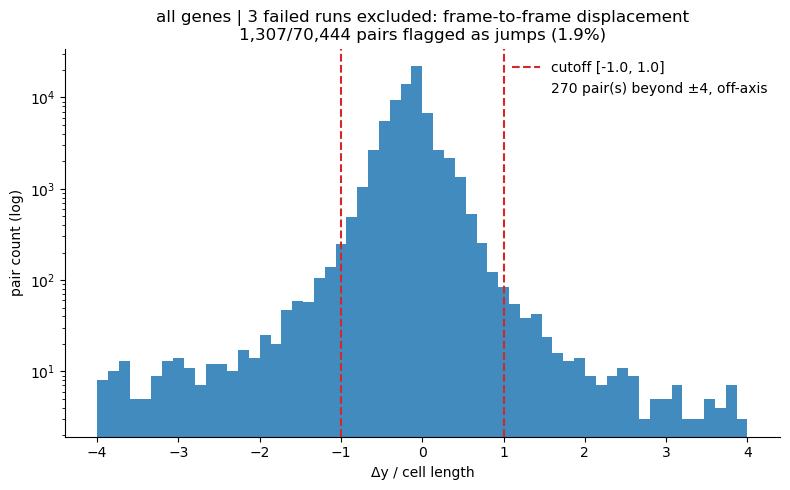

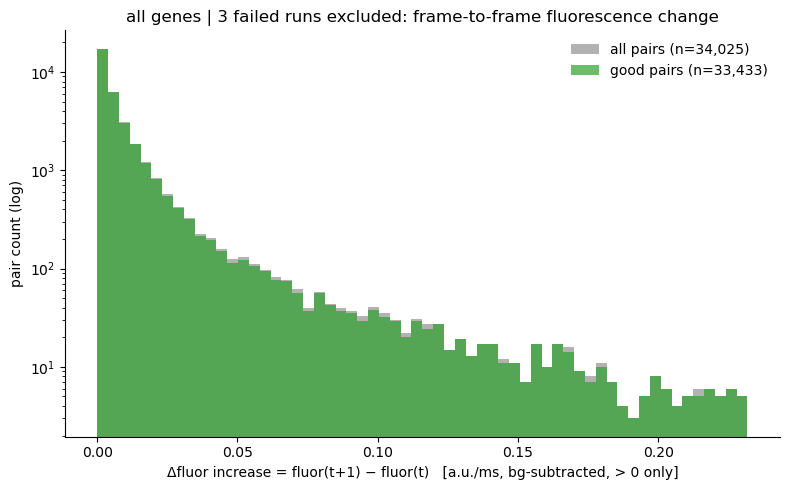

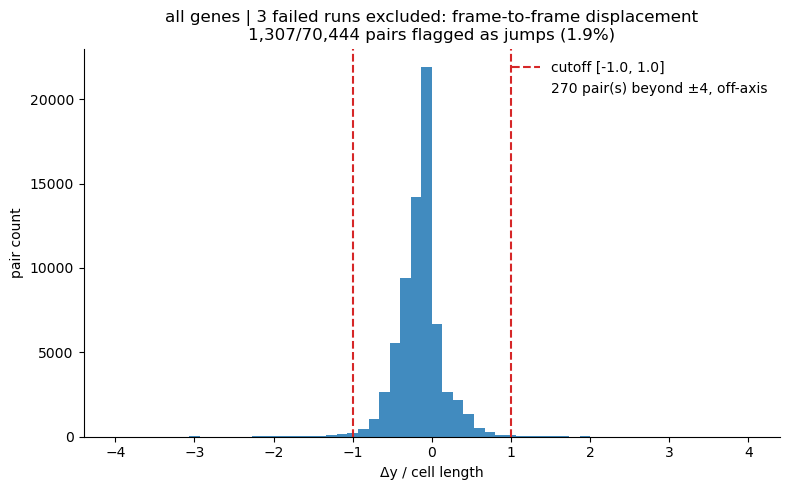

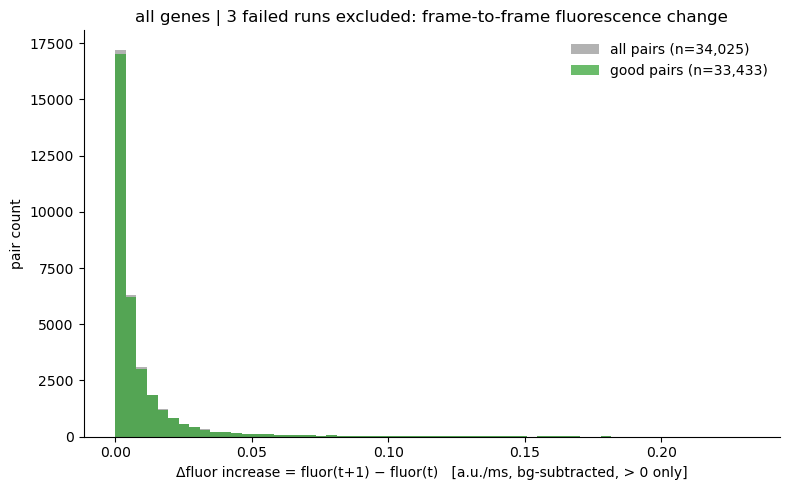

In [5]:
# Log first, then linear -- same data, same bins, same ±1.0 cell-length cutoff. On a linear
# count axis the flagged tail is a flat line, and the tail is the thing being looked at.
for _ys in ('log', 'linear'):
    F.plot_dy_histogram(within, yscale=_ys)
    F.plot_dfluor_histogram(within, good_within, yscale=_ys)

---
# 3 — Doubling time

**Definition.** A cell's doubling time is the span over which it was observed before it
divided:

$$T_d = (\text{last observed frame} - \text{first observed frame}) \times \text{minutes\_per\_frame}$$

taken over the **parent** track of every division event. Tracks are contiguous in this
dataset (`n_frames == last - first + 1` for all of them), so first/last is the whole story
and there is no gap to account for.

**The denominator is divisions, not lineages.** Every division event contributes exactly one
observation to the mean; there is no per-track or per-lineage pre-averaging, which would
otherwise let a trench with one long lineage outweigh a trench with twenty short ones.

**One division event == one parent track.** Checked both ways — from `all_data`
(`parent_track_id`) and from `pairs_all[is_division]` — and the two agree exactly: 5,279
events, every one with exactly two daughters, and no parent that divides twice. The pair
table carries one row per *daughter*, so the two rows per event are deduplicated to
`(experiment_name, FOV, trench_id, parent_track_id)` before averaging. A division with two
daughters is one doubling time, not two.

**Left truncation is reported, not filtered.** 11.4% of dividing parents were already present
at their first observed frame with no parent of their own — either the movie started
mid-cycle or the track begins at a tracking break. Their lifetime is cut short, so their
doubling time is an underestimate. Rather than pick one, every table carries both: the
all-divisions columns and the `*_birth_obs` columns restricted to events whose parent's own
birth was seen. The gap between them is the size of the bias (pooled: 65.9 vs 67.9 min).

**Two things to read as data quality, not biology.**

- `n_zero_dt` — divisions whose parent was observed in a single frame, giving $T_d = 0$.
  186 pooled (3.5%). Almost certainly a segmentation or tracking artefact rather than a cell
  that divided instantly. They are kept and counted rather than silently dropped, so the
  column is the readout; a `mean_dt_min` sitting next to a large `pct_zero_dt` is soft.
- `minutes_per_frame` **quantizes** the answer. 13 experiments run at 10 min and 7 at 5 min,
  so a 10-min experiment can only ever report multiples of 10. That is why the medians land
  on round numbers and why the per-gene dots below are coloured by acquisition interval.

`MIN_TRACK_FRAMES` is deliberately not applied here, for the same reason `scope_pairs`
skips it: a division event already implies its parent was tracked, so the filter would be
re-litigating a threshold the pair construction has already passed. `GENE`, `EXPERIMENTS`
and `FOVS` do apply, through the already-scoped `pairs`.
### Where the numbers come from

`division_events` lives in `mmtrack/lineage_stats.py` and is a pure function of the pair and
cell tables. Its output is cached to `data/divisions_082026.csv` on first run, so this section
is a read thereafter. It is deterministic — the cache is a convenience, not a source of truth.

`cells` must be passed **unscoped relative to `pairs`**: a min_frames-filtered frame drops short
parent tracks and trips the "lost their parent rows" assert. The scope is carried by `pairs`.

In [6]:
# Cached: division_events is deterministic and takes ~1 s, so the CSV is a convenience.
# Delete it to recompute.
if os.path.exists(DIVISIONS_CSV):
    divisions = pd.read_csv(DIVISIONS_CSV, dtype=F.READ_DTYPES)
    divisions['FOV'] = divisions['FOV'].str.zfill(3)
    print(f'read {os.path.basename(DIVISIONS_CSV)} ({len(divisions):,} divisions)')
else:
    divisions = division_events(pairs, cells)
    divisions.to_csv(DIVISIONS_CSV, index=False)
    print(f'wrote {os.path.basename(DIVISIONS_CSV)} ({len(divisions):,} divisions)')

print(f'{len(divisions):,} divisions | '
      f'{int(divisions.has_jump.sum()):,} with a Δy jump in the dividing cell '
      f'({100 * divisions.has_jump.mean():.2f}%) | '
      f'{int((~divisions.has_jump).sum()):,} clean')
print(f'  birth observed: {int(divisions.birth_observed.sum()):,} '
      f'({100 * divisions.birth_observed.mean():.1f}%) | '
      f'zero-length parents: {int((divisions.doubling_min == 0).sum()):,} '
      f'({100 * (divisions.doubling_min == 0).mean():.1f}%)')
print(f'  pooled mean {divisions.doubling_min.mean():.2f} min | '
      f'median {divisions.doubling_min.median():.1f} min')

read divisions_082026.csv (5,279 divisions)
5,279 divisions | 389 with a Δy jump in the dividing cell (7.37%) | 4,890 clean
  birth observed: 4,676 (88.6%) | zero-length parents: 186 (3.5%)
  pooled mean 65.87 min | median 60.0 min


Average doubling time per experiment

                                        gene  min_per_frame  n_div  mean_dt_min  median_dt_min  sd_dt_min  sem_dt_min  n_div_birth_obs  mean_dt_birth_obs  median_dt_birth_obs  n_zero_dt  pct_zero_dt
DUMM_giTG059_068_SC_093025              lacZ           10.0    453        85.43           80.0      54.24        2.55              417              87.91                 80.0         12          2.6
DUMM_mazF_murQ_121625              mazF+murQ           10.0    249        73.41           70.0      40.29        2.55              205              77.02                 70.0          7          2.8
DUMM_gitg068_baeS_100225                baeS           10.0   1118        72.84           70.0      40.25        1.20             1036              74.72                 70.0         27          2.4
CL008_giTG068_072925                    araB           10.0    363        69.20           60.0      44.29        2.32              334              69.73             

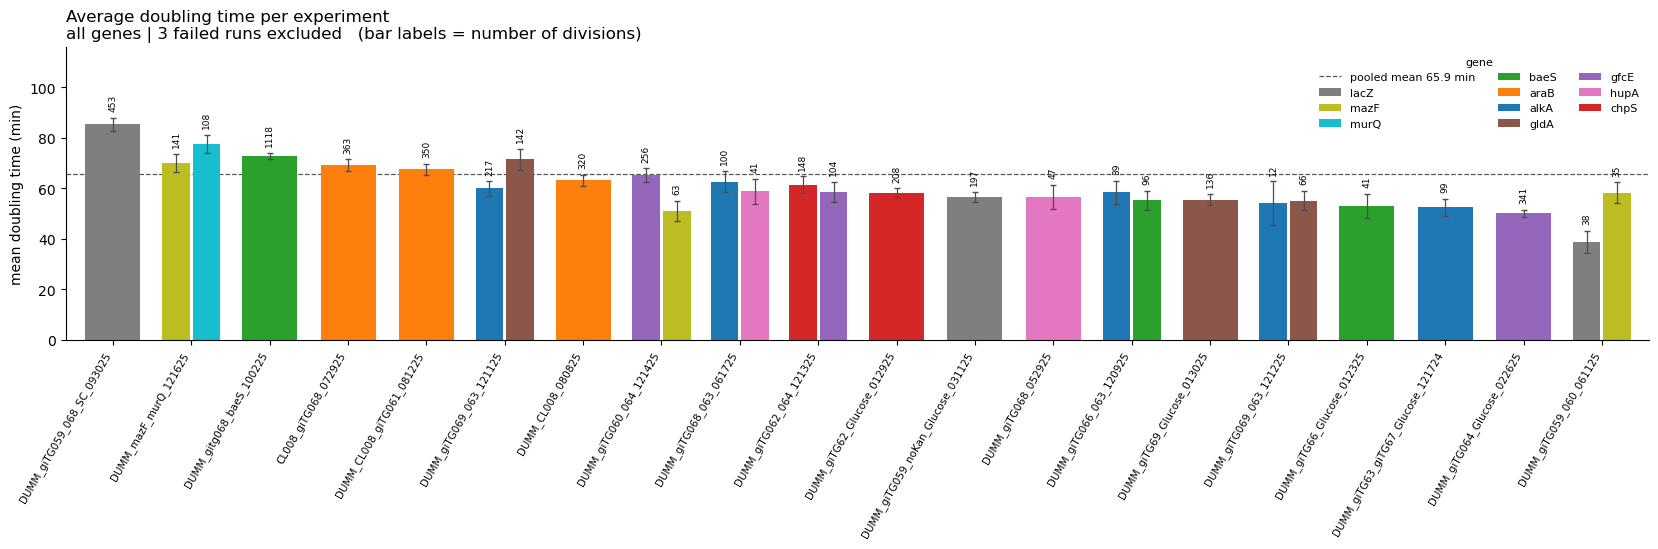

In [7]:
print('Average doubling time per experiment\n')
print(doubling_by_experiment(divisions).round(2).to_string())
F.plot_doubling_by_experiment(divisions, 'Average doubling time per experiment',
                              'doubling_per_experiment');

Average doubling time per gene

       n_experiments  n_div  mean_dt_min  median_dt_min  sd_dt_min  sem_dt_min  mean_of_exp_means  min_exp_mean  max_exp_mean  n_div_birth_obs  mean_dt_birth_obs  median_dt_birth_obs  n_zero_dt  pct_zero_dt
murQ               1    108        77.59           70.0      36.81        3.54              77.59         77.59         77.59               83              82.53                 80.0          2          1.9
lacZ               3    688        74.62           70.0      49.30        1.88              60.34         38.95         85.43              618              77.40                 70.0         19          2.8
baeS               3   1255        70.85           60.0      40.21        1.14              60.41         53.17         72.84             1150              72.99                 70.0         33          2.6
araB               3   1033        66.77           60.0      42.90        1.33              66.64         63.22         69.20              9

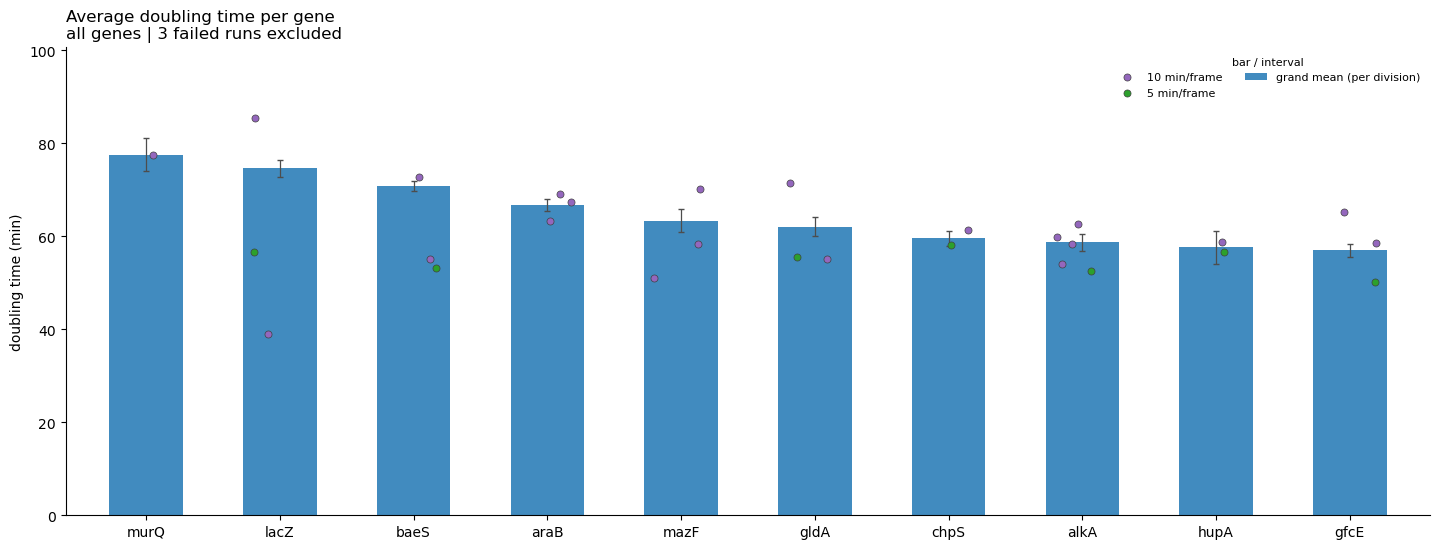

In [8]:
dt_by_gene, dt_per_exp = doubling_by_gene(divisions)
print('Average doubling time per gene\n')
print(dt_by_gene.round(2).to_string())
F.plot_doubling_by_gene(dt_by_gene, dt_per_exp, 'Average doubling time per gene',
                        'doubling_per_gene')

# The jump filter is reported, not applied: it keeps 92.6% of divisions, moves the pooled mean
# 65.87 -> 65.01 min, and leaves the gene ranking unchanged. Not worth a second set of figures.
_clean_ev = divisions[~divisions.has_jump]
print(f'\njump-filtered: {len(_clean_ev):,} of {len(divisions):,} divisions '
      f'({100 * len(_clean_ev) / len(divisions):.1f}%), '
      f'pooled mean {_clean_ev.doubling_min.mean():.2f} min '
      f'(vs {divisions.doubling_min.mean():.2f} unfiltered)')

# 4 — Fluorescence per gene

### Does the linear-exposure assumption hold? — read this before quoting the figure

Dividing by `fluor_exposure_ms` assumes the detector responds linearly across 150–500 ms. That is
an assumption, not a measurement, and the data only half-supports it. The check below compares
each gene's **replicate spread** — max/min of its per-experiment means — before and after
normalising. If exposure were the dominant difference between a gene's experiments, normalising
would shrink it.

| | genes (raw fold → per-ms fold) | reading |
|---|---|---|
| **shrinks** | araB 2.96 → 1.07, lacZ 3.27 → 1.18, baeS 17.6 → 5.28 | exposure really was the confounder — and these are the genes with several replicates genuinely spread across settings |
| **unchanged** | mazF 1.97 → 1.97, murQ (one experiment) | only one exposure among the replicates that differ |
| **grows** | alkA 2.23 → 7.42, gldA 1.10 → 3.66, hupA 1.03 → 3.08, gfcE 1.34 → 2.87, chpS 1.20 → 2.77 | their raw means already agreed across different exposures, so dividing pulls them apart |

**Why the second row is not simply a refutation.** For those genes exposure is almost perfectly
**confounded with experiment**: all but one replicate sits at 150 ms and the odd one out at 450 or
500 ms, so "the 500 ms run" and "that particular acquisition" are the same thing, and no
arithmetic separates them. alkA is the clearest case — its 500 ms run has a *lower* raw mean
(7.5) than three of its four 150 ms runs (7.7–16.7), which a linear detector cannot produce at
equal expression. Either those cells were genuinely dimmer, or the response is not linear over 3×.

**It is not sensor saturation.** The largest single pixel anywhere in the filtered dataset is
**2,432 counts**, nowhere near any plausible ADC ceiling, and hupA — the brightest gene, and the
one whose raw means match across a 3× exposure change — tops out there rather than clipping flat.

**What to do with it.** Quote Figure 6 for the cross-gene ranking, which is what it is for and
which the rank table shows is barely affected. Do **not** read a 2–3× difference between two
experiments of the *same* gene as biology. And note that none of this reaches the burst results:
those are relative to each `(gene, experiment)`'s own noise, so they are identical either way.

raw intensity_mean_fluor per gene — reference only

      n_experiments  n_rows  grand_mean  mean_of_exp_means  min_exp_mean  max_exp_mean  fold_range
gene                                                                                              
hupA              2    1542     606.472            609.335       601.536       617.133       1.026
mazF              3    3240      54.869             66.854        40.593        80.120       1.974
chpS              2    6662      25.977             24.979        22.668        27.289       1.204
baeS              3   18255      24.314             90.380        13.507       237.782      17.604
alkA              5    6978      11.840             11.462         7.519        16.736       2.226
gldA              3    5871      10.909             11.089        10.479        11.503       1.098
murQ              1    1776       8.210              8.210         8.210         8.210       1.000
gfcE              3   11505       8.093              7.61


replicate spread (max/min of per-experiment means), raw vs normalised:

        raw  per_ms     effect
gene                          
alkA   2.23    7.42      GROWS
baeS  17.60    5.28    shrinks
gldA   1.10    3.66      GROWS
hupA   1.03    3.08      GROWS
gfcE   1.34    2.87      GROWS
chpS   1.20    2.77      GROWS
mazF   1.97    1.97  unchanged
lacZ   3.27    1.18    shrinks
araB   2.96    1.07    shrinks
murQ   1.00    1.00  unchanged


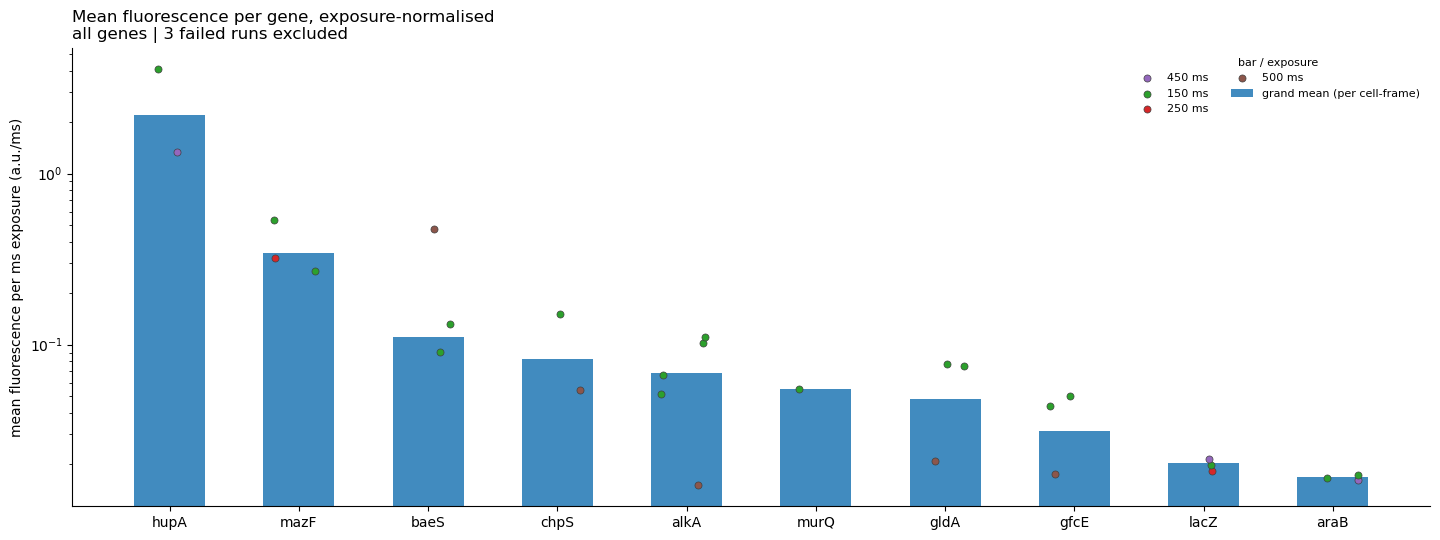

In [9]:
# Reference only, not plotted: a raw bar chart pools genes measured at 150 and 500 ms on one
# axis, so a brighter bar can mean a longer exposure rather than a brighter cell.
raw_summary, _ = F.fluor_by_gene(cells, value_col=F.RAW_FLUOR_COL)
print(f'raw {F.RAW_FLUOR_COL} per gene — reference only\n')
print(raw_summary.round(3).to_string())

norm_summary, norm_per_exp = F.fluor_by_gene(cells)
print(f'\nexposure-normalised ({F.FLUOR_COL}) per gene\n')
print(norm_summary.round(5).to_string())
F.plot_fluor_bars(norm_summary, norm_per_exp, F.FLUOR_LABEL,
                  'Mean fluorescence per gene, exposure-normalised', 'fluor_per_gene')

# Does normalising shrink or grow each gene's replicate spread? If exposure were the dominant
# difference between a gene's experiments, dividing it out would shrink every fold_range.
_cmp = pd.DataFrame({'raw': raw_summary['fold_range'],
                     'per_ms': norm_summary['fold_range']}).dropna()
_cmp['effect'] = np.where(_cmp.per_ms < _cmp.raw * 0.9, 'shrinks',
                          np.where(_cmp.per_ms > _cmp.raw * 1.1, 'GROWS', 'unchanged'))
print('\nreplicate spread (max/min of per-experiment means), raw vs normalised:\n')
print(_cmp.round(2).sort_values('per_ms', ascending=False).to_string())

---
# 5 — One trench at a time

The tooling for looking at a single kymograph. Every function takes the same
`(experiment_name, FOV, trench_id)` triple and tolerates int-or-str for the last two, since both
are strings in the tables but read as integers.

`plot_track_fluorescence` colours tracks by **tab20 position in the sorted track list**, matching
`build_track_color_map()` in `generate_kymograph_viewer.py` — so a line here is the same colour
as that track in the HTML viewer. That is deliberately *not* the pinned tab10 gene palette used
by every cross-gene figure.

`plot_trench_deltas` draws the trench over a grey backdrop of its whole experiment, so the
question it answers is "is this trench unusual *for its own acquisition*". A trench is a median
~5–9% of its experiment's pairs, hence the log count axis by default; pass `yscale='linear'` for
the view where the bulk is legible instead of the tail.

DUMM_giTG059_060_061125 FOV 008 trench 1488: 409 pairs | 98 tracks | median cell length 39.6 px  (experiment backdrop: 747 pairs)



top 10 pairs by fluorescence INCREASE  (a.u./ms per frame, 10 min/frame)
 track_id  frame_from  frame_to  time_min_from  fluor_per_ms_from  fluor_per_ms_to  delta_fluor_per_ms  delta_y  delta_y_cell_lengths predicted_lineage
        8          11        12            110              0.039            0.063               0.024   -1.014                -0.029               5.1
        3           4         5             40              0.007            0.029               0.023   11.275                 0.293               2.1
       44          52        53            520              0.015            0.034               0.019  -13.829                -0.334          10.2.1.2
        8          10        11            100              0.021            0.039               0.018   11.065                 0.176               5.1
       42          48        49            480              0.015            0.032               0.017 -128.131                -0.393              12.2
       89     

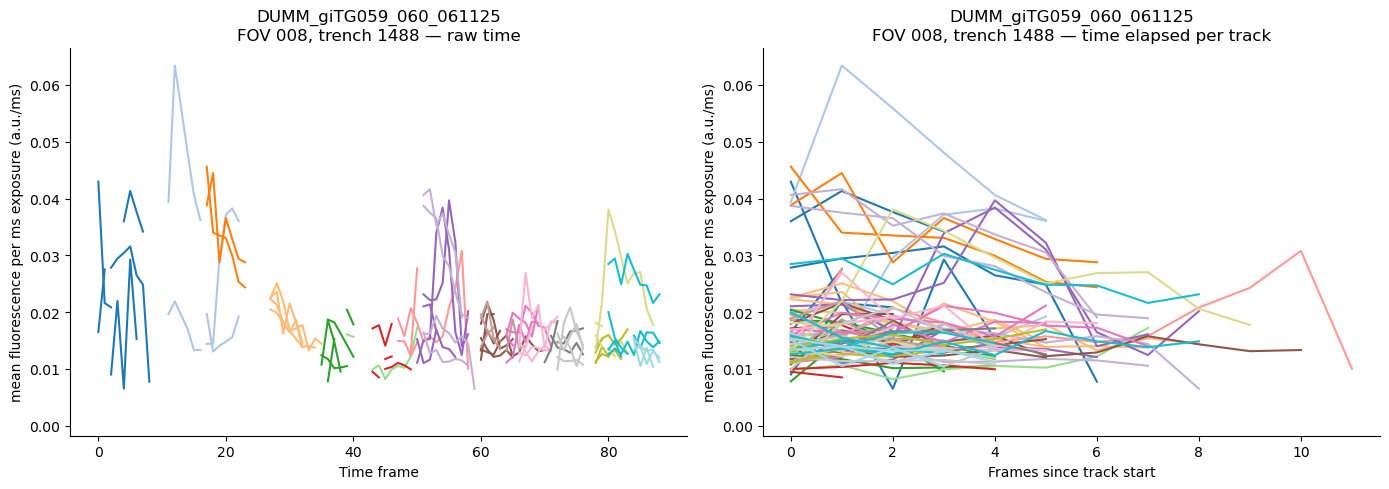

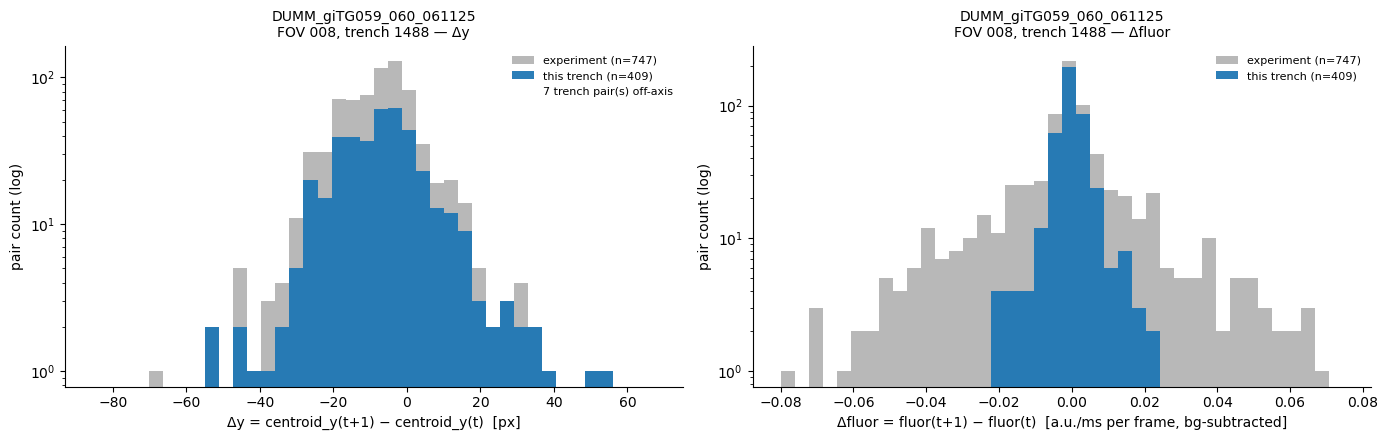

In [10]:
# The worked example: two concurrent bursts in one trench, which is what motivated the v2
# per-lineage-family envelope. Change these three to look at any other trench.
EX_EXP, EX_FOV, EX_PEAK = 'DUMM_giTG059_060_061125', '008', '1488'

F.plot_track_fluorescence(cells, EX_EXP, EX_FOV, EX_PEAK)
F.plot_trench_deltas(pairs, EX_EXP, EX_FOV, EX_PEAK, top_n=10);

---
# 6 — Bursts in expression

A **burst** is a cell sitting dark and then jumping sharply in fluorescence. The reference case
is `CL008_giTG068_072925 | FOV 003 | trench 1598 | track_id 12` (araB): flat at ~0.021 a.u./ms
for frames 31–36, then **0.0192 → 0.0539 → 0.0758** at frames 36–38, peaking at **0.0763** at
frame 39 and decaying slowly to 0.0410 by frame 55 as the cell grows.

**The acceptance test is `mazF`, `hupA`, `chpS`.** These are constitutive — always expressing,
high fluorescence — so a correct definition must score them near zero. This is what makes the
problem non-trivial, because they are also the *brightest* genes in the set: any rule keyed on
absolute fluorescence ranks them first.

### Why the obvious definitions fail

Fluorescence is a mean pixel value per ms of exposure. Median baseline still runs from
0.0141 a.u./ms (alkA) to 3.99 (hupA) — a **283×** spread — because normalising removes the
exposure term but not the expression level, which is the bigger one. (It is wider than the 218×
of the raw units for the reason section 5 sets out: for several genes exposure is confounded
with experiment.) So **an absolute Δ cutoff is still not comparable across genes**: any threshold
that catches the araB burst (Δ = +0.057 a.u./ms from baseline to peak) fires on every hupA wobble.

**Fold change** (`F(t+1)/F(t) ≥ K`) cancels the units, but divides by a small number: **865 of
the 81,002 pairs** start from an `F(t)` below 20% of their own `(gene, experiment)` median, and
one is exactly 0. A prototype using fold ≥ 2 **and** a robust
z ≥ 5 still failed the control (mazF 3rd of 10), because it counts one episode once per cell:
mazF trench 1768 registered 4 times — tracks 7/8/8/11 at frames 18/21/23/27 — for a single
burst propagating through a lineage.

### What this section uses instead

Detection runs on a **max-fluorescence envelope** — the brightest cell at each frame — which
makes an inherited burst one smooth hump instead of one event per descendant, and requires
**prominence** rather than height. As of **v2** the envelope is taken per **lineage family**
rather than per trench, so two bursts running at once in one trench are not masked by whichever
is brighter; concurrent events in adjacent cells are then merged back together. Prominence is a peak's height above the highest
saddle you must descend before reaching higher ground on either side. A flat-high trace clears
any height bar but has near-zero prominence — *this is the criterion that zeroes the
constitutive genes.*

Thresholds are robust: `median + k · 1.4826 · MAD`, where `MAD = median(|x − median x|)`.
Unlike a standard deviation, MAD is not squared-error based, so one 400 a.u. spike cannot
inflate it. The 1.4826 factor is 1/Φ⁻¹(0.75), which rescales MAD so that on clean Gaussian
noise "k MAD-scales" means the same as "k sigma" — `k` stays interpretable in familiar units
without being wrecked by the very outliers being hunted.

Ported from `notebooks/trackastra_figures.ipynb` cell 26, with every fix and every later
change recorded in the changelog below. **Read the changelog before trusting a number** — the
active definition is whatever `BURST_DEF` points at, and each output table carries its
`def_version`.

### Definition changelog — append only

The definition will change. Add a new version below and a new `BURST_DEF_V*` dict; **do not
edit an old one in place.** Every output table carries a `def_version` column so a saved result
can always be traced to the rule that produced it.

---

**v1** — 2026-08-24. Initial port from `notebooks/trackastra_figures.ipynb` cell 26.

A frame on a trench's max envelope is a burst when all three hold:

1. **Height** — `fluor > median + k · 1.4826 · MAD`, taken per **(gene, experiment_name)**.
2. **Local peak** — the maximum within ±`window` frames.
3. **Prominence** — rise ≥ `k · mad_scale`. The criterion that zeroes the constitutive genes.

Then **episode merge**, so a slow decay counts once: walking peaks in time, a later peak opens
a new burst only if the envelope first drops back below threshold, or climbs above the previous
peak + prominence. The araB example collapses to a single burst at frame 39.

Fixes applied during the port, all confirmed against the data:

- **Baseline keys are `(gene, experiment_name)`, never experiment alone.** 10 of the 23
  experiments hold two genes, so experiment-only scaling makes a dim and a bright gene share
  one noise ruler. Scaling per experiment alone put chpS at 1.72 per 1000 pairs; per
  gene×experiment it drops to 0.92. Do not "simplify" this.
- **FOV dtype.** The original `plot_bursts_for_trench` did `fov = int(fov)`, which matches
  nothing against this notebook's zero-padded string FOVs. Now routed through `select_trench`.
- **`node_id`** was added to `SUMMARY_COLS` in section 1 — `detect_bursts` records it, and it
  is in the CSV but was not being loaded.

Known quirk, measured not guessed: **`window` is inert while prominence is on.** 80 bursts at
every `window` from 1 to 8, with the reference trenches unchanged; it only begins to bite at
`window` = 12 (77 bursts). It is a fallback that prominence makes redundant — with prominence
disabled `window` does matter (250 bursts at 1, 167 at 5, 151 at 8), which is presumably the
regime it was originally tuned in. Leave it alone and tune `k`.

**Prominence is the load-bearing criterion.** Disabling it at `window` = 5 takes the count from
80 to 167 and breaks the constitutive control: hupA goes from 0.00 to 1.32 bursts per 100 cells,
last place to 5th of 10. Height alone cannot separate constitutive from bursty — `hupA` sits at
~598 a.u. permanently and clears any absolute bar.
---

**v2** — 2026-08-24. **Detects concurrent bursts.** Signal changes from one envelope per trench
to one per **lineage family**, followed by a merge step. `k`, `window` and the baseline rule are
unchanged from v1.

*What v1 got wrong.* `trench_max_envelope` is a scalar max per frame, so two bursts running at
once in one trench collapse into a single hump and the dimmer one is masked. The case:
`DUMM_giTG059_060_061125 | FOV 008 | trench 1488`, frames 50–59, holds two real bursts —

- **A**: track 41 rises at frames 49–50 and divides at 51 into 49 + 50, both daughters carrying
  the protein. Peak 10.41 at frame 52. *v1 counts this once, correctly — inheritance is not a
  new burst.*
- **B**: tracks 44 and 45, two adjacent cells nearer the open end, peaking 9.60 / 9.92 at frames
  54–55. At frame 55 the cells sort by `centroid_y` as `45@88, 44@121, 43@172, 50@217, 49@263` —
  a **dark** cell (43, F = 3.4) separates the two bright regions, so they are plainly distinct.

v1 reported **one** burst there. Burst B's peak has a measured prominence of **0.78** against the
required 4.38, because burst A is still at 9.14 at frame 53 and leaves no saddle between them.

*Why the merge step is needed too.* Per-family detection alone over-splits: tracks 44 and 45 sit
in different lineage families (roots 30 and 31), so burst B gets counted twice. Two events are
treated as one burst when their peaks are within `merge_window` frames **and** their centroids are
within `merge_gap_cell_lengths`. The gap is in **cell lengths**, not pixels, for the same reason
`flag_jumps` uses them (`mmtrack/track_displacement.py`) — the unit is independent of
magnification and cell size. It is an insensitive choice: 1.5, 2.0 and 2.5 all give 95, because
the 7 concurrent pairs in this dataset sit at ≤ 1.06 or ≥ 2.77 cell lengths, with 44/45 at 1.41.

`merge_keep='earliest'` reports the **onset** of a merged burst, so timing is not biased late by
whichever neighbour happened to peak brighter. Burst B is therefore reported at frame 54, not 55.

*Effect.* 80 → 100 bursts from per-family detection, then → **95** after merging 5 of the 7
concurrent pairs. The `TOTAL` count and every rate change accordingly; `gldA` moves 6th → 3rd
(0.38 → 0.90 per 100 cells) and `alkA` 3rd → 5th. araB, murQ and all three constitutive genes are
unchanged. Run the merge-audit cell to see every concurrent pair and its verdict.

*Regression checks that must keep passing.* The FOV 007/821 fragmentation case still yields
exactly 1 burst — all six of the tracks the tracker split that cell across land in one lineage
family, and the spatial merge is a second safety net when they do not. Trench 003/1598 still
yields 1 at frame 39.

*Caveat, measured not guessed.* v2 is more sensitive than v1 at low `k`: at `k = 2.0` chpS climbs
to 3rd of 10 (5th under v1), so the constitutive control is not clean down there. At the shipped
`k = 4.0` chpS is 7th and mazF is 10th at every `k` from 2 to 6. Also note the concurrent pair in
trench 1488 disappears at `k = 6.0` — both bursts fall under the height threshold.

---

**Units change — 2026-09-01.** Not a new definition: `BURST_DEF_V1['fluor_col']` moved from
`intensity_mean_fluor` (raw a.u.) to `fluor_per_ms` (a.u./ms), and v2 and v3 inherit it. **Every
number in the v1 and v2 entries above is in the raw a.u. of the run that measured it and has not
been rewritten** — divide by that experiment's `fluor_exposure_ms` to compare with a current
table (150 ms for the araB reference trench, 250 ms for trench 1488).

*Why this is a units change and not a definition change.* `fluor_exposure_ms` is constant within
an experiment and `compute_baselines` groups by `(gene, experiment_name)`, so the median, the
MAD scale, the height threshold and the required prominence all scale by the same 1/E. Every
criterion is a comparison between quantities that scaled identically, so no verdict can move.
Verified empirically rather than argued: re-running the full pipeline after the switch gives the
same **94** events with the same per-gene counts (lacZ 35, araB 22, gfcE 14, alkA 9, gldA 7,
baeS 4, chpS 2, murQ 1, hupA 0, mazF 0), the same 7-row merge audit, and a bit-identical k-sweep
table.

**Failed runs excluded at load — 2026-09-01.** Also not a definition change. The three failed
acquisitions are dropped in section 2, so detection now runs on 20 experiments rather than 23.
Equivalent to filtering the old full-dataset burst table, for the same baseline-grouping reason:
**95 → 94**, the lost event being the marginal chpS burst in `DUMM_alkA_chpS_111325`. One
consequence for the v2 entry above: its *caveat* about chpS climbing to 3rd of 10 at `k = 2.0`
was measured on the unfiltered frame. On the filtered frame chpS is **6th** at `k = 2.0` and
5th at `k = 3.0`, so the control is better behaved at low `k` than that entry warns.

---

**v3** — 2026-08-24, back-filled into this changelog on 2026-09-03. It was originally written
up only in section 9 of the closed `trackastra_figures_082026.ipynb`, so the append-only record
skipped from v2 straight to the units change. Recorded here because "there is no v3 entry" is
indistinguishable from "v3 was never applied", and every table in this notebook is stamped v3.

Two parts:

1. **Signal** becomes per **lineage family × spatial cluster**. Inside one family, cells are
   clustered per frame by gaps along `centroid_y` exceeding `split_gap_cell_lengths` = 1.5, and
   the clusters are linked across *consecutive* frames that **share a cell** (same `track_id`,
   or a parent→daughter pair). Union-find over `(frame, cluster)` gives groups that survive
   drift.
2. **An input filter, applied before every definition** — not part of any version's rule,
   the same status as the failed-run exclusion. Drop cell-frames with
   `area < 0.05 × that experiment's own median area`. Sorted burst-cell areas were
   `[1, 1, 1, 2, 2, 117, 131, …]`: only 0.11% of cell-frames are ≤ 5 px² yet 5 of 95 v2 bursts
   landed on them, a 48× enrichment. On a 1-pixel mask the mean intensity is one raw pixel with
   no averaging. The floor is **relative** because `DUMM_giTG66_Glucose_012325` was recorded at
   ~⅓ the linear pixel scale of every other run; an absolute 50 px² floor deleted 749 of its
   844 perfectly good cell-frames, the relative floor drops 121 across the dataset of which 1.

*Headline result: v3 is a no-op.* **v3 finds exactly the same 89 bursts as v2** — `v3 \ v2 = 0`
and `v2 \ v3 = 0`, every per-gene rate identical. Recorded rather than hidden, because the
reason is informative: v2's blind spot is real (32 co-bright, spatially separated cell pairs sit
inside a single lineage family, and 22% of trenches are one family where v2 degenerates to v1),
but every way of splitting on position hits the same wall. Splitting by cluster mean centroid
*shatters* the signal (median envelope 2 frames, 52% of units under 3 frames and so unusable by
`find_peaks`); linking by shared cell identity is coherent but **re-joins whatever position
split**, because cells in a trench are physically contiguous; splitting at a dark cell instead
of a geometric gap gives 80, worse than v2. The v2 partition is at a local optimum for this
data.

Also recorded: `link_gap_cell_lengths` was declared in `BURST_DEF_V3` and **read by nothing**
(`add_spatial_subgroup` links on identity, not position — that was the abandoned variant). It
was deleted on 2026-09-03.

*Effect on the area floor alone:* v1/v2/v3 go from 79/94/94 to **73/89/89**.

---

**v4** — 2026-09-03. **Decouples the height bar from the prominence bar.** Signal, baseline
rule, `window`, both merges and the area floor are unchanged from v3. `k = 4.0` still sets the
height threshold; a new `k_prom = 3.7` sets the required prominence.

*What v1–v3 got wrong.* One `k` did double duty — `height = median + k·s` **and**
`required prominence = k·s` — and the two had never been tested apart. They are not the same
quantity: height asks "is this bright" and prominence asks "did it rise", and there is no
reason the same multiplier is right for both.

*The motivating case.* `DUMM_giTG062_064_121325 | FOV 010 | trench 1188` (chpS), track 23 at
frame 25: 0.186 → **0.392** → 0.392 → 0.300 → 0.135 a.u./ms. It clears height at **5.38 s**,
is a local maximum, and fails prominence at **3.851 s against a bar of 4.0 — short by 3.7%**.
The binding side is the **right** base (0.2128 at frame 38, against a left base of 0.1100 at
frame 2): after frame 26 the envelope never returns to baseline before the recording ends at
frame 40, because other cells of the same 39-track family stay bright (13 @27, 17 @28–30,
26/27 @31–33, 31/32/39 @34–40). v2 and v3 are both no-ops in that trench — 39 of 43 tracks are
one family, and the cells are packed 0.89–1.19 cell lengths apart, under v3's 1.5 split gap.

*Why 3.7, measured.* Lowering only the prominence bar has a **plateau at `k_prom` ∈ [3.6, 3.8]**
that catches the case and leaves both hard controls at exactly zero:

| `k_prom` | bursts | 010/1188 | chpS | hupA | mazF |
|---|---|---|---|---|---|
| 4.0 (v3) | 89 | missed | 0.26 | 0.00 | 0.00 |
| 3.9 | 91 | missed | 0.26 | 0.00 | 0.00 |
| **3.8 – 3.6** | **97 – 101** | **caught** | 0.51 | **0.00** | **0.00** |
| 3.5 | 107 | caught | 0.51 | **0.54** | 0.00 |

hupA's brightest candidate sits at **3.586 s**, which is exactly where 3.5 breaks. 3.7 is the
middle of the plateau, so the bar is not tuned to the single event that motivated it — but the
guard band is genuinely narrow (3.851 vs 3.586, a 7% gap), and that gap is the honest limit of
this signal. See section 8e for why *widening* it by changing the prominence rule does not work.

*Effect.* 89 → **99** events. 11 gained, all from the 0.93–1.00 band of the near-miss census;
`hupA` and `mazF` stay at 0.00 and `mazF` stays 10th of 10. Per 100 cells: lacZ 2.26→2.39,
gfcE 0.92→0.98, araB 0.85→0.94, chpS 0.26→0.51, baeS 0.15→0.26; alkA, gldA and murQ unchanged.

*One behaviour change to expect.* A burst's reported frame can shift **earlier**. In
`DUMM_giTG066_063_120925 007/874` v3 reported one event at frame 9 (prominence 5.11) while v4
reports frames 8 and 13: the lower bar admits the rising shoulder at frame 8 as the episode's
first candidate, and `merge_keep='earliest'` then reports the onset rather than the peak. That
is the existing rule acting on a larger candidate set, not a lost event — the trench nets +1.

*Regression checks that must keep passing.* 003/1598 → 1 at frame 39; 007/821 → 1;
008/1488 → 4 including frames 52 and 54. All hold at every `k_prom` from 4.0 to 3.6.

*Not shipped yet.* `BURST_DEF` still points at v3, so every table above this section is
unchanged. Section 8h lists the 11 newly caught events for eyeballing in the viewer first.

---

**v5** — 2026-09-03. **Adds a second ROUTE, rather than moving a bar.** Signal, baseline rule,
`window`, both merges and the area floor are unchanged from v4, and the whole v4 rule is kept
verbatim as the "absolute" route. A new **fold** route admits a peak whose
`peak / max(left_base, right_base)` reaches `fold_prom = 3.3`, provided it also sits at least
`fold_height_floor_s = 1.0` MAD-scales above the gene median.

*What v1–v4 got wrong.* Every gate was **absolute within a gene**: a peak had to clear
`median + k·s` for its (gene, experiment). So a trench whose entire envelope sits below its
gene's median can never register a burst, however dramatic the excursion inside it. Measured,
**146 of 255 trenches (57%)** are in that position, and **36 of them contain a ≥ 2.5× internal
fold rise** — gldA 42% of its trenches, gfcE 27%, chpS 20%, alkA 17%. That is a systematic
under-count, not a handful of edge cases.

*The motivating case.* alkA `DUMM_giTG069_063_121125 | FOV 001 | trench 1192`. Its `time_dict`
`start` is 24, so what the viewer labels frames 26–30 is `time_frame` **2–6**, where `track_id
2` climbs 0.0503 → 0.1755 a.u./ms — a **3.5× rise**. It produces **zero height-clearing
candidates** under v3 *and* v4, so prominence is never even evaluated:

| gate | value | bar |
|---|---|---|
| height | **1.91 s** above the alkA × experiment median | 4.0 — fails by 52% |
| MAD-prominence | 3.005 s | 3.7 — fails |
| **fold** | **3.60×** | vs 3.64× for the reference araB burst |

The trench is `eligible = False, headroom = −2.09 s`; its envelope tops out at 0.1907 against a
bar of 0.2864, while every alkA burst that *is* counted in that experiment sits at 0.30–0.39. A
per-kymograph baseline does not rescue it either (3.14 local s, still under 4.0) — measured,
not argued.

*Why fold, and why 3.3.* The ratio is **unit-free**, so one bar serves a 283× spread of gene
brightness with no baseline at all, and it is a *relief* measure, so a flat-high constitutive
trace scores ~1.0. Over all 1,941 local maxima on the family envelopes the three controls top
out at **hupA 1.76×, mazF 2.94×, chpS 3.10×**, against 3.60× for the case above. The safe
window is therefore `(3.10, 3.60]` and **3.3 is its midpoint** — about 7% clear on each side.
That band is narrow, and it is the honest limit of the criterion: quote it with the number.

*Fold cannot replace the absolute rule.* With the absolute bar made unreachable the fold route
alone finds **48** events and **fails the 008/1488 regression** (0 of the 4 expected), because
it misses the bright canonical bursts. It can only ever be a second route. (An earlier estimate
of 67 came from an approximate harness with a looser episode merge; 48 is the figure from the
shipped detector, and section 8i recomputes it on every run.)

*Effect.* 99 → **118** events: **99 absolute + 19 fold**, and **v5 is a strict superset of
v4** — no v4 event is lost. Per 100 unique cells: **gldA 0.90 → 1.93** (8 of its 15 events come
via fold), alkA 0.89 → 1.28, gfcE 0.98 → 1.31, lacZ 2.39 → 2.46, araB 0.94 → 0.99. chpS, murQ,
baeS, hupA and mazF are **unchanged**, `hupA` and `mazF` stay at exactly 0.00, and `mazF` stays
10th of 10.

**gldA moves 4th → 2nd, and that is the substantive consequence.** gldA had only 32% trench
eligibility, so its old rate was as much a statement about opportunity as about biology. Do not
quote the new ranking without section 8f's coverage table beside it.

*Two merge interactions this needed, both found by testing rather than by inspection.*

- The **episode merge** reopens an episode when the envelope drops back below `height`. A fold
  episode's envelope never reaches `height`, so that test is always true and every wobble on
  the decay would open a new burst. A fold episode now resets when the envelope falls below
  `peak_prev / fold_prom` instead. **Measured inert on this dataset** (118 events either way),
  like `window` — kept because a long dim decaying hump is exactly what it guards.
- Both merges now prefer an **absolute** candidate as the survivor. Without that, a fold
  candidate on a rising shoulder wins on onset-ordering and absorbs the confirmed bright peak
  behind it: in alkA `001/807` v5 first reported frame 3 at 0.2457 (fold) *instead of* v4's
  frame 4 at 0.3583, downgrading a real burst and mislabelling its route. This is what makes
  v5 a strict superset. Bit-identical for v1–v4, where every event is already 'absolute'.

*Regression checks that must keep passing.* v1/v2/v3 → 73/89/89 set-identical to
`data/bursts_082026.csv`; v4 → 99; 003/1598 → 1 @39; 007/821 → 1; 008/1488 → 4 including 52
and 54; chpS 010/1188 → 1 @25 via **absolute**; alkA 001/1192 → 1 @9 via **fold**; baeS
002/1979 → still 0 (it is a ramp, section 9).

*Not shipped.* `BURST_DEF` still points at v3. v5 supersedes v4 — it contains it — so there is
no reason to ship v4 separately once v5 is accepted.

---

#### v6 — the fold ratio anchors on the LEFT base (section 11)

`fold_left_prom = 3.6`, `fold_base_floor_frac = 0.5`. A **third route**, OR'd with the other
two; `fold_prom` is untouched, so **v6 is a strict superset of v5** by construction.

$$\frac{\mathcal{E}(t^\ast)}{\max\!\left(b_{\text{left}},\; 0.5\,m\right)} \ge 3.6
\qquad\text{and}\qquad \mathcal{E}(t^\ast) \ge m + 1.0\,s$$

**Why the base changes.** v5's `fold` divides by $\max(b_{\text{left}}, b_{\text{right}})$.
That `max` binds on the **right** whenever a burst's decay has not returned to its pre-burst
floor — the normal case here, since the decay is dilution by growth, not protein loss. So
max-base **systematically penalises the long-decay events**. Anchoring left asks "did it rise
from where it was?", and a flat-high trace still scores ≈ 1.0, so the control property is kept.

**This is not the left-base rule section 4 of `bursts.md` rejects.** That was *absolute*
prominence in MAD units, where left-only inverted the control (hupA 6.855 vs a real chpS burst
6.061). As a unit-free **ratio** it does not invert: hupA tops out at 3.372.

**The motivating case:** gfcE `DUMM_giTG060_064_121425` 013/153 frame 31 (viewer 32), in no
prior table. `height_s` 3.279 (bar 4.0), `prom_s` 2.927 (bar 3.7), `fold` 2.015 (bar 3.3) —
fails all three — but `left_base` 0.0277 vs `right_base` 0.0518, so `binding_side` is *right*
and the left ratio is **3.787**. Its trench's whole-trace max (0.10478) is below both the gene
bar (0.11778) and its own v5local bar (0.11090), so no absolute candidate ever existed.

**Why the denominator floor.** Unfloored, a near-zero left base manufactures an arbitrary
ratio: chpS 010/46 has `left_base` 0.006 and scores **30.0×**, mazF 14.0×. Flooring at
$0.5\,m$ takes the controls to hupA/mazF **3.372** and chpS **4.22**, leaving the target at
3.787 untouched.

**Why 3.6.** hupA and mazF stay at **zero** candidates for every bar ≥ 3.4, and the target is
lost above 3.79. Band **[3.4, 3.79]**, 3.6 mid-plateau. Narrower than v5's, and its upper edge
is set by a **single event** — quote the band with the number.

**Events: 156** = 99 absolute + 19 fold + 38 fold-left. Per gene vs v5: alkA 13→23, gldA
15→24, gfcE 20→28, baeS 7→14, lacZ 36→38, chpS 4→5, murQ 1→2, araB 22→22. **hupA and mazF
still 0.** Gains land in the genes least able to clear an absolute bar, which is the mechanism
working as designed.

**A ranking claim breaks.** "lacZ is top under every definition" no longer holds: gldA 0.070
overtakes lacZ 0.055 per cell cycle. The intervals overlap (gldA 0.045–0.104, lacZ
0.039–0.076), so it is not resolved — but do not repeat the old claim. Read it with section
8f's coverage table.

*One merge interaction.* The route-dependent episode reset generalises to a route → divisor
lookup (`fold_left` resets at `peak/3.6`), and both merges now rank
`absolute < fold < fold_left` via `ROUTE_RANK` rather than testing `route != 'absolute'`.
Bit-identical for v1–v5.

*Regression checks.* v1/v2/v3 → 73/89/89 set-identical to `data/bursts_082026.csv`; v4 → 99;
v5 → 118 **unchanged**; v6 ⊇ v5 with 0 lost; 003/1598 → 1 @39; 008/1488 → 4 including 52 and
54; chpS 010/1188 → 1 @25 via absolute (its `fold_left` is 3.563, under the bar, but the
absolute route already had it); alkA 001/1192 → 1 @9 via fold; gfcE 013/153 → 1 @31 via
**fold_left**.

*Not shipped.* `BURST_DEF` still points at v3.

*Rejected on the way to v6.* A per-time-frame kymograph baseline — score each cell against the
average of its own frame and neighbouring frames. Measured in section 11a: the target scores
**0.65–0.81×** the best constitutive score under every denominator, window and smoothing
tried, and below hupA's own maximum under two of three. The median trench-frame holds 5 cells
but 25.4% hold ≤ 2, so the denominator is nearly empty exactly where it is needed.

### Table F — bursts per gene

`n_bursts` counts **episodes**, not frames: a burst that decays over 30 frames is one row.
Both denominators are reported because they answer different questions — `per_100_cells`
normalises by how many cells were watched, `per_1k_cell_hours` by how long they were watched
using each experiment's own `minutes_per_frame`. The set mixes 5 and 10 min intervals, so the
time-based rate is the one that is comparable across experiments.

**Read the intervals, not the order.** With 0–35 events per gene the point estimates are far
less resolved than they look; the Poisson intervals overlap for most pairs.

In [11]:
# Detection is NOT re-run here -- see the header. These are the shipped peaks, read from
# data/bursts_082026.csv, and BURST_DEF records the parameters they were found with.
print(f"burst definition {F.BURST_DEF['version']}: k={F.BURST_DEF['k']}, "
      f"window={F.BURST_DEF['window']}, signal={F.BURST_DEF['signal']}")
print(f"baseline per {' x '.join(F.BURST_DEF['baseline_keys'])}  |  "
      f"constitutive controls (expected ~0 bursts): "
      f"{sorted(F.BURST_DEF['constitutive_genes'])}\n")

burst_summary, burst_per_exp = F.bursts_by_gene(bursts, cells)
print(burst_summary.round(3).to_string())
print('\nThe CIs overlap heavily -- only lacZ vs baeS/hupA/mazF is a separation the counts '
      'actually support. Treat the middle of the ranking as unresolved.')

burst definition v3: k=4.0, window=5, signal=per-lineage-family x spatial-cluster max envelope
baseline per gene x experiment_name  |  constitutive controls (expected ~0 bursts): ['chpS', 'hupA', 'mazF']

       n_bursts  n_cells  cell_hours  per_100_cells  per_1k_cell_hours ci95_per_100_cells  constitutive def_version
gene                                                                                                               
lacZ         33     1483      1660.6           2.23              19.87          1.53-3.13         False          v3
gfcE         14     1537      1386.4           0.91              10.10          0.50-1.53         False          v3
gldA          7      781       730.8           0.90               9.58          0.36-1.85         False          v3
alkA          9     1016       988.3           0.89               9.11          0.41-1.68         False          v3
araB         19     2240      2359.3           0.85               8.05          0.51-1.32         F

### Table G — strongest burst per trench

One row per trench that bursts, keeping only that trench's strongest episode. `rise` is peak
height **above that (gene × experiment) threshold**, which is the principled version of "largest
Δfluorescence in this trench": it is already scaled by the gene's own noise in that acquisition,
so it is comparable across genes in a way raw a.u. is not. This is the tool for finding more
trenches like a known good example.

In [12]:
print('strongest burst per trench, all genes\n')
print(F.burst_trench_ranking(bursts, top=15).to_string(index=False))

strongest burst per trench, all genes

gene                   experiment_name FOV trench_id  track_id  time_frame  fluor  threshold   rise
alkA           DUMM_giTG069_063_121125 001       654         5          33 0.3935     0.2864 0.1072
lacZ        DUMM_giTG059_068_SC_093025 020       589         6          16 0.1219     0.0370 0.0849
alkA           DUMM_giTG069_063_121225 000      1955        11          39 0.2265     0.1437 0.0828
alkA           DUMM_giTG069_063_121125 001       807        14           4 0.3583     0.2864 0.0720
alkA           DUMM_giTG069_063_121125 005       773        27          39 0.3535     0.2864 0.0672
gfcE           DUMM_giTG060_064_121425 013       229         7          18 0.1838     0.1178 0.0660
gfcE           DUMM_giTG062_064_121325 015      1235         8           2 0.1597     0.0941 0.0656
baeS          DUMM_gitg068_baeS_100225 018      1260        53          54 0.2629     0.2016 0.0613
murQ             DUMM_mazF_murQ_121625 018      1025        1

---
### Ranking the genes: how "subgen" is each one?

Two bar plots of the same bursts against two different denominators. Sorted descending, so the ranking reads left to right.

- **per good cell pair** — normalises by sampling *opportunity*: how many chances to observe a
  burst did we actually have. The denominator is `within_track` pairs with `is_jump` False: one
  consecutive-frame observation per cell per frame transition, tracking-error pairs removed.
- **per unique cell** — normalises by sampling *breadth*: how many distinct cells were watched.

**Why `within_track` only.** The notebook's `good` object also carries division pairs, which
link a parent's last frame to a daughter's first — a different kind of observation from a
frame-to-frame step. Including them inflates the denominator ~13% and lowers every rate
proportionally, so the filter is spelled out explicitly below rather than reusing `good`.

**Read the whiskers, not the bar order.** With 0–35 bursts per gene these are small-count rates.
The whiskers are exact Poisson (Garwood) 95% intervals, and they overlap for most pairs of genes:

- **Stable:** lacZ is top and baeS / hupA / mazF are bottom under *both* denominators.
- **Not resolved:** lacZ vs araB overlap (2.37–4.72 vs 1.19–2.87), so even the top pair is not a
  separation the counts support. Only lacZ against baeS/chpS/hupA/mazF clears.
- **Denominator-dependent:** alkA, gfcE and gldA hold ranks 3/4/5 in *different orders* depending
  on which denominator you use. Their three rates are within 0.15 of each other.

A zero-height bar still carries a whisker, because 0 observed bursts is not evidence of a zero
rate — mazF's upper bound is 1.39 per 1000 pairs, which is above chpS's point estimate.

      n_bursts  n_good_pairs  n_cells  per_1k_good_pairs ci_per_1k_pairs  rank_by_pair  per_100_cells ci_per_100_cells  rank_by_cell
gene                                                                                                                                
lacZ        33         10305     1483              3.202       2.20-4.50             1          2.225        1.53-3.13             1
araB        19         11598     2240              1.638       0.99-2.56             2          0.848        0.51-1.32             5
alkA         9          5839     1016              1.541       0.70-2.93             3          0.886        0.41-1.68             4
gfcE        14          9770     1537              1.433       0.78-2.40             4          0.911        0.50-1.53             2
gldA         7          5012      781              1.397       0.56-2.88             5          0.896        0.36-1.85             3
murQ         1          1490      253              0.671       0.02-3

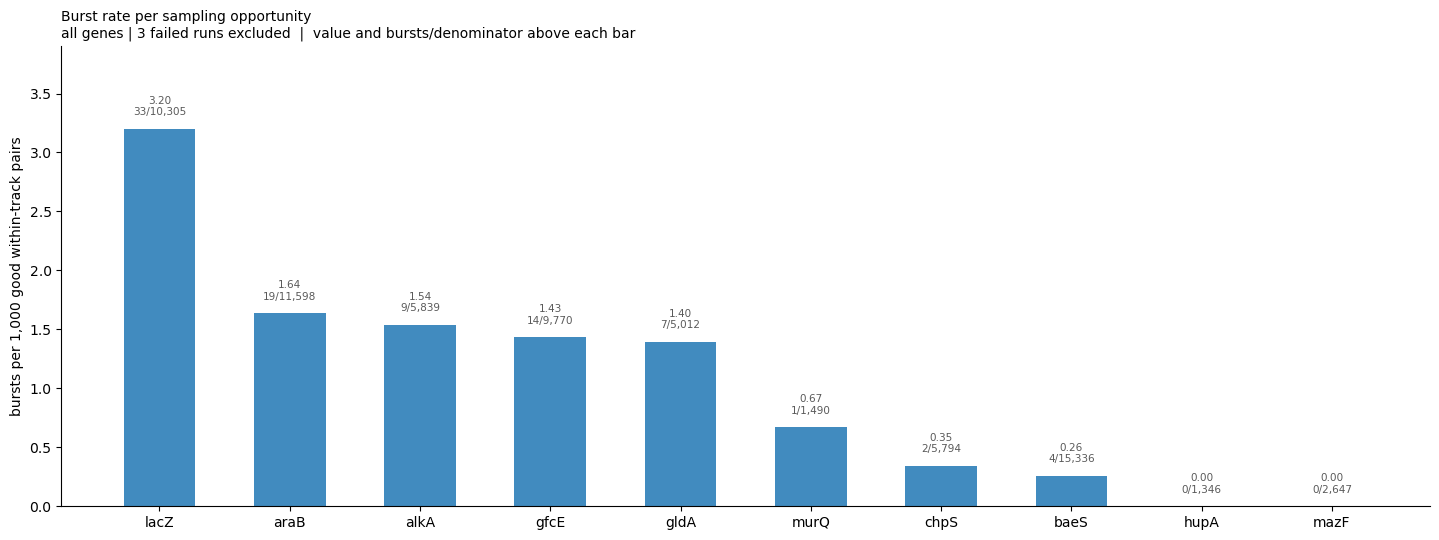

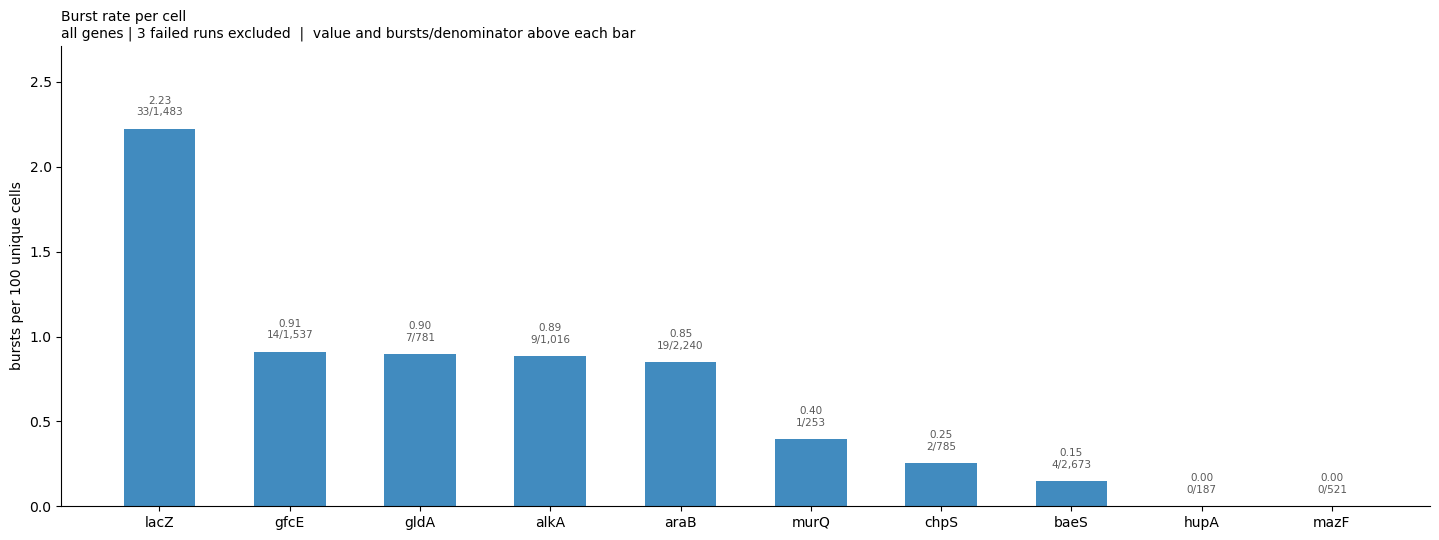

In [13]:
burst_rates = F.burst_rate_table(bursts, cells, pairs)
_show = burst_rates.copy()
_show['ci_per_1k_pairs'] = [f'{a:.2f}-{b:.2f}' for a, b in zip(_show.gp_lo, _show.gp_hi)]
_show['ci_per_100_cells'] = [f'{a:.2f}-{b:.2f}' for a, b in zip(_show.uc_lo, _show.uc_hi)]
_show['rank_by_pair'] = _show.per_1k_good_pairs.rank(ascending=False, method='min').astype(int)
_show['rank_by_cell'] = _show.per_100_cells.rank(ascending=False, method='min').astype(int)
print(_show[['n_bursts', 'n_good_pairs', 'n_cells', 'per_1k_good_pairs', 'ci_per_1k_pairs',
             'rank_by_pair', 'per_100_cells', 'ci_per_100_cells', 'rank_by_cell']]
      .sort_values('per_1k_good_pairs', ascending=False).round(3).to_string())

_moved = _show[_show.rank_by_pair != _show.rank_by_cell]
if len(_moved):
    print(f'\n{len(_moved)} gene(s) change rank between the two denominators: '
          f'{", ".join(_moved.index)} -- they sit within '
          f'{_moved.per_1k_good_pairs.max() - _moved.per_1k_good_pairs.min():.2f} '
          f'per 1000 pairs of each other, so the order there is not meaningful.')

F.plot_burst_rank_bars(burst_rates, 'per_1k_good_pairs', 'gp_lo', 'gp_hi',
                       'bursts per 1,000 good within-track pairs',
                       'Burst rate per sampling opportunity', 'burst_rate_per_good_pair',
                       denom_col='n_good_pairs')
F.plot_burst_rank_bars(burst_rates, 'per_100_cells', 'uc_lo', 'uc_hi',
                       'bursts per 100 unique cells',
                       'Burst rate per cell', 'burst_rate_per_cell', denom_col='n_cells');

### Validating a burst against its trench

Grey = per-cell lineage traces stitched onto their ancestors, so an *inherited* burst reads as a
declining slope rather than a fresh peak. Coloured = the per-lineage-family max envelope, which
is the signal detection actually ran on. Crimson = the detected peaks, read from the CSV.
Dashed = the (gene × experiment) threshold, recomputed from the cell table so a quiet trench
still gets a line.

The second case is the one that motivated v2. With a single trench-wide envelope the second
burst's marker appears to float *below* the line, because at that frame the trench max is
following the other, brighter burst — pass `by_family=False` to see it.

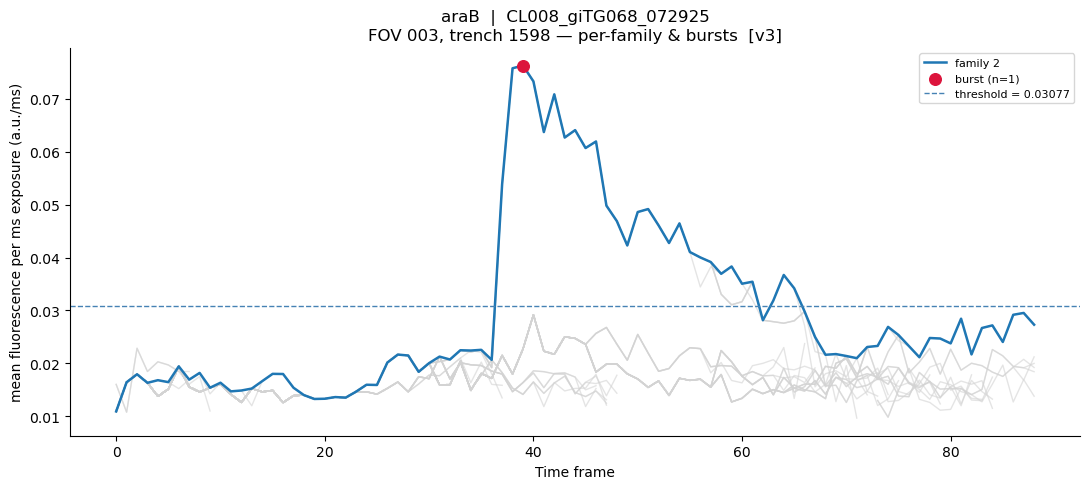

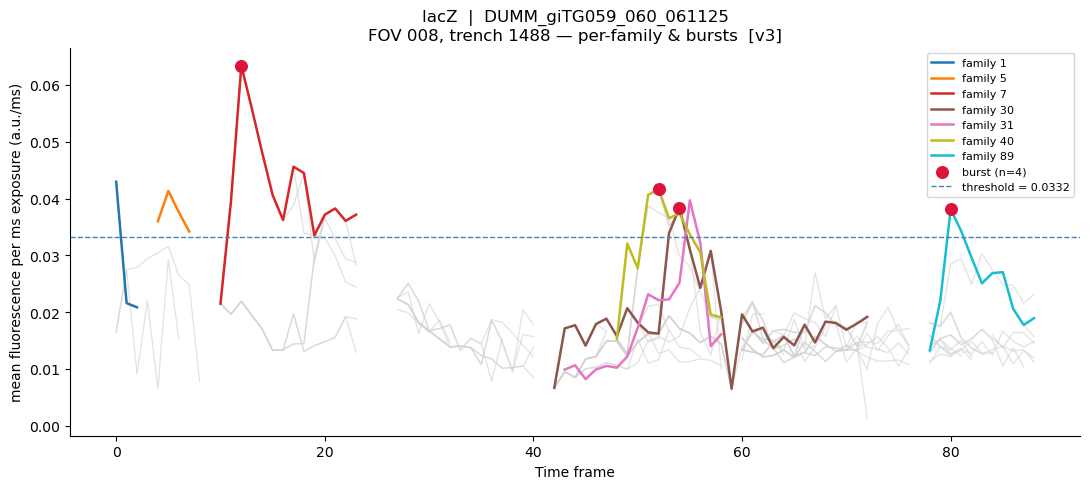

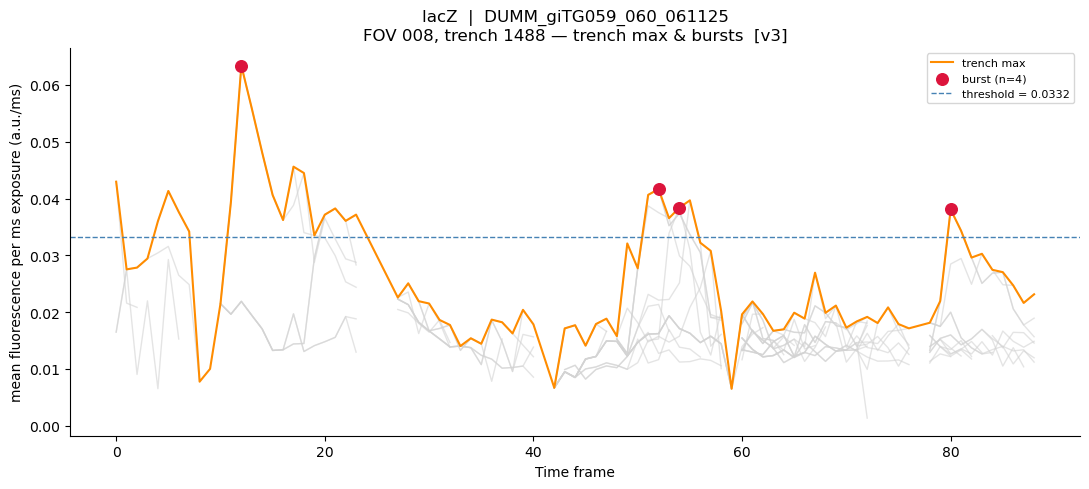

In [14]:
# Case 1 -- a clean single burst. Flat at ~0.021 a.u./ms, then a sharp rise.
F.plot_bursts_for_trench(cells, bursts, 'CL008_giTG068_072925', '003', '1598')

# Case 2 -- TWO concurrent bursts in one trench, the case a single envelope cannot see.
F.plot_bursts_for_trench(cells, bursts, EX_EXP, EX_FOV, EX_PEAK)
F.plot_bursts_for_trench(cells, bursts, EX_EXP, EX_FOV, EX_PEAK, by_family=False);

---
# 7 — A different route to bursts: the distribution of cell-frame fluorescence

Section 6 finds bursts by peak detection on a max-fluorescence envelope, so a burst there is an
**event in time**. This section asks the same question with time thrown away: what does the
*distribution* of fluorescence look like across every cell-frame of a gene?

The logic is that a bursty gene should carry a **right tail** — a minority of cell-frames sitting
far above the bulk — while a constitutive gene, always on, should be tight and roughly symmetric.
A ranking built from that tail shares no machinery with section 7, so where the two agree that is
real evidence, and where they disagree that is a lead worth following.

**One observation is one cell-frame, not one cell.** Every row of the table counts: a cell tracked
across 40 frames contributes 40 values. That is deliberate — a burst is a handful of frames, so
collapsing each cell to a single mean would average out the very thing being hunted. Each figure's
title reports both numbers, cell-frames and unique cells, so the distinction is never in doubt.

## The per-experiment offset, and the rescaling that removes it

Pooling a gene's experiments in absolute a.u./ms does not work. baeS's pooled distribution has a
skew of **6.68** against a within-experiment skew of 0.95: one acquisition
(`DUMM_giTG66_Glucose_012325`, median 0.480 a.u./ms against 0.086 and 0.124 for its two siblings)
sits bodily above the others, and pooling reports that gap as a bright subpopulation.

So each cell-frame is rescaled against its own **(gene, experiment)** group before pooling. Every
candidate transform is affine within a group, which means **none of them changes the shape inside
an experiment** — within-experiment skew is identical under all of them. What they change is only
how the groups line up when pooled. Measuring that as the distance between a gene's pooled skew
and its batch-free within-experiment skew:

Measured on `hist_df`, the frame this section actually uses:

| `normalize=` | formula | mean skew gap | worst gene | baeS pooled skew |
|---|---|---|---|---|
| `'none'` | `f` | 0.91 | baeS 5.73 | **6.68** |
| **`'minmax'`** (default) | `(f − min) / (max − min)` | **0.14** | hupA 0.32 | **1.22** |
| `'robust'` | `(f − p1) / (p99 − p1)` | 0.16 | lacZ 0.59 | 0.95 |
| — | `(f − median) / 1.4826·MAD` | 0.27 | lacZ 1.17 | 0.95 |
| — | `f / median` | 0.33 | lacZ 1.39 | 0.96 |

baeS lands essentially on its true within-experiment value of 0.95. Min–max is the best of the
five at the specific job of removing the offset, so it is the default; the last two rows were
measured and rejected, not omitted.

### Two things to know about the scaling

**The group is (gene, experiment), never experiment alone.** Eight experiments hold two genes, and
they can be very far apart — `DUMM_giTG068_063_061725` has alkA at 0.048 a.u./ms and hupA at 3.99,
a factor of **83**. Scaling per experiment would compress every alkA cell-frame into the bottom 1%
of [0, 1] and its histogram would be a single spike at zero. This is also how `compute_baselines`
groups in section 7.

**Min–max divides by a burst.** In **14 of the 20** (gene, experiment) groups that contain a
detected v2 burst, the single brightest cell-frame *is* one of those burst peaks. So `1.0` on the
scaled axis means "this acquisition's own burstiest moment", not a fixed level: a group whose
burst reached 7× baseline and one that reached 3× both put their peak at exactly 1.0. That is
fine for comparing *shape* — which is what these histograms are for — but it means the axis is not
a brightness scale and the height of the tail is not comparable between groups.

`normalize='robust'` is the alternative when that matters. It scales on the 1st and 99th
percentiles instead of the two extreme observations, so a single cell cannot set the axis and the
burst tail runs past 1.0 rather than being pinned to it. It gives up almost nothing on batch
removal (gap 0.13 against 0.10).

### The input filter

Degenerate masks are dropped **before** any scale is computed, via section 9's
`drop_degenerate_masks`. On a 1-pixel mask `intensity_mean_fluor` is a single raw pixel with no
averaging, and such a mask can set a group's maximum — that is, the entire x-axis under min–max
scaling. Removing them moves araB's max in `DUMM_CL008_giTG061_081225` by 36%.

The floor is **5% of each experiment's own median cell area**, not an absolute px² threshold,
because one acquisition is on a ~3× coarser pixel scale — see the box below. The counts here sit
slightly below Table A and the section 5 table; the cell below reconciles them.

### ⚠ `DUMM_giTG66_Glucose_012325` is on a different pixel scale from every other run

**Correction to an earlier version of this note, which called this a segmentation failure. It is
not — the masks are geometrically perfect. The imaging geometry is different.**

It was found through the area floor. Under the **old absolute 50 px² floor** baeS lost 4.27% of its
cell-frames while no other gene lost more than 0.3%, and 749 of those 779 came from this one
acquisition. (The floor is relative now, so the reconciliation above no longer shows that — baeS
loses 25 cell-frames, 0.14%, in line with every other gene.) Following it up, *everything* in that
run is uniformly ~0.34× in linear scale:

| | `DUMM_giTG66_Glucose_012325` | other 19 experiments |
|---|---|---|
| median cell length | 12.6 px | 36.5 px — **0.35×** |
| median cell width | 3.3 px | 9.6 px — **0.34×** |
| **trench extent (max `centroid_y`)** | **123 px** (all 4 trenches: 122–123) | 366 px — **0.34×** |
| median cell area | 33 px² | 263 px² — **0.13× ≈ 0.34²** |
| cells per trench per frame | 3 | 3–8 |

Cells, cell widths *and the trench itself* all shrink by the same factor while the cell count per
trench stays normal. Fragmented segmentation would give **more** cells per trench in a
**normal-sized** trench; this is the opposite. Two further checks confirm the masks are sound:
the aspect ratio `L/W` is 3.71 against 3.97 elsewhere, and `area / (L·W)` is **0.783** against
0.767 elsewhere — both matching π/4 = 0.785 for a clean ellipse, which a fragmented or degenerate
mask could not do.

So this run was acquired at roughly one third the linear pixel scale — lower magnification, camera
binning, or a downscaled save. **Nothing in the pipeline records pixel size**: `experiment_metadata.py`
and `08_build_combined_data.py` carry exposure and `minutes_per_frame` only, and CLAUDE.md already
notes no µm/px exists anywhere in the repo. So the difference is invisible to every stage.

It also explains the brightness, and rules out the explanations we reached for first. Raw phase is
**1,139** here against 8,817 elsewhere while raw fluorescence is **228** against 13 — phase 7.7×
dimmer, fluorescence 17× brighter. Coarser pixels integrate more photons per pixel, and
`intensity_mean_fluor` is a per-pixel mean, so the 5.3× offset that made baeS look like the
burstiest gene is an artefact of pixel size, not exposure and not biology. Exposure normalisation
cannot remove it because it is not an exposure effect; min–max scaling per (gene, experiment) does,
which is why baeS behaves in the scaled histograms.

**What was done about it, and what was not:**

1. **The area floor is now relative** — 5% of each experiment's own median cell area, in section 9
   and here. This is the same argument the repo already makes for `delta_y_cell_lengths`: with no
   µm/px recorded anywhere, a ratio is the only threshold that ports across acquisitions. Measured,
   the old absolute 50 px² floor dropped 905 cell-frames of which **749 were this run's good
   cells**; the relative floor drops 121, of which **1**. The masks the filter was written for are
   the ≤5 px² ones — 100 in the dataset, 98 outside this run — and it still catches them.
2. **This acquisition is still included.** Excluding it is a call about the data, not about the
   filter: it is 4 trenches on an incomparable pixel *and* intensity scale, so arguably it belongs
   with the three failed runs. Doing so would move the section 5 bars, the section 7 baselines and
   the burst rates, so it is flagged rather than taken. Min–max scaling per (gene, experiment)
   neutralises it for **these** histograms, but not for sections 5 and 7, which still read it at
   face value.

### What the first pass turned up

**mazF is bimodal, and it is one FOV.** Its main mode is a broad symmetric hump, but a sharp second
mode sits far below it holding **743 of 3,237 cell-frames (23%)**. It survives the area floor and
survives min–max scaling, sitting at 0.00–0.15 on the scaled axis against a bright-mode median of
0.47 — so it is a real within-experiment feature, not a batch offset.

It comes from **`DUMM_mazF_murQ_121625`, and within it from FOV 012 specifically**. Of the three
experiments carrying mazF, only that one is bimodal (36% of its cell-frames in the dim mode, against
3.0% and 0.6% for the other two), and its decile profile is unmistakable — 710 cell-frames in the
first tenth, 80 in the second, then a normal hump. Broken out by FOV within that run:

| FOV | mazF trenches | cell-frames | median fluorescence |
|---|---|---|---|
| 005 | 3 | 1,056 | 0.387 |
| 006 | 2 | 293 | 0.390 |
| **012** | **2** (1042, 358) | **715** | **0.050** |

It is not two stray trenches — it is **every mazF trench in FOV 012**, at 7.7× below its sibling
FOVs in the same acquisition. And there are real cells there: median area 208 and 286 px² and
median cell length 35.1 px, both normal, and mean phase intensity 10,400–12,100 against 12,900 for
the rest of the run. Normal morphology, normal phase contrast, no fluorescence — so an FOV-level
illumination, focus or background-subtraction problem, or genuinely non-expressing cells loaded
into that region of the chip. Worth resolving, because mazF is one of the three constitutive
controls section 7's method is validated against.

It is a property of whole cells, not of frames: **21% of mazF cell-tracks are dark for their entire
lifetime while 75% are never dark**, so these are non-expressing cells rather than cells passing
through a dim state.

**lacZ and araB look the way a bursty gene should**: one unimodal bulk with a smooth right tail, no
second mode.

**Nothing in this section is saved.** Both loops pass `save=False`, so `FIG_DIR` is untouched and
the figures are inline only. The ten `fluor_hist_<gene>.svg/.png` already in `FIG_DIR` are
leftovers from an earlier pass and are not refreshed by this run.

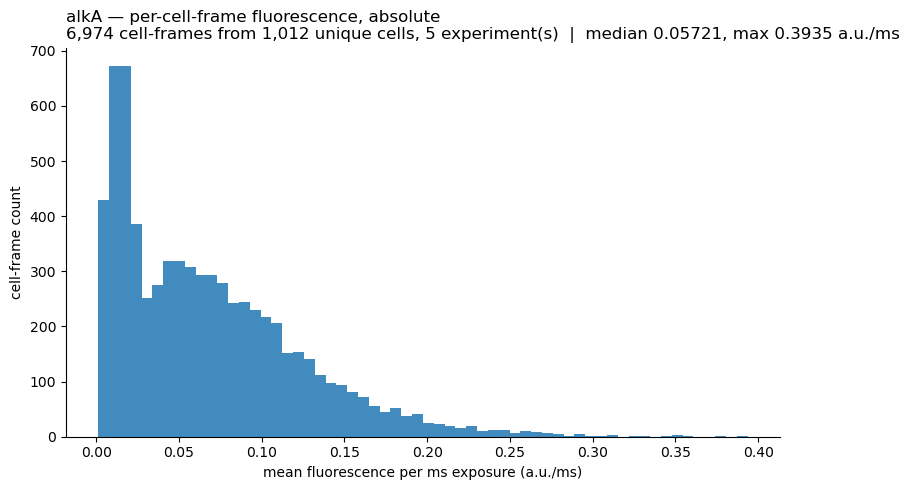

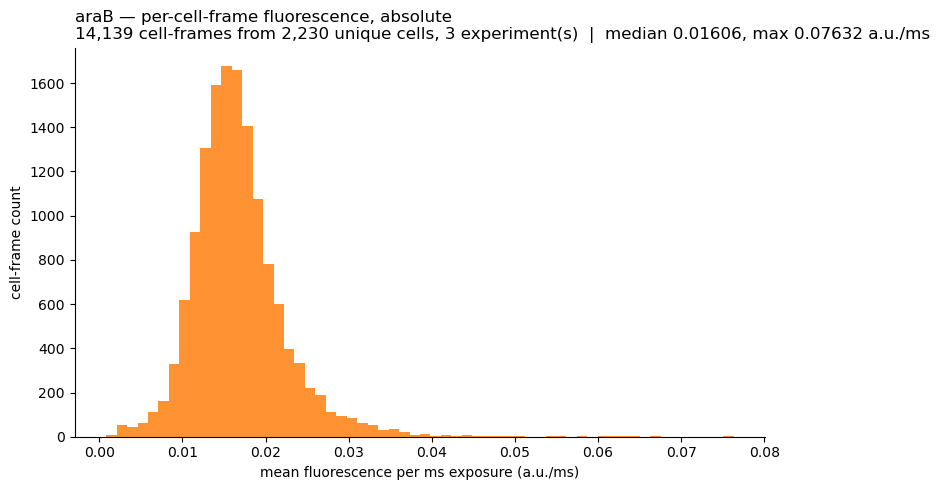

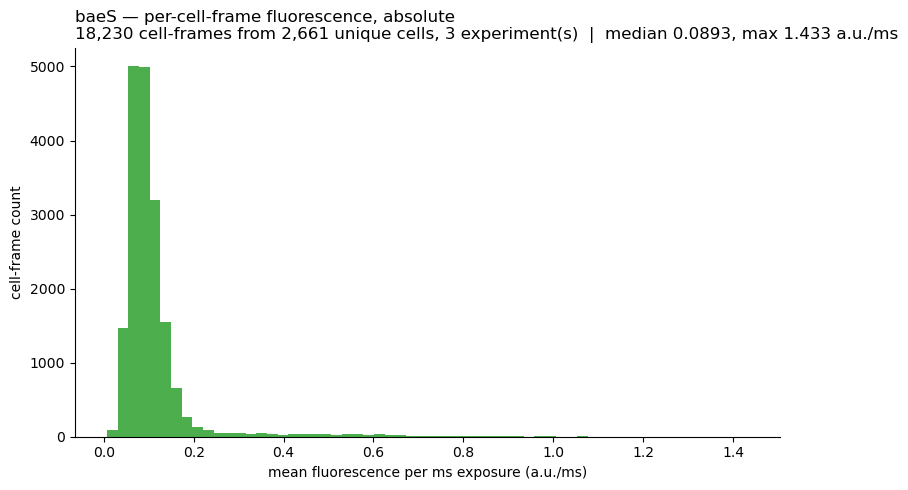

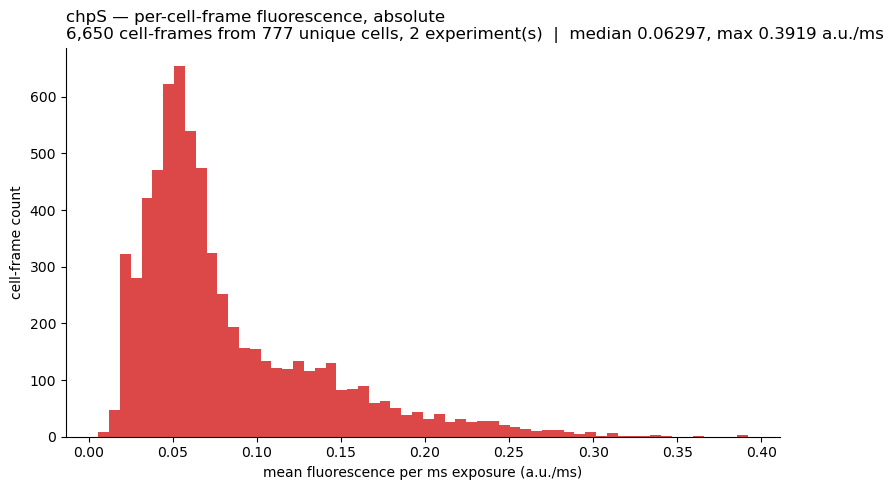

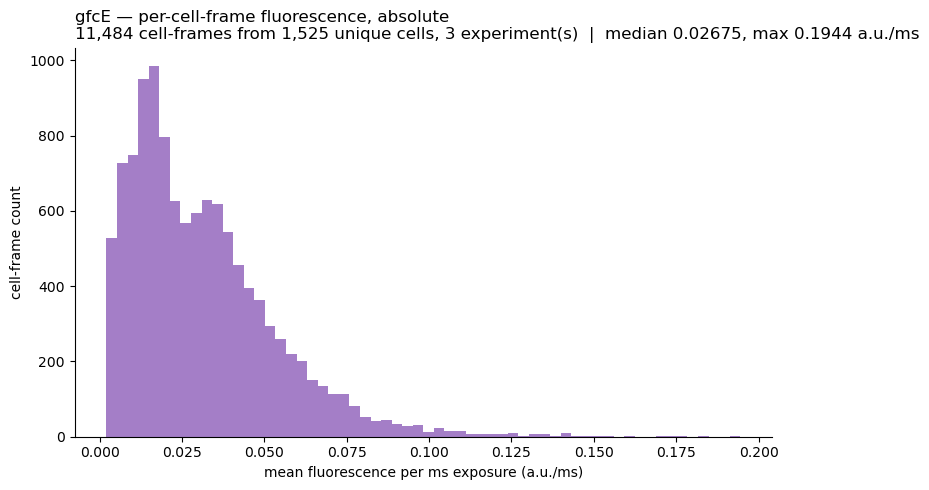

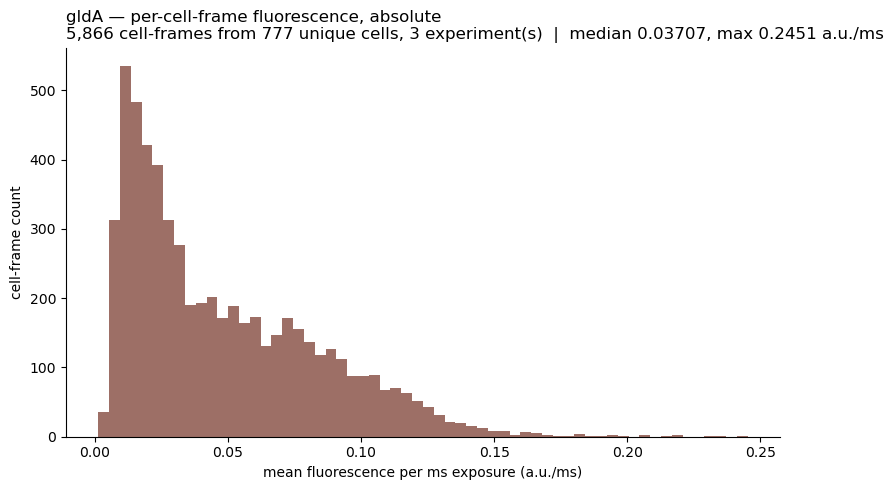

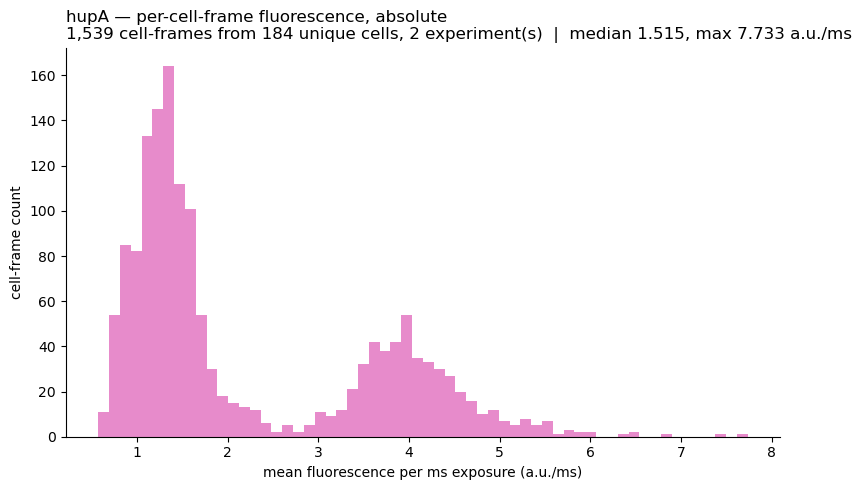

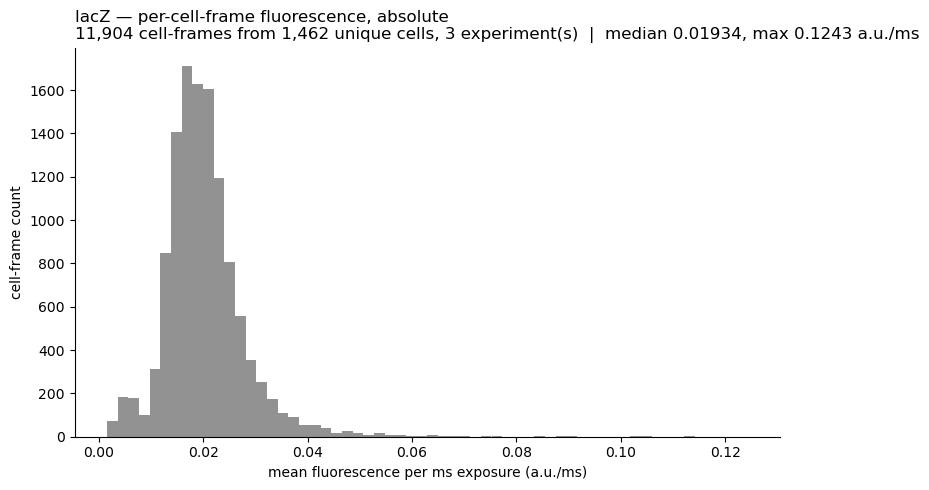

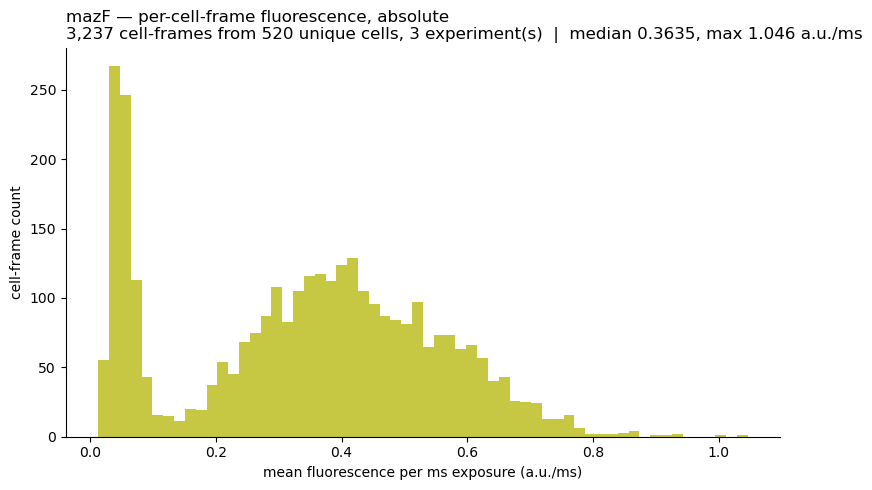

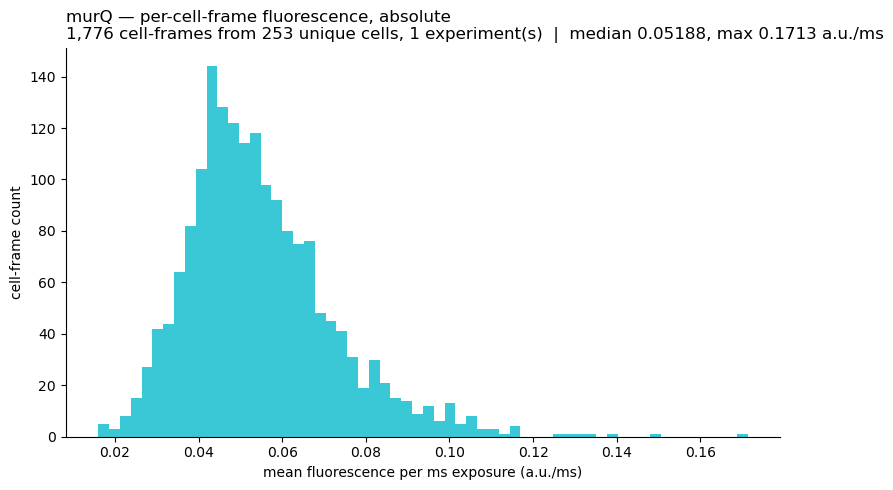

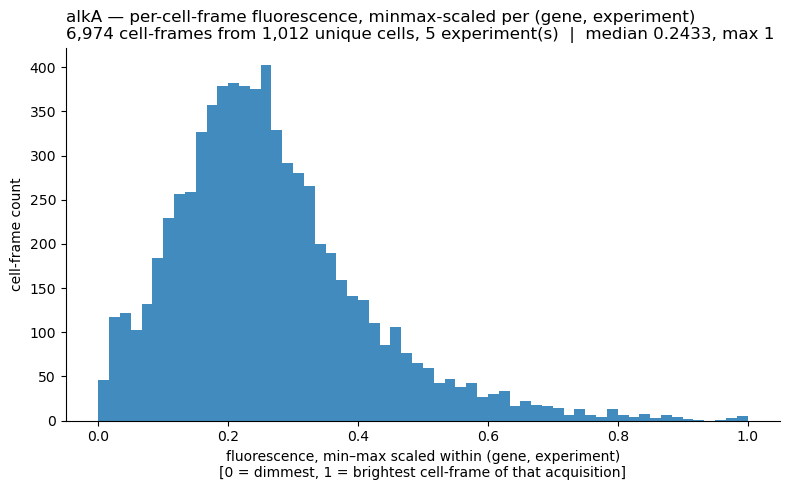

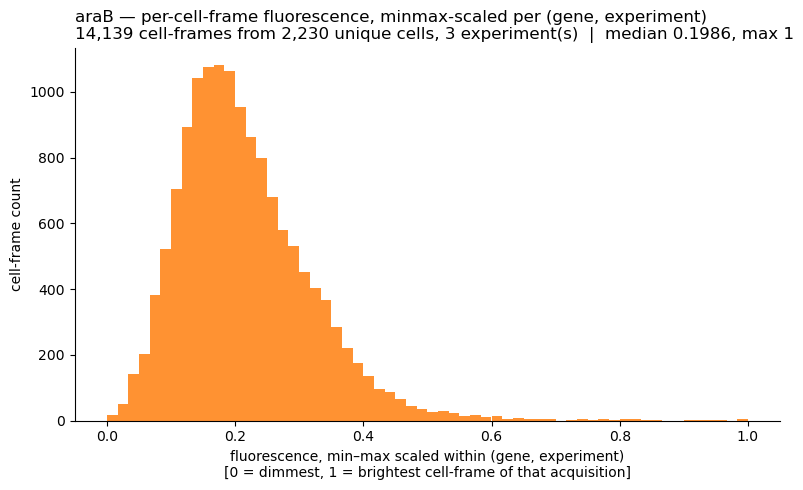

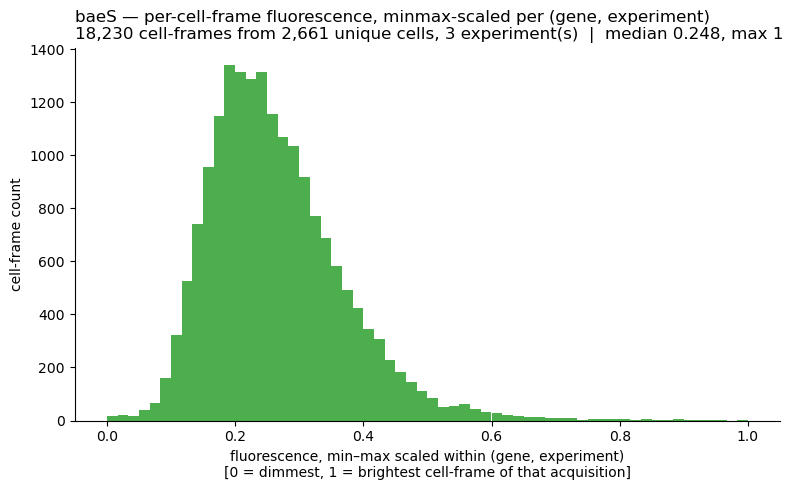

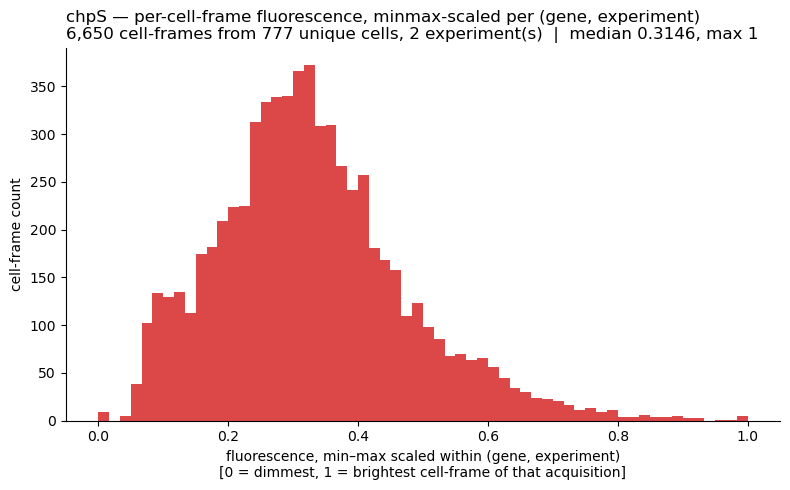

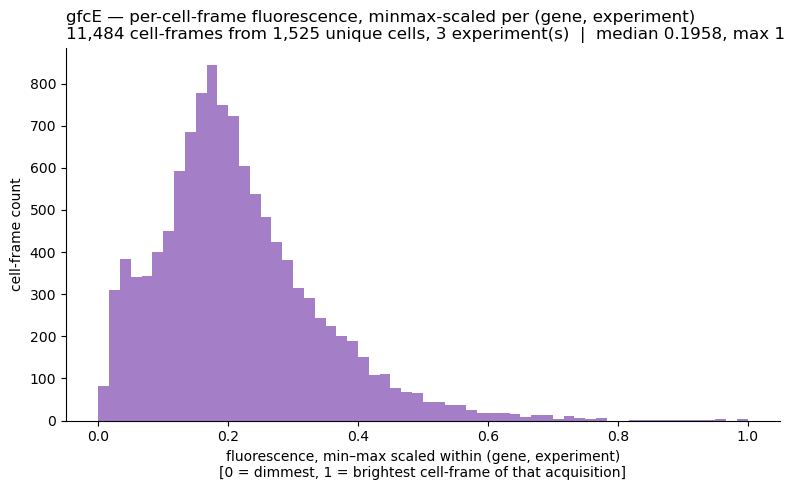

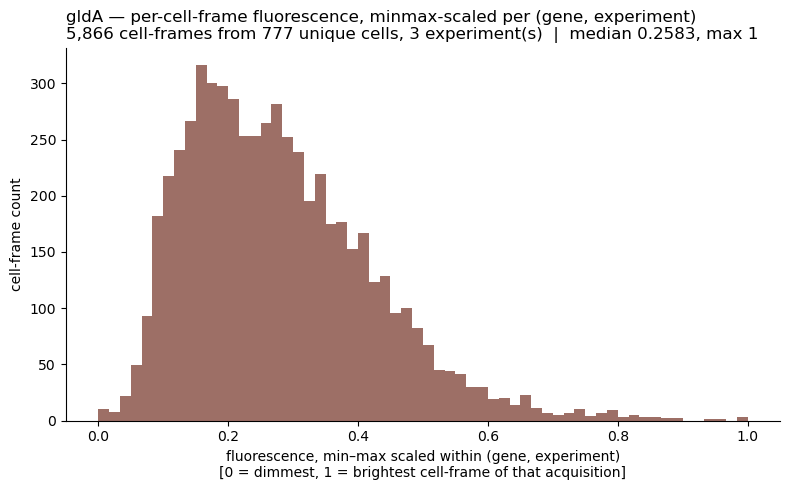

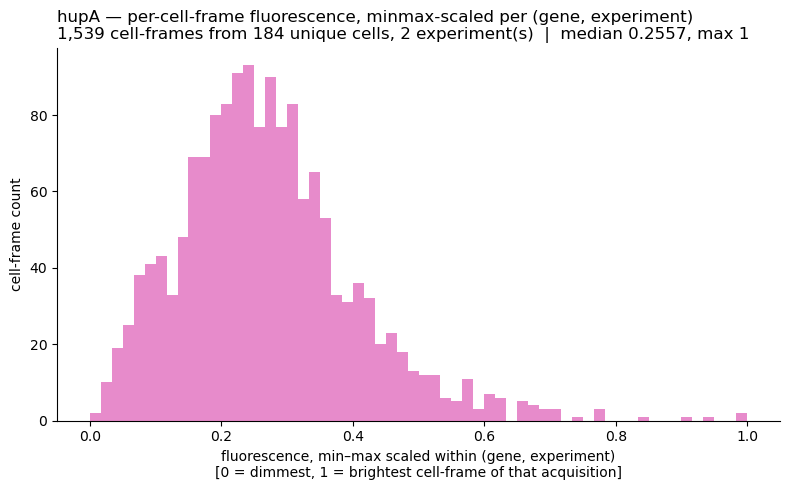

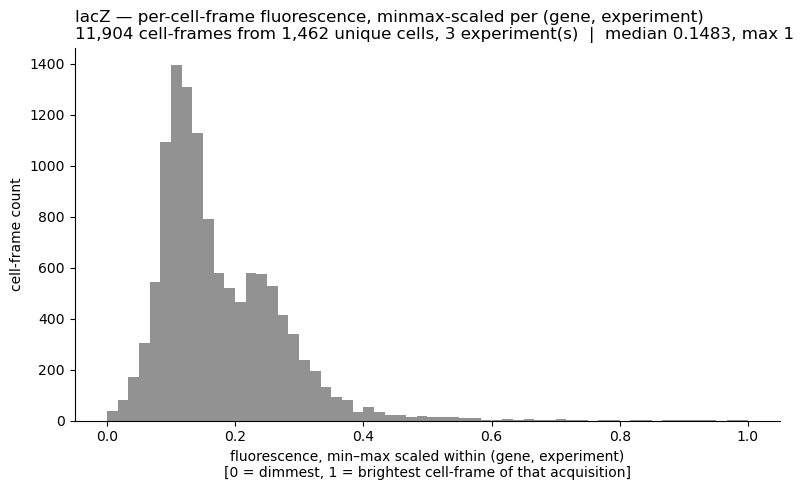

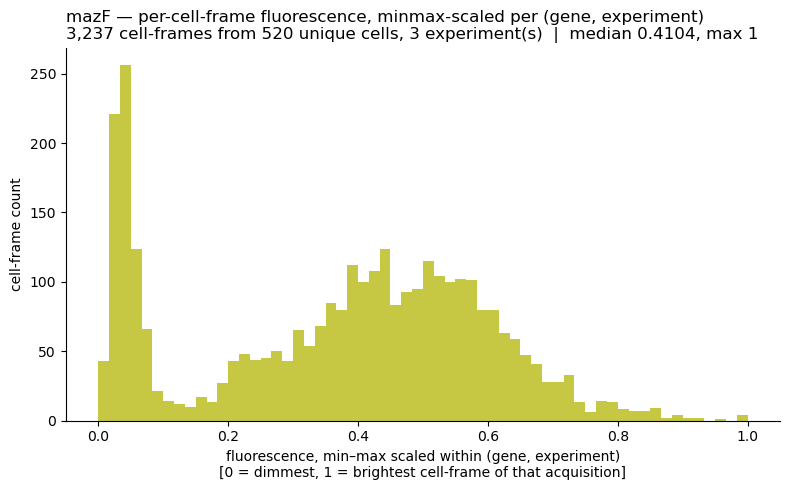

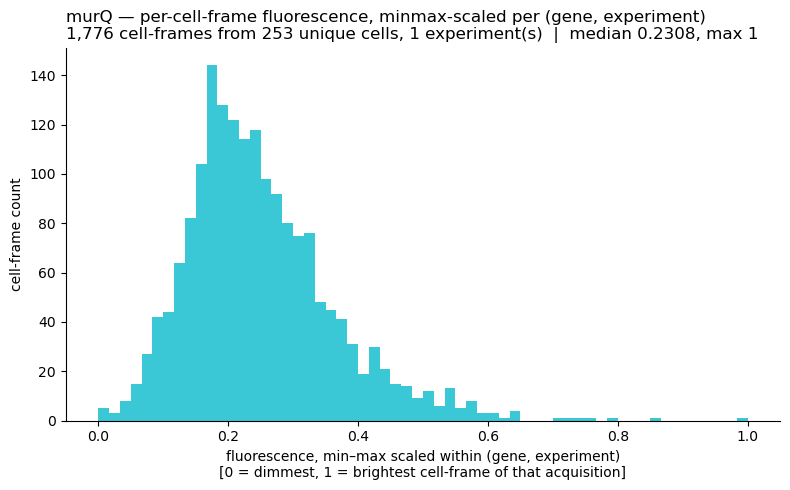

In [15]:
# Two sets, same frame, directly comparable.
#   'none'   -- absolute a.u./ms. What each gene actually sits at.
#   'minmax' -- scaled within each (gene, experiment), so a gene's replicates can be pooled
#               without the batch offset between them masquerading as a bright subpopulation.
# Degenerate masks are dropped BEFORE any scale is computed: on a 1-pixel mask the value is a
# single raw pixel with no averaging, and one such mask can set the group maximum.
for _norm in ('none', 'minmax'):
    for _gene in sorted(clean['gene'].dropna().unique()):
        F.plot_fluor_histogram(clean, _gene, normalize=_norm, save=False)

---
# 8 — Why some visible bursts are not counted

Section 6 reports what the detector found. This section reports what it **rejected**, because
browsing `data/kymograph_viewer_bursts_090926c.html (the only viewer retained; older dated builds were deleted)` turns up trenches that look like they burst
and carry no outline, and "the definition is missing things" is not actionable until it is
countable.

Detection now lives in `mmtrack.bursts` rather than in the closed 082026 notebook, so
everything below re-runs from this notebook. The move is behaviour-preserving and the assert in
8c is the proof: v1/v2/v3 return exactly **73 / 89 / 89** events, set-identical to
`data/bursts_082026.csv`.

### The two failure modes, up front

Two trenches were used as the worked cases, and they fail for entirely different reasons. The
distinction matters because only one of them is fixable by moving a threshold.

| | **Class A** — near-miss on prominence | **Class B** — not a peak at all |
|---|---|---|
| case | chpS `DUMM_giTG062_064_121325` 010/1188 @ 25 | baeS `DUMM_giTG066_063_120925` 002/1979 @ 36 |
| height | **5.38 s** — clears the bar of 4.0 | **1.34 s** — fails by 59% |
| prominence | **3.851 s** vs 4.0 — short by **3.7%** | **0.26 s** vs 4.0 — fails by 94% |
| shape | an isolated spike | a monotone 1.62× ramp still climbing at the last frame |
| fix | yes — `k_prom` (8d, and v4 in the changelog) | no threshold reaches it (section 9) |

A burst is a *peak*. Prominence is what makes that precise, and it is the criterion that keeps
the constitutive genes at zero — so a rule that counted Class B would be a different
measurement, not a better-tuned one. Section 9 gives ramps their own table instead.

### 8a — A frame number read off the viewer is not a `time_frame`

Settle this before quoting any frame number, because it is silent when wrong.

The viewer labels its kymograph axis and its fluorescence charts with **absolute** frames,
`start + column`, where `start` comes from `data/time_dict_082026.json`
(`generate_kymograph_viewer.py` lines 260 and 523). Every table in this repo — the cell table,
the pair table, `bursts_082026.csv` — stores the **0-based kymograph column** in `time_frame`,
deliberately un-offset, because the burst outlines are drawn in column space.

For trenches with `start = 0` the two agree, which is exactly what makes the trap easy to miss.
For 002/1979, `start = 37`: "frame 73" in the viewer is `time_frame` **36**, and looking up 73
finds nothing at all — that trench's table ends at 51.

In [16]:
# Detection and the audit tools. Imported here rather than in cell 1 so section 8 is
# self-contained and can be re-run on its own.
import mmtrack.bursts as Bu

CASE_A = ('DUMM_giTG062_064_121325', '010', '1188')     # chpS -- Class A, near-miss
CASE_B = ('DUMM_giTG066_063_120925', '002', '1979')     # baeS -- Class B, a ramp
VIEWER_FRAME = {CASE_A: 25, CASE_B: 73}                 # as read off the viewer

print(f'{"trench":<44} {"start":>5} {"viewer":>7} {"time_frame":>11}   frames in table')
for kymo, vf in VIEWER_FRAME.items():
    exp, fov, trench = kymo
    start = F.trench_start_frame(exp, fov, trench, data_root=REPO_ROOT)
    tf = F.viewer_frame_to_time_frame(exp, fov, trench, vf, data_root=REPO_ROOT)
    tr = F.select_trench(clean, exp, fov, trench)
    print(f'{exp[:26]+" "+fov+"/"+trench:<44} {start:>5} {vf:>7} {tf:>11}   '
          f'{int(tr.time_frame.min())}-{int(tr.time_frame.max())}')

FRAME_A = F.viewer_frame_to_time_frame(*CASE_A, VIEWER_FRAME[CASE_A], data_root=REPO_ROOT)
FRAME_B = F.viewer_frame_to_time_frame(*CASE_B, VIEWER_FRAME[CASE_B], data_root=REPO_ROOT)
assert (FRAME_A, FRAME_B) == (25, 36)

trench                                       start  viewer  time_frame   frames in table
DUMM_giTG062_064_121325 010/1188                 0      25          25   0-40
DUMM_giTG066_063_120925 002/1979                37      73          36   0-51


### 8b — The two cases, with the arithmetic drawn

`plot_prominence_bases` draws what `plot_bursts_for_trench` cannot: the height bar, every
height-clearing local maximum, and the **left and right base levels** of the strongest
candidate. Prominence is the peak minus the *higher* of those two, so the higher line is the one
that decides the verdict — and the crimson arrow (delivered) against the grey one (required) is
the whole rejection.

**Class A, chpS 010/1188.** Track 23 runs 0.186 → 0.392 → 0.392 → 0.300 → 0.135 over frames
24–28: an unambiguous spike. Its left base is 0.1100 (frame 2) but its **right** base is 0.2128
(frame 38), because the envelope never comes back down before the movie ends at frame 40 —
other cells of the same lineage family keep it up. Note the trench is essentially **one family**
(39 of 43 tracks descend from track 3) and its cells sit 0.89–1.19 cell lengths apart, under
v3's 1.5 split gap, so v1, v2 and v3 all see the *same* single envelope here. The concurrency
machinery cannot help.

**Class B, baeS 002/1979.** No frame in the trench clears the height bar at all — the envelope
tops out at 0.1984 against a bar of 0.3232, so the plot shows no candidate. The event is real
(track 30's mean jumps 18.5 → 28.6 in one frame) but it rides a trench-wide ramp whose maximum
is at frame **49**, thirteen frames after the frame flagged by eye.


DUMM_giTG062_064_121325 010/1188 -- 2 height-clearing candidate(s)
 time_frame  track_id  fluor  threshold  height_s  prom_s  prom_min_s  prom_left_s  prom_ratio binding_side  frames_to_end       verdict
         25        23 0.3919     0.3276    5.3823  3.8508      6.0607       6.0607      0.9627        right             15    prominence
         29        17 0.3601     0.3276    4.6990  0.7005      3.1674       0.7005      0.1751         left             11 not local max

DUMM_giTG066_063_120925 002/1979 -- 0 height-clearing candidate(s)
  none: no frame in this trench reaches the height bar


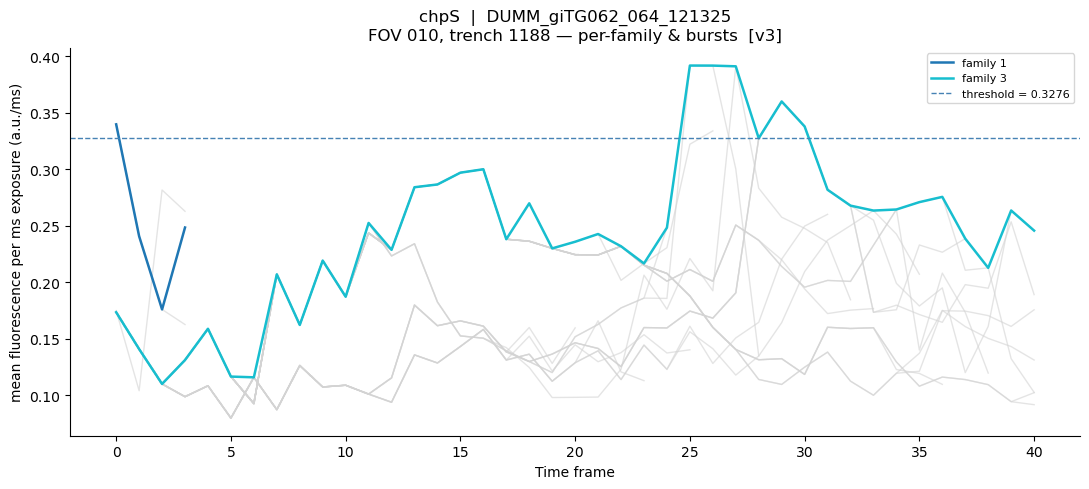

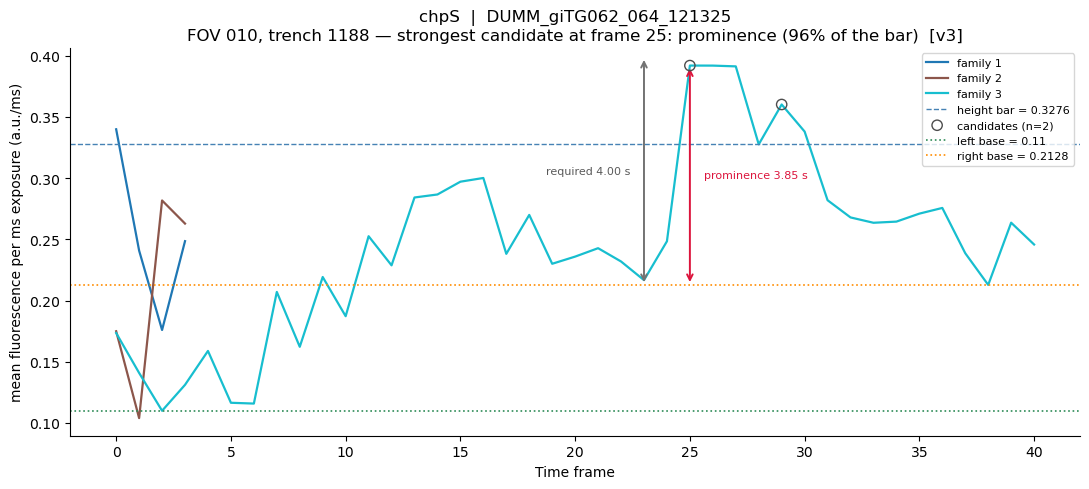

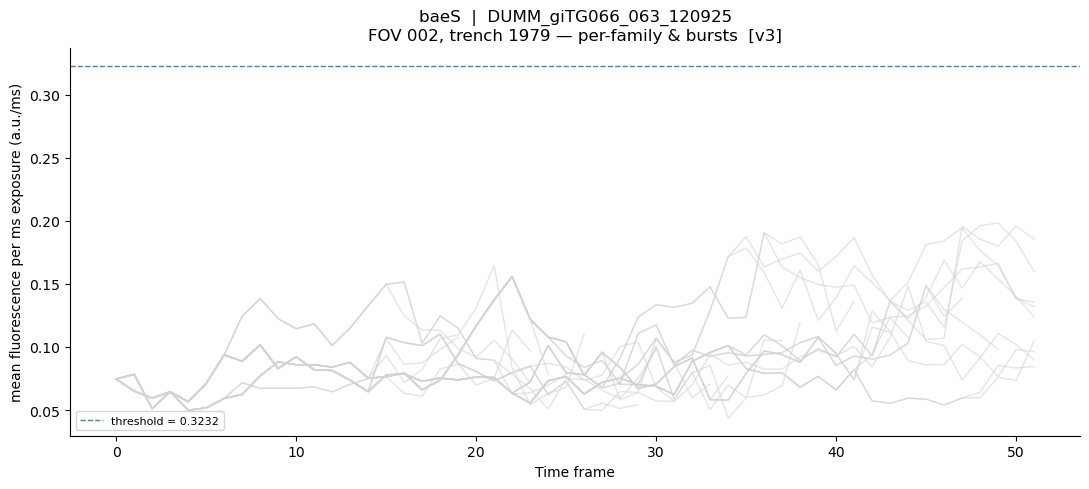

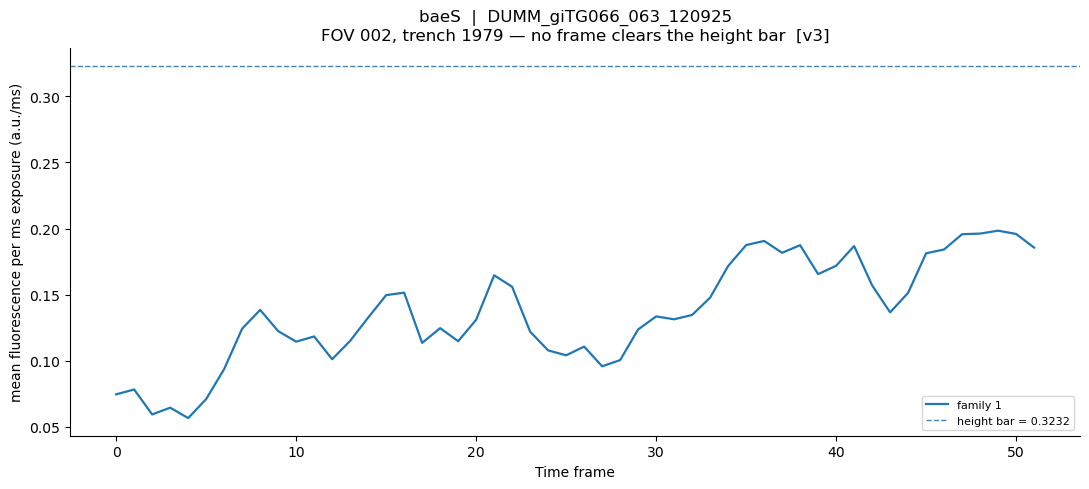

In [17]:
for kymo, frame in ((CASE_A, FRAME_A), (CASE_B, FRAME_B)):
    exp, fov, trench = kymo
    F.plot_bursts_for_trench(clean, bursts, exp, fov, trench)
    F.plot_prominence_bases(clean, exp, fov, trench)

# The candidate rows behind those figures. `prom_ratio` is prominence / required, so anything
# in (0, 1) is a rejection and the number is how close it came.
cand = Bu.burst_candidates(clean, Bu.BURST_DEF_V3)
CAND_COLS = ['time_frame', 'track_id', 'fluor', 'threshold', 'height_s', 'prom_s',
             'prom_min_s', 'prom_left_s', 'prom_ratio', 'binding_side', 'frames_to_end',
             'verdict']
for exp, fov, trench in (CASE_A, CASE_B):
    c = F.select_trench(cand, exp, fov, trench)
    print(f'\n{exp} {fov}/{trench} -- {len(c)} height-clearing candidate(s)')
    print(c[CAND_COLS].round(4).to_string(index=False) if len(c)
          else '  none: no frame in this trench reaches the height bar')

### 8c — The near-miss census

Every peak that clears the height bar, with the reason for its verdict. This is the table that
turns "it misses things" into a number.

**327 peaks clear the height bar. 178 of them are also the maximum within ±`window` frames** —
the rest are shoulders and wobbles on the way up or down, which the detector discards too via
`find_peaks(distance=window)`. Of those 178, **94 pass prominence and 84 fail it**, and a third
of the failures are close: **34 sit at ≥ 75% of the required prominence and 13 at ≥ 90%**,
across 9 of the 10 genes. Class A is one of the 9 at ≥ 95%.

So prominence, not height and not the window, is what decides nearly every borderline case —
consistent with the v1 entry's finding that `window` is inert while prominence is on.

The `binding_side` split is the mechanism: the **right** base decides 53 of the 84 rejections.
A burst whose envelope has not returned to baseline by the end of the recording has its right
base set by a plateau rather than by a baseline, so its prominence is measured against the wrong
floor. `frames_to_end` shows how much room the right flank actually had. That is a
recording-length artefact rather than a property of the burst, which is the argument for moving
the bar in 8d.


In [18]:
# The move to mmtrack.bursts must be behaviour-preserving. This is the proof, and it is
# deliberately an assert: if a future edit changes the detector, this cell fails loudly rather
# than quietly restating a new number.
_key = F.KYMO_KEY + ['track_id', 'time_frame']
_as_set = lambda d: set(map(tuple, d[_key].astype({'track_id': int, 'time_frame': int}).values))
burst_sets, burst_audits = {}, {}
# v6 is detected here with the others so section 10 and the export can carry it; the route
# it adds is explained in section 11, not here.
for _v in ('v1', 'v2', 'v3', 'v4', 'v5', 'v6'):
    burst_sets[_v], burst_audits[_v] = Bu.run_burst_detection_any(clean, Bu.BURST_DEFS[_v])
for _v, _want in (('v1', 73), ('v2', 89), ('v3', 89)):
    _got = _as_set(burst_sets[_v])
    _shipped = _as_set(bursts_all[bursts_all[f'burst_{_v}']])
    assert _got == _shipped, (f'{_v}: {len(_got)} events, {len(_got ^ _shipped)} differ from '
                              f'data/bursts_082026.csv')
    assert len(_got) == _want, f'{_v}: {len(_got)} events, expected {_want}'
print('regression OK -- v1/v2/v3 reproduce data/bursts_082026.csv exactly '
      f'({" / ".join(str(len(burst_sets[v])) for v in ("v1", "v2", "v3"))}), '
      f'v3 == v2: {_as_set(burst_sets["v3"]) == _as_set(burst_sets["v2"])}')

nm = cand[cand.verdict == 'prominence']
_lm = cand[cand.is_local_max]
print(f'\n{len(cand)} peaks clear the height bar; {len(_lm)} are also the local max over '
      f"+/-{Bu.BURST_DEF_V3['window']} frames")
print(f"  of those {len(_lm)}: {int((cand.verdict == 'burst').sum())} pass prominence, "
      f'{len(nm)} fail it')
print('\nrejections by how close they came (prominence / required):')
print(pd.cut(nm.prom_ratio, [0, .25, .5, .75, .9, .95, 1.0])
      .value_counts().sort_index().to_string())
print(f'\n>= 0.75: {(nm.prom_ratio >= .75).sum()}   >= 0.90: {(nm.prom_ratio >= .90).sum()}')
print('\nnear-misses (>= 0.75) by gene:')
print(nm[nm.prom_ratio >= .75].groupby('gene').size()
        .sort_values(ascending=False).to_string())
print('\nwhich base binds on a rejection:')
print(nm.binding_side.value_counts().to_string())

print('\nthe 13 closest near-misses:')
print(nm.nlargest(13, 'prom_ratio')[
    ['gene', 'experiment_name', 'FOV', 'trench_id', 'track_id', 'time_frame',
     'height_s', 'prom_s', 'prom_ratio', 'binding_side', 'frames_to_end']]
    .round(3).to_string(index=False))

regression OK -- v1/v2/v3 reproduce data/bursts_082026.csv exactly (73 / 89 / 89), v3 == v2: True

327 peaks clear the height bar; 178 are also the local max over +/-5 frames
  of those 178: 94 pass prominence, 84 fail it

rejections by how close they came (prominence / required):
prom_ratio
(0.0, 0.25]     6
(0.25, 0.5]    17
(0.5, 0.75]    27
(0.75, 0.9]    21
(0.9, 0.95]     4
(0.95, 1.0]     9

>= 0.75: 34   >= 0.90: 13

near-misses (>= 0.75) by gene:
gene
lacZ    8
baeS    6
chpS    5
gfcE    5
araB    4
alkA    2
murQ    2
gldA    1
hupA    1

which base binds on a rejection:
binding_side
right    53
left     31

the 13 closest near-misses:
gene                   experiment_name FOV trench_id  track_id  time_frame  height_s  prom_s  prom_ratio binding_side  frames_to_end
baeS          DUMM_gitg068_baeS_100225 019      1659         5           7     4.833   3.992       0.998         left             42
gfcE       DUMM_giTG064_Glucose_022625 015      1433        20          72     

### 8d — Moving the prominence bar: the `k_prom` sweep

`k = 4.0` sets the height bar **and** the required prominence, and the two had never been tested
apart. They answer different questions — height asks "is this bright", prominence asks "did it
rise" — so there is no reason one multiplier is right for both.

Holding height at 4.0 and lowering only the prominence bar finds a **plateau at
`k_prom` ∈ [3.6, 3.8]**: Class A is caught, and `hupA` and `mazF` stay at *exactly* zero.
At 3.5 hupA lights up, because its brightest candidate sits at 3.586 s.

The acceptance test is the constitutive control, so the columns to read are `hupA` and `mazF`,
not the total. The three changelog regression trenches are asserted at every value.

In [19]:
REG = {('CL008_giTG068_072925', '003', '1598'): 1,
       ('CL008_giTG068_072925', '007', '821'): 1,
       ('DUMM_giTG059_060_061125', '008', '1488'): 4}
_uniq = clean.drop_duplicates(F.CELL_KEY).groupby('gene').size()

rows = []
for kp in (4.0, 3.9, 3.8, 3.7, 3.6, 3.5, 3.0):
    bd = {**Bu.BURST_DEF_V3, 'version': f'k_prom={kp}', 'k_prom': kp}
    got, _ = Bu.run_burst_detection_any(clean, bd)
    key = [tuple(x) for x in got[F.KYMO_KEY].to_numpy()]
    for k, want in REG.items():
        assert key.count(k) == want, f'k_prom={kp}: {k} gave {key.count(k)}, want {want}'
    rate = (100 * got.groupby('gene').size().reindex(_uniq.index).fillna(0) / _uniq).round(2)
    rows.append({'k_prom': kp, 'bursts': len(got),
                 'caught_class_A': 'yes' if key.count(CASE_A) else '-',
                 **{g: rate[g] for g in ('lacZ', 'gfcE', 'araB', 'baeS', 'chpS',
                                         'hupA', 'mazF')},
                 # method='max' so a tie at 0.00 reports the WORST rank: the claim
                 # is 'no gene ranks below mazF', and 'min' would print 9 on a tie.
                 'mazF_rank': int(rate.rank(ascending=False, method='max')['mazF'])})
sweep = pd.DataFrame(rows)
print('height bar fixed at k = 4.0; per-gene figures are bursts per 100 unique cells\n')
print(sweep.to_string(index=False))
print('\nall three changelog regression trenches hold at every k_prom above.')
print(f"hupA's brightest candidate: {cand[cand.gene == 'hupA'].prom_s.max():.3f} s   "
      f"Class A: {cand[(cand.trench_id == CASE_A[2]) & (cand.time_frame == FRAME_A)].prom_s.iloc[0]:.3f} s"
      "   -- the whole guard band is that 7% gap.")

height bar fixed at k = 4.0; per-gene figures are bursts per 100 unique cells

 k_prom  bursts caught_class_A  lacZ  gfcE  araB  baeS  chpS  hupA  mazF  mazF_rank
    4.0      89              -  2.26  0.92  0.85  0.15  0.26  0.00   0.0         10
    3.9      91              -  2.26  0.98  0.85  0.19  0.26  0.00   0.0         10
    3.8      97            yes  2.26  0.98  0.94  0.26  0.51  0.00   0.0         10
    3.7      99            yes  2.39  0.98  0.94  0.26  0.51  0.00   0.0         10
    3.6     101            yes  2.46  0.98  0.94  0.26  0.51  0.00   0.0         10
    3.5     107            yes  2.53  0.98  0.99  0.30  0.51  0.54   0.0         10
    3.0     122            yes  2.80  1.25  1.03  0.34  0.90  0.54   0.0         10

all three changelog regression trenches hold at every k_prom above.
hupA's brightest candidate: 3.586 s   Class A: 3.851 s   -- the whole guard band is that 7% gap.


### 8e — Why the prominence *rule* stays, and only the bar moves

The obvious reading of 8b is that the rule is wrong: the right base is a plateau, so use the
left base, or the lower of the two. Both were measured, and both are **actively worse**.

Prominence is currently scipy's topographic definition,
`peak − max(left_base, right_base)`. The alternatives raise Class A's score a lot — from 3.851
to 6.061 MAD-scales — but they raise hupA's brightest flat-high wobble further still, to 6.855.
The margin between the real burst and the constitutive artefact goes from **+0.265 s to
−0.794 s**: the rule stops separating them, and no bar set on it can recover the ordering.

That is the load-bearing fact about this whole section. Prominence works precisely *because* it
is two-sided — a flat-high trace is flanked on both sides, and demanding a descent on the
higher side is what zeroes hupA and mazF. Keep it, and move `k_prom`.

In [20]:
_tgt = cand[(cand.experiment_name == CASE_A[0]) & (cand.FOV == CASE_A[1])
            & (cand.trench_id == CASE_A[2]) & (cand.time_frame == FRAME_A)].iloc[0]
_ctrl = cand[cand.gene.isin(F.BURST_DEF['constitutive_genes'])
             & (cand.gene != 'chpS')]          # hupA + mazF: the hard controls

print('prominence of the same candidates under three rules, in MAD-scales\n')
print(pd.DataFrame([
    {'rule': desc, 'class_A': round(_tgt[col], 3),
     'best_hupA_mazF': round(_ctrl[col].max(), 3),
     'margin': round(_tgt[col] - _ctrl[col].max(), 3),
     'separates?': 'yes' if _tgt[col] > _ctrl[col].max() else 'NO'}
    for col, desc in (('prom_s', 'peak - max(left, right)   [shipped]'),
                      ('prom_min_s', 'peak - min(left, right)'),
                      ('prom_left_s', 'peak - left            [causal rise]'))
]).to_string(index=False))

print(f'\nof the {len(nm)} prominence rejections, how many each alternative would admit '
      'at the same 4.0 bar:')
print(f'  min(left, right): {(nm.prom_min_s >= 4.0).sum()}    '
      f'left only: {(nm.prom_left_s >= 4.0).sum()}')
print('...which is why they look attractive, and why the margin row above is the one to read.')

prominence of the same candidates under three rules, in MAD-scales

                                rule  class_A  best_hupA_mazF  margin separates?
 peak - max(left, right)   [shipped]    3.851           3.586   0.265        yes
             peak - min(left, right)    6.061           6.855  -0.794         NO
peak - left            [causal rise]    6.061           6.855  -0.794         NO

of the 84 prominence rejections, how many each alternative would admit at the same 4.0 bar:
  min(left, right): 62    left only: 45
...which is why they look attractive, and why the margin row above is the one to read.


### 8f — Coverage: most trenches cannot register a burst at all

A separate problem from prominence, and a bigger one for reading the results.

The height bar is `median + k·s` per **(gene, experiment)** — a *population* threshold, applied
to a per-trench phenomenon. Measured, only **109 of 255 trenches (43%)** have a brightest-ever
cell-frame that reaches their own bar. The other 146 cannot produce a burst no matter what
happens in them, and they still sit in the denominator of every rate.

The mix is very uneven, so **part of the per-gene ranking is a statement about eligibility
rather than about bursting**: 87% of lacZ trenches are in the running against 25% of baeS and
0% of mazF. baeS ranks 9th of 10 partly because three quarters of its trenches were never
eligible. That does not overturn the headline — mazF and hupA are *supposed* to score zero, and
lacZ vs baeS survives — but a rate quoted without it overstates how much of the spread is
biology.

The table also counts single-family trenches: **55 of 255 (22%)** are one lineage family, and in
those v2 and v3 degenerate to v1, so the concurrency machinery is inert. Class A is one of them.

`headroom_s` = how far the brightest frame sits above the bar, in MAD-scales.
Negative median => the typical trench of that gene is structurally ineligible.

      trenches  eligible  median_headroom_s  single_family  pct_eligible
gene                                                                    
lacZ        23        20               3.72              0          87.0
hupA         6         5               1.09              3          83.0
gfcE        37        20               0.27              5          54.0
alkA        23        12               0.09              5          52.0
chpS        15         7              -0.16              2          47.0
araB        56        23              -0.95             13          41.0
gldA        19         6              -1.13              3          32.0
murQ        10         3              -0.68              4          30.0
baeS        53        13              -0.87             16          25.0
mazF        13         0              -

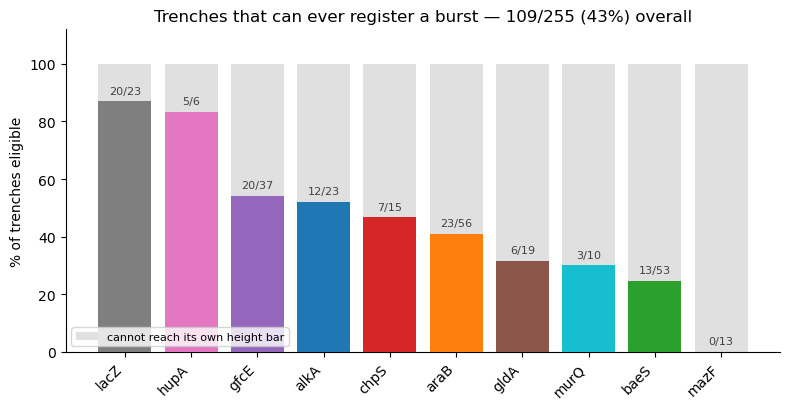

In [21]:
coverage = Bu.burst_coverage(clean, Bu.BURST_DEF_V3)
_cov = (coverage.groupby('gene')
        .agg(trenches=('eligible', 'size'), eligible=('eligible', 'sum'),
             median_headroom_s=('headroom_s', 'median'),
             single_family=('n_families', lambda x: int((x == 1).sum())))
        .assign(pct_eligible=lambda d: (100 * d.eligible / d.trenches).round(0))
        .sort_values('pct_eligible', ascending=False))
print('`headroom_s` = how far the brightest frame sits above the bar, in MAD-scales.\n'
      'Negative median => the typical trench of that gene is structurally ineligible.\n')
print(_cov.round(2).to_string())
print(f'\noverall: {int(coverage.eligible.sum())}/{len(coverage)} eligible '
      f'({100 * coverage.eligible.mean():.0f}%) | '
      f'{int((coverage.n_families == 1).sum())} single-family trenches '
      f'({100 * (coverage.n_families == 1).mean():.0f}%)')

F.plot_burst_coverage(coverage)

# Rates over ELIGIBLE trenches only, beside the published ones. Not a replacement -- the
# eligible subset is selected on brightness, so it is biased the other way -- but the gap
# between the two columns is how much of a gene's low rate is opportunity rather than biology.
_elig = coverage[coverage.eligible][F.KYMO_KEY]
_ce = clean.merge(_elig, on=F.KYMO_KEY)
_ne = _ce.drop_duplicates(F.CELL_KEY).groupby('gene').size()
_be = bursts.merge(_elig, on=F.KYMO_KEY).groupby('gene').size()
_cmp = pd.DataFrame({
    'per_100_cells_all': (100 * bursts.groupby('gene').size() / _uniq).round(2),
    'per_100_cells_eligible': (100 * _be / _ne).round(2),
    'pct_trenches_eligible': _cov['pct_eligible'],
}).fillna(0).sort_values('per_100_cells_all', ascending=False)
print('\n')
print(_cmp.to_string())

### 8g — Would a per-kymograph baseline be better? Evaluated, not shipped

The natural response to 8f: stop normalising to the whole (gene, experiment) population and
normalise to **each kymograph's own** median and MAD instead. Measured below, and the answer is
"it helps coverage a lot, it needs one guard, and it does not fix either worked case".

- **Centre *and* scale per trench** raises coverage 43% → 60% and finds 156 events, but
  **breaks the control**: mazF goes to 0.19 per 100 cells. A quiet trench gets a tiny local MAD,
  so its own noise clears the bar.
- **Centre per trench, scale per (gene, experiment)** changes nothing (89 events) — the offset
  was never the binding constraint.
- **Centre and scale per trench, with the scale floored at 25% of the global one** keeps the
  control intact (hupA and mazF both 0.00) and still lifts coverage to 59% with 153 events. The
  floor is the whole trick: it stops a trench that never does anything from setting its own bar
  to nothing.

**None of them catch Class A or Class B.** Both fail on prominence and shape, not on the height
offset — and for Class A the local scale is *larger* than the global one, so a local baseline
actually raises its prominence bar. Worth considering on its own merits as a coverage fix; it is
not a fix for the events in 8b, and it is left unshipped because 153 events is a large enough
change to want reviewing separately.

In [22]:
_COLS = ('_base_med', '_base_scale')
rows = []
for label, kw in (
        ('gene x experiment (shipped)', dict(scope='gene_experiment')),
        ('per kymograph, no floor',     dict(scope='kymograph', scale_floor_frac=0)),
        ('per kymograph, global scale', dict(scope='kymograph_global_scale')),
        ('per kymograph, floor 0.25',   dict(scope='kymograph', scale_floor_frac=0.25))):
    _d = Bu.attach_kymograph_baselines(clean, **kw)
    _got, _ = Bu.run_burst_detection_any(_d, Bu.BURST_DEF_V3, baseline_cols=_COLS)
    _cv = Bu.burst_coverage(_d, Bu.BURST_DEF_V3, baseline_cols=_COLS)
    _r = (100 * _got.groupby('gene').size().reindex(_uniq.index).fillna(0) / _uniq).round(2)
    _k = [tuple(x) for x in _got[F.KYMO_KEY].to_numpy()]
    rows.append({'baseline scope': label, 'bursts': len(_got),
                 'coverage_%': round(100 * _cv.eligible.mean()),
                 'chpS': _r['chpS'], 'hupA': _r['hupA'], 'mazF': _r['mazF'],
                 'class_A': 'yes' if _k.count(CASE_A) else '-',
                 'class_B': 'yes' if _k.count(CASE_B) else '-'})
print('per-gene figures are bursts per 100 unique cells; hupA and mazF are the acceptance '
      'test\n')
print(pd.DataFrame(rows).to_string(index=False))
print('\nthe unfloored row is the one to reject: mazF 0.19 means the control no longer holds.')

per-gene figures are bursts per 100 unique cells; hupA and mazF are the acceptance test

             baseline scope  bursts  coverage_%  chpS  hupA  mazF class_A class_B
gene x experiment (shipped)      89          43  0.26   0.0  0.00       -       -
    per kymograph, no floor     156          60  0.64   0.0  0.19       -       -
per kymograph, global scale      89          39  0.26   0.0  0.00       -       -
  per kymograph, floor 0.25     153          59  0.64   0.0  0.00       -       -

the unfloored row is the one to reject: mazF 0.19 means the control no longer holds.


### 8h — v3 vs v4, and the export the viewer reads

`BURST_DEF_V4` = v3 with the prominence bar decoupled at `k_prom = 3.7` (full entry in the
changelog). **It is not shipped**: `BURST_DEF` still points at v3, so every table above section
8 is unchanged. This section is for deciding whether to switch, by eye, in the viewer.

**v1 and v2 are no longer compared or drawn.** v3 is v2's exact equal on this dataset — 89
identical events, measured — so its layer was a duplicate, and v1 is superseded. Both dicts
stay in `mmtrack.bursts` because they are the regression fixture against
`data/bursts_082026.csv` (asserted in 8c); they just no longer get a column or a checkbox.

### Every event carries a position now

`add_relative_y` runs inside `build_burst_csv`, so any definition's output gets three position
columns without opting in — the point being that `centroid_y` alone does not identify a cell to
a reader, since it is raw camera pixels and a trench sits in a different pixel band in every
acquisition.

| column | meaning |
|---|---|
| `centroid_y_rel` | 0 at the **open** end, 1 at the closed (mother) end |
| `cell_index_from_open_end` | 0-based rank among the cells present in that frame |
| `n_cells_in_frame` | what that rank is out of — "cell 6 of 9" |
| `trench_span_px` | the denominator, so `centroid_y_rel` is auditable |

`centroid_y_rel`'s denominator is the trench's **occupied extent**
(`min(centroid_y − L/2)` to `max(centroid_y + L/2)` over all its cell-frames), not the image
height — nothing in the tables records image height. In a packed trench the two are close, but
read it as a fraction of what cells occupied.

**Orientation is measured, not assumed:** an individual track's `centroid_y` decreases
monotonically over its lifetime (in 010/1188, track 13 goes 195 → 108 px and track 17 goes
134 → 58), so cells advect toward low y and low y is the open end. The rank is carried
alongside because it needs no denominator at all and so survives a bad extent estimate.

In the viewer each outline is captioned `<track_id> y<centroid_y_rel>` — cyan for v3, green for
v4 — so a burst spotted on the image can be matched back to a row here without counting cells.

In [23]:
_s3, _s4 = _as_set(burst_sets['v3']), _as_set(burst_sets['v4'])
print(f"v3: {len(_s3)} events   v4: {len(_s4)} events   "
      f"(+{len(_s4 - _s3)} gained, -{len(_s3 - _s4)} re-reported earlier)\n")

_rate = lambda d: (100 * d.groupby('gene').size().reindex(_uniq.index).fillna(0)
                   / _uniq).round(2)
_side = pd.DataFrame({'v3': _rate(burst_sets['v3']), 'v4': _rate(burst_sets['v4'])})
_side['delta'] = (_side.v4 - _side.v3).round(2)
_side['constitutive'] = _side.index.isin(F.BURST_DEF['constitutive_genes'])
print('bursts per 100 unique cells\n')
print(_side.sort_values('v4', ascending=False).to_string())
assert _side.loc[['hupA', 'mazF'], 'v4'].eq(0).all(), 'v4 broke the hard constitutive control'

# The export the viewer reads. Written to a NEW file -- data/bursts_082026.csv stays frozen
# as the regression fixture 8c asserts against, and it is the only record of how the shipped
# 89 were made.
#
# NOTE: section 8k REWRITES this same path, adding burst_v5local and burst_v6. Running the
# notebook top to bottom therefore leaves a 5-definition file on disk; this cell alone leaves
# a 3-definition one. 8k is the authoritative writer -- it is last, and it is the one whose
# column set matches the viewer's BURST_VERSIONS.
#
# data/bursts_viewer_v10_090926.csv (v3/v4/v5/v5local) stays on disk as the v5-era record and is no
# longer rewritten by this notebook.
BURSTS_CSV_OUT = f'{REPO_ROOT}/data/bursts_090426.csv'
burst_csv_all = Bu.build_burst_csv({v: burst_sets[v] for v in ('v3', 'v4', 'v5')}, clean,
                                   BURSTS_CSV_OUT,
                                   raw_csv=f'{REPO_ROOT}/data/all_data_082026.csv')
print(f"\ntrenches with >=1 burst under any definition: "
      f"{burst_csv_all[F.KYMO_KEY].drop_duplicates().shape[0]}")
print('  ' + ' | '.join(f'{v} {int(burst_csv_all[f"burst_{v}"].sum())}'
                        for v in ('v3', 'v4', 'v5'))
      + f" | v3-only {int((burst_csv_all.burst_v3 & ~burst_csv_all.burst_v4).sum())}"
      + f" | v4-only {int((~burst_csv_all.burst_v3 & burst_csv_all.burst_v4).sum())}"
      + f" | v5-only {int((~burst_csv_all.burst_v4 & burst_csv_all.burst_v5).sum())}")

POS = ['centroid_y', 'centroid_y_rel', 'cell_index_from_open_end', 'n_cells_in_frame']
print(f'\nthe {len(_s4 - _s3)} events v4 adds -- these are the ones to check in the viewer.')
print('`viewer_frame` is what the kymograph axis prints; `time_frame` is what this table '
      'stores (8a).\n')
_new = burst_csv_all[~burst_csv_all.burst_v3 & burst_csv_all.burst_v4].copy()
_new = _new.merge(cand[_key + ['prom_s', 'prom_ratio', 'binding_side']], on=_key, how='left')
_new['viewer_frame'] = [
    r.time_frame + F.trench_start_frame(r.experiment_name, r.FOV, r.trench_id,
                                        data_root=REPO_ROOT)
    for r in _new.itertuples()]
print(_new[['gene', 'experiment_name', 'FOV', 'trench_id', 'track_id', 'time_frame',
            'viewer_frame'] + POS + ['prom_s', 'prom_ratio']]
      .sort_values('prom_s', ascending=False).round(3).to_string(index=False))

for _e, _f, _t in (CASE_A, ('DUMM_giTG066_063_120925', '007', '874')):
    print(f'\n{_e} {_f}/{_t}:')
    _s = F.select_trench(burst_csv_all, _e, _f, _t).sort_values('time_frame')
    print(_s[['time_frame', 'track_id', 'burst_v3', 'burst_v4'] + POS + ['fluor']]
          .round(3).to_string(index=False))

print(f"""
Regenerate the viewer (needs /Volumes/mcovert mounted):

    python generate_kymograph_viewer.py \\
        --burst-csv data/bursts_viewer_v10_090926.csv \\
        --output data/kymograph_viewer_bursts_090926c.html

Layers: 'Burst v4' (green) and 'Burst v5' (magenta) -- the live decision boundary. An outline
in magenta but not green is one of section 8i's fold-route events.""")

v3: 89 events   v4: 99 events   (+11 gained, -1 re-reported earlier)

bursts per 100 unique cells

        v3    v4  delta  constitutive
gene                                 
lacZ  2.26  2.39   0.13         False
gfcE  0.92  0.98   0.06         False
araB  0.85  0.94   0.09         False
gldA  0.90  0.90   0.00         False
alkA  0.89  0.89   0.00         False
chpS  0.26  0.51   0.25          True
murQ  0.40  0.40   0.00         False
baeS  0.15  0.26   0.11         False
hupA  0.00  0.00   0.00          True
mazF  0.00  0.00   0.00          True
wrote /Users/adrianjuarez/Documents/Covert_lab/repos/mother_machine_cell_tracker/data/bursts_090426.csv  (119 rows)
rows per definition: v3=89 | v4=99 | v5=118
by route: absolute=100 | fold=19

trenches with >=1 burst under any definition: 81
  v3 89 | v4 99 | v5 118 | v3-only 1 | v4-only 11 | v5-only 19

the 11 events v4 adds -- these are the ones to check in the viewer.
`viewer_frame` is what the kymograph axis prints; `time_frame` is what

### 8i — v5: a second route in, for bursts that are big relative to a dim trench

A third trench was reported as visibly bursting and caught by nothing: alkA
`DUMM_giTG069_063_121125 | FOV 001 | trench 1192`. It is neither Class A nor Class B.

`start = 24` there, so the viewer's frames 26–30 are `time_frame` **2–6**, where `track_id 2`
climbs 0.0503 → 0.1755 a.u./ms — a **3.5× rise**. And yet it produces **zero height-clearing
candidates** under v3 *and* v4, so prominence is never even consulted:

| gate | value | bar | |
|---|---|---|---|
| height | **1.91 s** above the alkA × experiment median | 4.0 | fails by 52% |
| MAD-prominence | 3.005 s | 3.7 | fails |
| **fold** = peak ÷ higher base | **3.60×** | — | vs **3.64×** for the reference araB burst |

The whole trench envelope tops out at 0.1907 against a bar of 0.2864 — `eligible = False`,
`headroom = −2.09 s` — while every alkA burst that *is* counted in that experiment sits at
0.30–0.39. Section 8g's per-kymograph baseline does not rescue it either (3.14 local s).

**So the miss is structural.** Every gate in v1–v4 is absolute *within a gene*. When a trench
sits below its gene's median throughout, a large **relative** excursion inside it is a small
**absolute** one, and the height gate discards it before any measure of rise is applied. The
detector is absolute-within-gene; the eye is relative-within-trench. That is the whole of it.

### Fold prominence, and why it does not cost the control

`fold = peak / max(left_base, right_base)` is **unit-free**, so a single bar serves the 283×
spread of gene brightness with no baseline at all — and it is a *relief* measure, so a
flat-high constitutive trace scores ~1.0 no matter how bright it is. That is the same property
that makes MAD-prominence work, expressed as a ratio instead of a difference.

The three controls top out well below the motivating case, which is what makes a bar possible
at all. But the window is **narrow** — `(3.10, 3.60]` — and 3.3 is only its midpoint, ~7% clear
on each side. Report that band with any number derived from it.

**Fold is a second route, not a replacement.** On its own it finds 67 events and fails all
three regression trenches, because it misses the bright canonical bursts. The cell below
measures that, so nobody "simplifies" v5 into fold-only later.

In [24]:
# The fold distribution over every local maximum on the family envelopes -- no height gate,
# because the whole point of the fold route is peaks that never clear one.
#
# `is_local_max` matters here: burst_candidates records every peak find_peaks returns and
# reports the +/-window check as a column rather than filtering on it, so the raw frame also
# contains shoulders the detector would never admit. Comparing the controls against THAT
# population overstates their best fold. Filter to what detection actually considers.
cand5 = Bu.burst_candidates(clean, Bu.BURST_DEF_V5)
_fold = cand5[cand5.fold.notna() & cand5.is_local_max]
print(f'{len(_fold)} local maxima on the family envelopes '
      f'({int((cand5.fold.notna() & ~cand5.is_local_max).sum())} non-local-max peaks '
      f'excluded)\n')
_t = (_fold.groupby('gene')['fold']
      .describe(percentiles=[.5, .9, .99])[['count', '50%', '90%', '99%', 'max']])
_t['constitutive'] = _t.index.isin(F.BURST_DEF['constitutive_genes'])
print(_t.round(2).to_string())

_ctrl = _fold[_fold.gene.isin(F.BURST_DEF['constitutive_genes'])].groupby('gene').fold.max()
_caseC = _fold[(_fold.experiment_name == 'DUMM_giTG069_063_121125')
               & (_fold.FOV == '001') & (_fold.trench_id == '1192')].fold.max()
print(f"\ncontrol maxima: " + '  '.join(f'{g}={v:.2f}x' for g, v in _ctrl.items()))
print(f'Case C: {_caseC:.2f}x  ->  safe window ({_ctrl.max():.2f}, {_caseC:.2f}], '
      f"shipped bar {Bu.BURST_DEF_V5['fold_prom']}")
assert _ctrl.max() < Bu.BURST_DEF_V5['fold_prom'] < _caseC, 'the fold bar left its window'

print('\ncounts above a fold bar, by gene (before any merge):')
_lv = [2.0, 2.5, 3.0, 3.3, 3.6, 4.0]
_tab = pd.DataFrame({f'{L:g}x': _fold[_fold.fold >= L].groupby('gene').size()
                     for L in _lv}).fillna(0).astype(int)
_tab.loc['ALL'] = [int((_fold.fold >= L).sum()) for L in _lv]
print(_tab.to_string())

1941 local maxima on the family envelopes (5055 non-local-max peaks excluded)

      count   50%   90%   99%   max  constitutive
gene                                             
alkA  195.0  1.57  2.56  6.02  9.43         False
araB  341.0  1.34  1.84  3.47  4.00         False
baeS  365.0  1.35  1.94  3.05  4.18         False
chpS  166.0  1.32  2.01  2.93  3.10          True
gfcE  298.0  1.61  2.78  5.18  9.83         False
gldA  181.0  1.56  2.89  6.11  8.08         False
hupA   31.0  1.20  1.38  1.67  1.76          True
lacZ  242.0  1.39  2.30  4.37  7.05         False
mazF   70.0  1.34  1.73  2.51  2.94          True
murQ   52.0  1.30  2.16  3.22  3.30         False

control maxima: chpS=3.10x  hupA=1.76x  mazF=2.94x
Case C: 3.60x  ->  safe window (3.10, 3.60], shipped bar 3.3

counts above a fold bar, by gene (before any merge):
       2x  2.5x  3x  3.3x  3.6x  4x
gene                               
alkA   50    24  12    11    10   8
araB   28    15   8     5     3   1
baeS   32 

viewer frame 26 -> time_frame 2  (start = 24)

track 2, the reported cell:
 time_frame  fluor_per_ms  centroid_y  axis_major_length  area
          0        0.0503    317.3314            27.9017 350.0
          1        0.0648    317.3422            28.8716 374.0
          2        0.0692    314.3318            36.5404 443.0
          3        0.1124    312.3246            39.5174 422.0
          4        0.1204    310.4800            42.1220 450.0
          5        0.1755    308.8556            46.5060 478.0
          6        0.1708    306.7543            50.8965 525.0
          7        0.1611    304.7776            54.4055 553.0
          8        0.1717    303.5000            60.0635 598.0

coverage for this trench:
gene         experiment_name FOV trench_id  env_max    bar  eligible  headroom_s  n_families
alkA DUMM_giTG069_063_121125 001      1192   0.1907 0.2148     False     -0.8561           2



the strongest candidate in this trench, by fold:
 time_frame  track_id  fluor  threshold  height_s  prom_s  fold route     verdict
          9         4  0.191      0.286     1.914   3.005 3.597  fold       burst
         30        19  0.179      0.286     1.655   1.871 1.921       height+fold
         50        43  0.131      0.286     0.616   0.770 1.368       height+fold


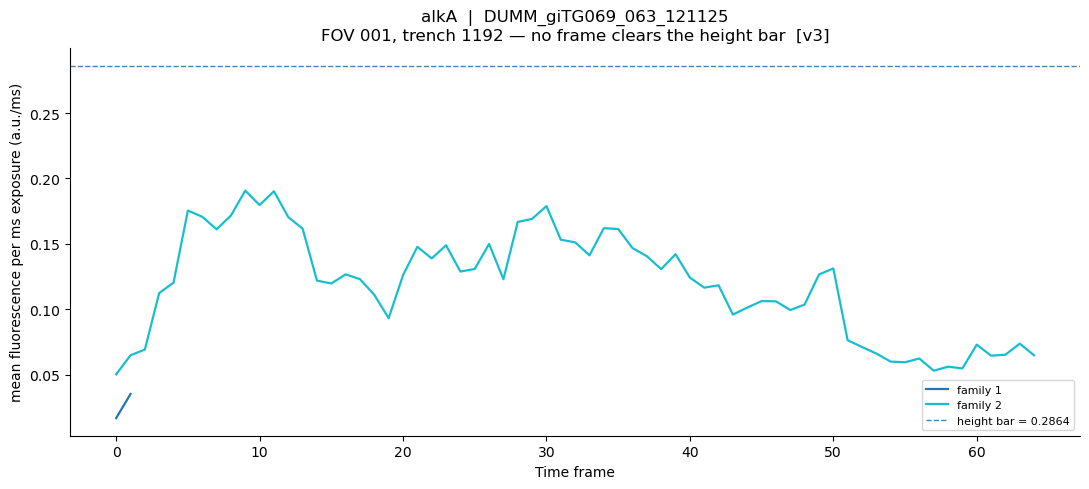

In [25]:
# Case C, worked. The trench cannot clear its bar at all, so plot_prominence_bases draws no
# candidate -- that absence IS the finding.
CASE_C = ('DUMM_giTG069_063_121125', '001', '1192')
print(f'viewer frame 26 -> time_frame '
      f'{F.viewer_frame_to_time_frame(*CASE_C, 26, data_root=REPO_ROOT)}  '
      f'(start = {F.trench_start_frame(*CASE_C, data_root=REPO_ROOT)})\n')

_tr = F.select_trench(clean, *CASE_C)
print('track 2, the reported cell:')
print(_tr[_tr.track_id == 2].sort_values('time_frame')[
    ['time_frame', F.FLUOR_COL, 'centroid_y', 'axis_major_length', 'area']]
    .round(4).to_string(index=False))

print('\ncoverage for this trench:')
print(Bu.burst_coverage(_tr, Bu.BURST_DEF_V3).round(4).to_string(index=False))
F.plot_prominence_bases(clean, *CASE_C, bdef=Bu.BURST_DEF_V3)

print('\nthe strongest candidate in this trench, by fold:')
print(F.select_trench(cand5, *CASE_C).nlargest(3, 'fold')[
    ['time_frame', 'track_id', 'fluor', 'threshold', 'height_s', 'prom_s', 'fold',
     'route', 'verdict']].round(3).to_string(index=False))

In [26]:
# v5 against v4, and the fold bar sweep. hupA and mazF are the acceptance test.
_s5 = _as_set(burst_sets['v5'])          # built once in section 8c, alongside v1-v4

# The property that makes the two comparable: v5 only ever ADDS.
assert _as_set(burst_sets['v4']) <= _s5, 'v5 dropped a v4 event -- it must be a superset'
print(f"v4 {len(burst_sets['v4'])} -> v5 {len(burst_sets['v5'])} events "
      f"(+{len(_s5 - _as_set(burst_sets['v4']))}), and v5 is a strict superset of v4")
print(burst_sets['v5'].route.value_counts().to_string())

_rows = []
for _fb in (None, 3.0, 3.3, 3.6):
    _bd = ({**Bu.BURST_DEF_V4} if _fb is None
           else {**Bu.BURST_DEF_V5, 'fold_prom': _fb})
    _d, _ = Bu.run_burst_detection_any(clean, _bd)
    _k = [tuple(x) for x in _d[F.KYMO_KEY].to_numpy()]
    for _kk, _w in REG.items():
        assert _k.count(_kk) == _w, f'fold={_fb}: {_kk} gave {_k.count(_kk)}, want {_w}'
    _r = (100 * _d.groupby('gene').size().reindex(_uniq.index).fillna(0) / _uniq).round(2)
    _rows.append({'fold_bar': _fb or 'off (v4)', 'bursts': len(_d),
                  'fold_route': int((_d.route == 'fold').sum()),
                  'caught_C': 'yes' if _k.count(CASE_C) else '-',
                  **{g: _r[g] for g in ('lacZ', 'gldA', 'gfcE', 'alkA', 'chpS',
                                        'hupA', 'mazF')}})
print('\nheight bar 4.0 and k_prom 3.7 throughout; per-gene = bursts per 100 unique cells\n')
print(pd.DataFrame(_rows).to_string(index=False))
print('\nall three regression trenches hold at every fold bar above.')

# Fold alone is not a substitute -- this is the cell that stops that "simplification".
_alone, _ = Bu.run_burst_detection_any(
    clean, {**Bu.BURST_DEF_V5, 'k': 99.0, 'k_prom': 99.0})   # height unreachable
_ka = [tuple(x) for x in _alone[F.KYMO_KEY].to_numpy()]
print(f'\nfold route ALONE (absolute bar made unreachable): {len(_alone)} events, '
      f'regressions ' + ' '.join(f'{k[2]}={_ka.count(k)}/{w}' for k, w in REG.items())
      + '  -> it misses canonical bursts, so it can only ever be a SECOND route.')
assert any(_ka.count(k) != w for k, w in REG.items()), (
    'fold alone now passes every regression trench -- re-read section 8i, the claim that it '
    'cannot replace the absolute rule no longer holds')

v4 99 -> v5 118 events (+19), and v5 is a strict superset of v4
route
absolute    99
fold        19



height bar 4.0 and k_prom 3.7 throughout; per-gene = bursts per 100 unique cells

fold_bar  bursts  fold_route caught_C  lacZ  gldA  gfcE  alkA  chpS  hupA  mazF
off (v4)      99           0        -  2.39  0.90  0.98  0.89  0.51   0.0   0.0
     3.0     128          29      yes  2.46  2.19  1.44  1.38  0.51   0.0   0.0
     3.3     118          19      yes  2.46  1.93  1.31  1.28  0.51   0.0   0.0
     3.6     113          14        -  2.46  1.67  1.18  1.19  0.51   0.0   0.0

all three regression trenches hold at every fold bar above.



fold route ALONE (absolute bar made unreachable): 48 events, regressions 1598=1/1 821=1/1 1488=0/4  -> it misses canonical bursts, so it can only ever be a SECOND route.


In [27]:
# Per-gene effect, split by route, beside the coverage that explains it.
_r4 = (100 * burst_sets['v4'].groupby('gene').size().reindex(_uniq.index).fillna(0)
       / _uniq).round(2)
_r5 = (100 * burst_sets['v5'].groupby('gene').size().reindex(_uniq.index).fillna(0)
       / _uniq).round(2)
_eff = pd.DataFrame({'v4': _r4, 'v5': _r5})
_eff['delta'] = (_eff.v5 - _eff.v4).round(2)
_eff['fold_route'] = (burst_sets['v5'][burst_sets['v5'].route == 'fold']
                      .groupby('gene').size().reindex(_uniq.index).fillna(0).astype(int))
_eff['pct_trenches_eligible'] = _cov['pct_eligible']
_eff['constitutive'] = _eff.index.isin(F.BURST_DEF['constitutive_genes'])
print('bursts per 100 unique cells\n')
print(_eff.sort_values('v5', ascending=False).to_string())
assert _eff.loc[['hupA', 'mazF'], 'v5'].eq(0).all(), 'v5 broke the hard control'
print('\ngldA moves 4th -> 2nd. Read that against pct_trenches_eligible: gldA had only 32% '
      'of\nits trenches able to clear the absolute bar, so its old rate was partly a '
      'statement about\nopportunity. Do not quote the new ranking without section 8f.')

print('\n\nthe fold-route events -- these are what to check in the viewer (magenta, not green):')
_f5 = burst_sets['v5'][burst_sets['v5'].route == 'fold'].copy()
_f5 = _f5.merge(cand5[_key + ['height_s', 'prom_s', 'fold']], on=_key, how='left')
_f5['viewer_frame'] = [
    r.time_frame + F.trench_start_frame(r.experiment_name, r.FOV, r.trench_id,
                                        data_root=REPO_ROOT)
    for r in _f5.itertuples()]
print(_f5[['gene', 'experiment_name', 'FOV', 'trench_id', 'track_id', 'time_frame',
           'viewer_frame', 'fluor', 'threshold', 'height_s', 'fold']]
      .sort_values(['gene', 'fold'], ascending=[True, False]).round(3).to_string(index=False))

bursts per 100 unique cells

        v4    v5  delta  fold_route  pct_trenches_eligible  constitutive
gene                                                                    
lacZ  2.39  2.46   0.07           1                   87.0         False
gldA  0.90  1.93   1.03           8                   32.0         False
gfcE  0.98  1.31   0.33           5                   54.0         False
alkA  0.89  1.28   0.39           4                   52.0         False
araB  0.94  0.99   0.05           1                   41.0         False
chpS  0.51  0.51   0.00           0                   47.0          True
murQ  0.40  0.40   0.00           0                   30.0         False
baeS  0.26  0.26   0.00           0                   25.0         False
hupA  0.00  0.00   0.00           0                   83.0          True
mazF  0.00  0.00   0.00           0                    0.0          True

gldA moves 4th -> 2nd. Read that against pct_trenches_eligible: gldA had only 32% of
its trenc

### The class this fixes, and what is still missed

The 36 trenches below are ineligible on height yet contain a large internal rise — the
population Case C came from, and the reason it kept turning up by eye. It is concentrated in
exactly the genes section 8f flagged as having the worst coverage.

Still missed, deliberately: **Case B** (baeS 002/1979) remains uncounted under v5. It is a
sustained ramp with a fold of only 1.40×, so neither route reaches it, and section 9 is where
it lives. The three cases now sit in three different places, which is the honest outcome:
Case A is a v4 burst, Case C is a v5 burst, Case B is not a burst.

In [28]:
_cov_fold = (Bu.burst_coverage(clean, Bu.BURST_DEF_V3)
             .merge(cand5.groupby(F.KYMO_KEY)['fold'].max().rename('best_fold'),
                    on=F.KYMO_KEY, how='left'))
_inel = _cov_fold[~_cov_fold.eligible]
print(f'ineligible trenches (envelope never reaches the gene bar): '
      f'{len(_inel)} of {len(_cov_fold)}')
for _L in (2.0, 2.5, 3.0, 3.3):
    _n = int((_inel.best_fold >= _L).sum())
    print(f'  with an internal fold rise >= {_L}x: {_n} '
          f'({100 * _n / len(_cov_fold):.0f}% of all trenches)')

_by = (_inel.assign(big=_inel.best_fold >= 2.5).groupby('gene')
       .agg(ineligible=('big', 'size'), with_big_rise=('big', 'sum')))
_by['pct_of_gene_trenches'] = (100 * _by.with_big_rise
                               / _cov_fold.groupby('gene').size()).round(0)
print('\nineligible trenches with a >= 2.5x internal rise, by gene:\n')
print(_by.sort_values('pct_of_gene_trenches', ascending=False).to_string())

print('\nCase B under v5 -- still 0, and why:')
_b = F.select_trench(cand5, 'DUMM_giTG066_063_120925', '002', '1979')
print(f'  best fold in that trench: {_b.fold.max():.2f}x  '
      f"(bar {Bu.BURST_DEF_V5['fold_prom']}), best height {_b.height_s.max():.2f} s (bar 4.0)")
assert len(F.select_trench(burst_sets['v5'], 'DUMM_giTG066_063_120925', '002', '1979')) == 0

ineligible trenches (envelope never reaches the gene bar): 146 of 255
  with an internal fold rise >= 2.0x: 71 (28% of all trenches)
  with an internal fold rise >= 2.5x: 36 (14% of all trenches)
  with an internal fold rise >= 3.0x: 22 (9% of all trenches)
  with an internal fold rise >= 3.3x: 15 (6% of all trenches)

ineligible trenches with a >= 2.5x internal rise, by gene:

      ineligible  with_big_rise  pct_of_gene_trenches
gene                                                 
gldA          13              8                  42.0
gfcE          17             10                  27.0
chpS           8              3                  20.0
alkA          11              4                  17.0
murQ           7              1                  10.0
lacZ           3              2                   9.0
baeS          40              4                   8.0
mazF          13              1                   8.0
araB          33              3                   5.0
hupA           1         

### 8j — Should the baseline be per kymograph rather than per (gene, experiment)?

Every definition so far scopes its baseline to **(gene, experiment)**. Sections 8f and 8i both
ran into the consequence: a trench that sits below its gene's median can never clear the height
bar. So the obvious question is whether the baseline should be per **kymograph** instead.

The premise checks out. Within a single (gene, experiment), the median of trench-median
fluorescence spans a **median of 2.11×**, and 6 of 23 groups exceed 3×:

| gene × experiment | trenches | trench min → max (a.u./ms) | fold |
|---|---|---|---|
| mazF `DUMM_mazF_murQ_121625` | 7 | 0.040 → 0.440 | **10.99** |
| araB `DUMM_CL008_080825` | 20 | 0.003 → 0.026 | **7.68** |
| alkA `DUMM_giTG63_giTG67_Glucose_121724` | 5 | 0.004 → 0.020 | 5.48 |
| gfcE `DUMM_giTG064_Glucose_022625` | 17 | 0.006 → 0.030 | 5.14 |
| lacZ `DUMM_giTG059_noKan_Glucose_031125` | 7 | 0.006 → 0.025 | 4.52 |

A shared ruler is being handed to trenches that differ up to 11-fold. The new
**Fluor (trench-normalized)** layer in the viewer shows the same thing per cell.

Four scopes, crossed with v3/v4/v5. `attach_kymograph_baselines` and `detect_bursts`'
`baseline_cols` already exist for this — §8g ran the v3 row.

- `gene × experiment` — the shipped rule.
- `kymo, local scale` — centre *and* scale from the trench.
- `kymo, global scale` — centre from the trench, scale from the (gene, experiment).
- `kymo, floor 0.25` — local, with the scale floored at 25% of the global one.

**The prediction to test:** the fold route is a *ratio*, so it is baseline-independent. A local
baseline should therefore only move the height gate and the fold floor — meaning v5 should
catch Case C under every scope, while Case A's fate depends entirely on the scope.

In [29]:
SCOPES = {
    'gene x experiment':  dict(scope='gene_experiment'),
    'kymo, local scale':  dict(scope='kymograph', scale_floor_frac=0),
    'kymo, global scale': dict(scope='kymograph_global_scale'),
    'kymo, floor 0.25':   dict(scope='kymograph', scale_floor_frac=0.25),
}
_BC = ('_base_med', '_base_scale')
CASE_TRENCHES = {'A': CASE_A, 'B': CASE_B, 'C': CASE_C}

_prepped = {n: Bu.attach_kymograph_baselines(clean, **kw) for n, kw in SCOPES.items()}
_scope_sets, _rows = {}, []
for _sn, _d in _prepped.items():
    _cov = Bu.burst_coverage(_d, Bu.BURST_DEF_V3, baseline_cols=_BC)
    for _v in ('v3', 'v4', 'v5'):
        _got, _ = Bu.run_burst_detection_any(_d, Bu.BURST_DEFS[_v], baseline_cols=_BC)
        _scope_sets[(_sn, _v)] = (_got, _cov)
        _k = [tuple(x) for x in _got[F.KYMO_KEY].to_numpy()] if len(_got) else []
        _r = (100 * _got.groupby('gene').size().reindex(_uniq.index).fillna(0)
              / _uniq).round(2)
        _rows.append({
            'scope': _sn, 'def': _v, 'bursts': len(_got),
            'fold': int((_got.route == 'fold').sum()) if 'route' in _got else 0,
            'coverage_%': round(100 * _cov.eligible.mean()),
            **{_t: ('Y' if _k.count(_kk) else '.') for _t, _kk in CASE_TRENCHES.items()},
            'reg': '/'.join(str(_k.count(_kk)) for _kk in REG),
            'chpS': _r['chpS'], 'hupA': _r['hupA'], 'mazF': _r['mazF'],
            'mazF_rank': int(_r.rank(ascending=False, method='max')['mazF']),
        })
print('A / B / C = the three worked cases caught.  reg = the three changelog trenches, '
      'want 1/1/4.\n')
print(pd.DataFrame(_rows).to_string(index=False))

# The regression trenches are bright enough to survive any scope -- assert that, since if it
# ever stops being true the comparison below is no longer like-for-like.
for _sn, _v in _scope_sets:
    _g = _scope_sets[(_sn, _v)][0]
    _k = [tuple(x) for x in _g[F.KYMO_KEY].to_numpy()]
    for _kk, _w in REG.items():
        assert _k.count(_kk) == _w, f'{_sn}/{_v}: {_kk} gave {_k.count(_kk)}, want {_w}'
print('\nall three regression trenches give 1/1/4 under EVERY scope -- they are bright '
      'enough that\nthe choice of baseline does not reach them.')

A / B / C = the three worked cases caught.  reg = the three changelog trenches, want 1/1/4.

             scope def  bursts  fold  coverage_% A B C   reg  chpS  hupA  mazF  mazF_rank
 gene x experiment  v3      89     0          43 . . . 1/1/4  0.26   0.0  0.00         10
 gene x experiment  v4      99     0          43 Y . . 1/1/4  0.51   0.0  0.00         10
 gene x experiment  v5     118    19          43 Y . Y 1/1/4  0.51   0.0  0.00         10
 kymo, local scale  v3     156     0          60 . . . 1/1/4  0.64   0.0  0.19          9
 kymo, local scale  v4     169     0          60 . . . 1/1/4  0.77   0.0  0.19          9
 kymo, local scale  v5     183    14          60 . . Y 1/1/4  0.77   0.0  0.19          9
kymo, global scale  v3      89     0          39 . . . 1/1/4  0.26   0.0  0.00         10
kymo, global scale  v4      94     0          39 Y . . 1/1/4  0.39   0.0  0.00         10
kymo, global scale  v5     114    20          39 Y . Y 1/1/4  0.39   0.0  0.00         10
  kymo,

### What the cross says

**The fold route is scope-independent, as predicted.** Case C is caught under all four scopes
— but only by v5. Under v3 and v4 it stays missed even with a local baseline (3.14 local
MAD-scales against a 4.0 bar), because a local baseline moves the *centre*, not the *shape* of
the excursion. So the fold route, not a re-scoped baseline, is what actually reaches that class.

**Case A is the price of a local scale.** The trench's own MAD is larger than its gene's, so
the same event that stands 5.38 MAD-scales above the gene baseline stands only **3.66** above
its own — under the bar. Both local-*scale* scopes lose it:

| scope | Case A | Case B | Case C | (height bar 4.0) |
|---|---|---|---|---|
| gene × experiment | **5.38 s** ✓ | 1.49 s | 1.91 s | |
| kymo, local scale | 3.66 s ✗ | 3.40 s | 3.14 s | |
| kymo, global scale | 4.86 s ✓ | 2.13 s | 1.93 s | |
| kymo, floor 0.25 | 3.66 s ✗ | 3.40 s | 3.14 s | |

**The floor is still essential, and now for a second reason.** Unfloored, `kymo, local scale`
puts mazF at 0.19 per 100 cells and drops it to 9th — the control breaks, exactly as it did for
v3 in §8g. Floored at 25%, mazF returns to 0.00 and 10th at every definition.

**And a genuinely reassuring result:** under the floored local scope mazF's trench eligibility
rises from **0% to 23%** — it becomes able to register a burst for the first time — and it
*still* scores 0.00. The control is passing on its merits there, not by being structurally
excluded.

`kymo, global scale` is the one scope that keeps Case A, but it is not a good trade either: its
coverage *falls* to 39% (below the shipped 43%) and it loses 5 of v4's 99 events.

In [30]:
_, _rg = _scope_sets[('gene x experiment', 'v5')]
_gl, _cg = _scope_sets[('gene x experiment', 'v5')]
_lo, _cl = _scope_sets[('kymo, floor 0.25', 'v5')]
_rate = lambda d: (100 * d.groupby('gene').size().reindex(_uniq.index).fillna(0)
                   / _uniq).round(2)
_cmp = pd.DataFrame({
    'v5_global': _rate(_gl), 'v5_local': _rate(_lo),
    'delta': (_rate(_lo) - _rate(_gl)).round(2),
    'elig_global_%': (100 * _cg.groupby('gene').eligible.mean()).round(0),
    'elig_local_%': (100 * _cl.groupby('gene').eligible.mean()).round(0),
})
_cmp['constitutive'] = _cmp.index.isin(F.BURST_DEF['constitutive_genes'])
print('v5 under the shipped scope vs the floored local scope, per 100 unique cells\n')
print(_cmp.sort_values('v5_local', ascending=False).to_string())
assert _cmp.loc[['hupA', 'mazF'], 'v5_local'].eq(0).all(), (
    'the floored local scope broke the hard control')
print(f'\ntotal events: {len(_gl)} -> {len(_lo)}   '
      f'coverage: {100 * _cg.eligible.mean():.0f}% -> {100 * _cl.eligible.mean():.0f}%')
print('mazF eligibility 0% -> 23% and it still scores 0.00 -- the control passes on merit '
      'there,\nnot by being structurally unable to fire.')

v5 under the shipped scope vs the floored local scope, per 100 unique cells

      v5_global  v5_local  delta  elig_global_%  elig_local_%  constitutive
gene                                                                       
lacZ       2.46      3.28   0.82           87.0         100.0         False
gldA       1.93      2.70   0.77           32.0          68.0         False
gfcE       1.31      2.62   1.31           54.0          68.0         False
alkA       1.28      1.78   0.50           52.0          65.0         False
araB       0.99      1.61   0.62           41.0          61.0         False
murQ       0.40      0.79   0.39           30.0          40.0         False
chpS       0.51      0.77   0.26           47.0          40.0          True
baeS       0.26      0.38   0.12           25.0          42.0         False
hupA       0.00      0.00   0.00           83.0          83.0          True
mazF       0.00      0.00   0.00            0.0          23.0          True

total even

### Recommendation: keep the (gene, experiment) baseline

Not because the local one is broken — floored, it keeps both hard controls at zero, and it
lifts coverage from 43% to 59% — but because of what it costs and what it does not buy:

1. **It trades away a confirmed burst.** Case A is the event v4 exists to catch, validated by
   eye in the viewer. A scope change that drops it is moving backwards on the one case we are
   most sure about.
2. **It does not reach the class it was proposed for.** Case C needed the fold route, not a
   re-scoped baseline — under v3/v4 a local baseline still misses it.
3. **The +63 events it adds are unvalidated.** v5's 19 fold-route events were each checked
   against a control distribution with a stated guard band; a near-doubling of the count from
   a scope change has had no equivalent scrutiny.

**The mechanism that actually addresses trench-to-trench variation is the fold route**, because
it is a ratio: it is already immune to where a trench sits, without disturbing the absolute
route or the events that route has confirmed. That is why v5 catches Case C under every scope
in the table above.

Left as an evaluated variant, not promoted to a definition. If the coverage argument is
revisited, the floored local scope is the only candidate worth re-running — and the first thing
to check is whether Case A can be recovered, since a scope that loses it is not shippable.
The **Fluor (trench-normalized)** viewer layer is the tool for judging that by eye.

### 8k — What the local baseline actually finds

§8j recommended against re-scoping, but the event set it produces is worth looking at rather
than only counting. This section exports it so it can be inspected in the viewer.

**It is not "+63 new events".** 118 → 181 is the net of **+77 gained and −14 lost**:

| | count |
|---|---|
| shared with global-scope v5 | 104 |
| gained by the local scope | **77** |
| lost by the local scope | **14** |

**The mechanism is exactly what it should be, which is reassuring rather than not.** The gained
events sit in trenches *quieter* than their gene (median `scale_ratio` = local MAD ÷ global MAD
of **0.63**, and 75 of 77 below 1.0); the lost ones sit in trenches *noisier* than their gene
(median **1.19**, 9 of 14 above 1.0). Nothing here is random — a local bar is lower in a quiet
trench and higher in a busy one, and the two sets divide along precisely that line.

**36 trenches gain their first burst**, which is the coverage argument made concrete.

### The 14 losses, split honestly

Only **5 trenches go completely dark** — araB 003/312, **chpS 010/1188 (Case A)**,
gfcE 015/1433, baeS 018/1260, baeS 020/732. The other 9 keep an event, but mostly at a
*different* frame rather than the same episode shifted: only alkA 001/807 (4→3),
baeS 007/874 (13→8) and gfcE 020/874 (10→15) land within the 5-frame merge window. For the
rest — gldA 007/1124 at 39 → 100, chpS 005/1277 at 131 → 75, lacZ 020/589 at 82 → 16 — the
specific event is genuinely gone even though the trench is still flagged somewhere.

So the cost is **5 trenches losing their only burst plus ~6 individual events**, against 77
gained. Case A is in the dark five, and remains the reason §8j does not recommend shipping this.

### Reading the export

`burst_v5local` is a column in `data/bursts_090326.csv` and an orange layer in the viewer.
**Its `threshold` is that trench's local bar, not its gene's** — the new `baseline_scope`
column says which, per row, so the two kinds of number are never silently mixed. Rows shared
with a gene-scoped definition report the gene bar, because the gene-scoped sets are passed
first.

In [31]:
# The local-scope set, and exactly how it differs from shipped v5.
_locf = Bu.attach_kymograph_baselines(clean, scope='kymograph', scale_floor_frac=0.25)
burst_sets['v5local'], _ = Bu.run_burst_detection_any(
    _locf, Bu.BURST_DEF_V5, baseline_cols=_BC)
_v5, _v5l = burst_sets['v5'], burst_sets['v5local']
_sg, _sl = _as_set(_v5), _as_set(_v5l)
print(f'v5 global {len(_sg)}   v5 local {len(_sl)}   '
      f'| shared {len(_sg & _sl)}  gained {len(_sl - _sg)}  lost {len(_sg - _sl)}')
assert len(_sg) + len(_sl - _sg) - len(_sg - _sl) == len(_sl)

# Per-trench local baseline, so every event can be read against BOTH bars.
_lb = (_locf.groupby(F.KYMO_KEY)[list(_BC)].first()
       .rename(columns={_BC[0]: 'local_med', _BC[1]: 'local_scale'}))
_gb = F.compute_baselines(clean, fluor_col=F.FLUOR_COL)


def _annotate(d):
    """Both baselines side by side. `scale_ratio` < 1 = this trench is quieter than its gene."""
    d = d.merge(_lb, on=F.KYMO_KEY, how='left')
    d['g_med'] = [_gb.loc[(g, e), 'median'] for g, e in zip(d.gene, d.experiment_name)]
    d['g_scale'] = [_gb.loc[(g, e), 'mad_scale'] for g, e in zip(d.gene, d.experiment_name)]
    d['local_thr'] = (d.local_med + 4.0 * d.local_scale).round(4)
    d['global_thr'] = (d.g_med + 4.0 * d.g_scale).round(4)
    d['h_local_s'] = ((d.fluor - d.local_med) / d.local_scale).round(2)
    d['h_global_s'] = ((d.fluor - d.g_med) / d.g_scale).round(2)
    d['scale_ratio'] = (d.local_scale / d.g_scale).round(2)
    d['viewer_frame'] = [
        r.time_frame + F.trench_start_frame(r.experiment_name, r.FOV, r.trench_id,
                                            data_root=REPO_ROOT)
        for r in d.itertuples()]
    return d


gained = _annotate(_v5l[_v5l[_key].apply(tuple, axis=1).isin(_sl - _sg)].copy())
lost = _annotate(_v5[_v5[_key].apply(tuple, axis=1).isin(_sg - _sl)].copy())

print(f'\nmechanism check -- gained should sit in QUIETER trenches, lost in NOISIER ones:')
print(f'  gained: median scale_ratio {gained.scale_ratio.median():.2f}  '
      f'({int((gained.scale_ratio < 1).sum())}/{len(gained)} below 1.0)')
print(f'  lost:   median scale_ratio {lost.scale_ratio.median():.2f}  '
      f'({int((lost.scale_ratio > 1).sum())}/{len(lost)} above 1.0)')

_gt = set(map(tuple, _v5[F.KYMO_KEY].to_numpy()))
_first = set(map(tuple, gained[F.KYMO_KEY].to_numpy())) - _gt
print(f'\n{len(_first)} trenches gain their FIRST burst under the local scope')
print('\ngained, by gene and route:')
print(pd.crosstab(gained.gene, gained.route, margins=True).to_string())

v5 global 118   v5 local 181   | shared 104  gained 77  lost 14

mechanism check -- gained should sit in QUIETER trenches, lost in NOISIER ones:
  gained: median scale_ratio 0.63  (75/77 below 1.0)
  lost:   median scale_ratio 1.19  (9/14 above 1.0)

36 trenches gain their FIRST burst under the local scope

gained, by gene and route:
route  absolute  fold  All
gene                      
alkA          5     1    6
araB         15     0   15
baeS          6     0    6
chpS          4     0    4
gfcE         22     3   25
gldA          7     0    7
lacZ         13     0   13
murQ          1     0    1
All          73     4   77


In [32]:
_SHOW = ['gene', 'experiment_name', 'FOV', 'trench_id', 'track_id', 'time_frame',
         'viewer_frame', 'fluor', 'local_thr', 'global_thr', 'h_local_s', 'h_global_s',
         'scale_ratio', 'route']
print(f'ALL {len(gained)} events the local baseline adds -- orange in the viewer.\n'
      'h_*_s = the peak in MAD-scales above each baseline (bar 4.0). A negative h_global_s\n'
      'means the peak is BELOW its gene median and is only a burst relative to its trench.\n')
print(gained.sort_values(['gene', 'h_local_s'], ascending=[True, False])[_SHOW]
      .to_string(index=False))

print(f'\n\nthe {len(lost)} events the local baseline drops, and whether the trench stays '
      'flagged:\n')
_loc_tr = set(map(tuple, _v5l[F.KYMO_KEY].to_numpy()))
_rows = []
for _r in lost.itertuples():
    _k = (_r.experiment_name, _r.FOV, _r.trench_id)
    _other = sorted(int(x) for x in F.select_trench(_v5l, *_k).time_frame)
    _near = [f for f in _other if abs(f - _r.time_frame) <= Bu.BURST_DEF_V5['merge_window']]
    _rows.append({'gene': _r.gene, 'trench': f'{_r.FOV}/{_r.trench_id}',
                  'frame': int(_r.time_frame), 'h_global_s': _r.h_global_s,
                  'h_local_s': _r.h_local_s, 'scale_ratio': _r.scale_ratio,
                  'local_frames': _other,
                  'verdict': 'trench goes DARK' if not _other
                             else ('same episode, shifted' if _near
                                   else 'event lost, trench flagged elsewhere')})
_lostd = pd.DataFrame(_rows)
print(_lostd.to_string(index=False))
print('\n' + _lostd.verdict.value_counts().to_string())
assert ('DUMM_giTG062_064_121325', '010', '1188') not in _loc_tr, (
    'Case A survives the local scope -- §8j\'s recommendation needs rewriting')
print('\nCase A (chpS 010/1188) is in the dark set, as §8j states.')

ALL 77 events the local baseline adds -- orange in the viewer.
h_*_s = the peak in MAD-scales above each baseline (bar 4.0). A negative h_global_s
means the peak is BELOW its gene median and is only a burst relative to its trench.

gene                   experiment_name FOV trench_id  track_id  time_frame  viewer_frame    fluor  local_thr  global_thr  h_local_s  h_global_s  scale_ratio    route
alkA DUMM_giTG63_giTG67_Glucose_121724 005       377        24          26            44 0.043125     0.0316      0.0446       6.76        3.81         0.55 absolute
alkA DUMM_giTG63_giTG67_Glucose_121724 005       377        10           2            20 0.033700     0.0316      0.0446       4.50        2.57         0.55 absolute
alkA DUMM_giTG63_giTG67_Glucose_121724 005      2291        28          45            45 0.017328     0.0169      0.0446       4.21        0.42         0.28 absolute
alkA           DUMM_giTG068_063_061725 006      1244        39          25            25 0.129430     0.

### Export: v3 / v4 / v5 / v5local

Written with the gene-scoped definitions first, so a row shared with any of them reports the
gene bar in `threshold` and `baseline_scope = gene_experiment`. A row only `burst_v5local`
carries that trench's local bar and says so.

In the viewer: **green = v4, magenta = v5, orange = v5local.** Orange-without-magenta is one of
the 77; magenta-without-orange is one of the 14.

In [33]:
# Gene-scoped definitions FIRST: build_burst_csv carries fluor/threshold/route from the
# first set holding each row, and a per-trench bar is not the same number as a per-gene one.
burst_csv_all = Bu.build_burst_csv(
    {v: burst_sets[v] for v in ('v3', 'v4', 'v5', 'v6', 'v5local')}, clean,
    BURSTS_CSV_OUT, raw_csv=f'{REPO_ROOT}/data/all_data_082026.csv')
print()
print(burst_csv_all.groupby('baseline_scope').size().rename('rows').to_frame().to_string())

# A row's scope is 'kymograph' only when NO gene-scoped definition found it, so this count is
# v5local minus all of them -- NOT `gained` (= v5local - v5), which is what it equalled before
# v6 existed. v6 is gene-scoped and recovers some of the 77, and that is the informative part:
# those events were never really an argument for re-scoping the baseline.
_gene_scoped = set().union(*(_as_set(burst_sets[v]) for v in ('v3', 'v4', 'v5', 'v6')))
_local_only = _as_set(burst_sets['v5local']) - _gene_scoped
print(f"\nrows whose threshold is a LOCAL bar: "
      f"{int((burst_csv_all.baseline_scope == 'kymograph').sum())} = {len(_local_only)} "
      f"events no gene-scoped definition finds")
print(f"  of the {len(gained)} v5local gained over v5, v6 independently recovers "
      f"{len(gained) - len(_local_only)}")
assert int((burst_csv_all.baseline_scope == 'kymograph').sum()) == len(_local_only)

wrote /Users/adrianjuarez/Documents/Covert_lab/repos/mother_machine_cell_tracker/data/bursts_090426.csv  (225 rows)


rows per definition: v3=89 | v4=99 | v5=118 | v6=156 | v5local=181
by route: absolute=164 | fold_left=38 | fold=23

                 rows
baseline_scope       
gene_experiment   157
kymograph          68

rows whose threshold is a LOCAL bar: 68 = 68 events no gene-scoped definition finds
  of the 77 v5local gained over v5, v6 independently recovers 9


---
# 9 — Sustained rises: a second event class

Class B is real and the burst table cannot represent it. baeS 002/1979 does not spike; its whole
trench steps up — per-frame median fluorescence 0.0765 over frames 0–12 against 0.1237 over
40+, a **1.62× shift**, with the envelope still climbing at the last recorded frame. Prominence
rejects that by construction, and correctly: a monotone ramp has no saddle, and the criterion
that rejects it is the same one that keeps hupA and mazF at zero.

So ramps get their own statistic rather than a weakened burst rule:

$$\text{logfold} = \log_2 \frac{\operatorname{median}(\text{last } w \text{ frames})}{\operatorname{median}(\text{first } w \text{ frames})}$$

per (trench, lineage family) envelope, then **robust-z'd within (gene, experiment)**.

**The z is the entire point.** An absolute fold bar does not work, because constitutive genes
drift too: measured, a `fold ≥ 1.5` rule ranks **hupA 1st of 10**. Scoring each trench against
how much that gene's *own* trenches normally drift puts hupA and mazF back at 0.00 for every
z ≥ 2.5.

### And it does not flag baeS 002/1979 — read this before using the table

Trench 1979's envelope fold is **2.62×**, which sounds decisive and is only **z = 1.42**. baeS
trenches routinely move by that much in both directions: its sibling trench 989 in the *same
FOV* goes the other way (0.51×), while the FOV as a whole is flat (0.97×) and the phase channel
moves 1.07×, so this is not an acquisition artefact — it is ordinary trench-to-trench spread.
A bar low enough to include it (z ≈ 1.4) would flag roughly 10% of all trenches, which describes
normal variability rather than finding anything.

Two further cautions on that number: the (baeS, `DUMM_giTG066_063_120925`) group has only
**4 envelopes**, so its MAD is barely estimable — always read `group_n` — and the statistic is
first-vs-last, so it cannot see a rise that decays back before the recording ends.

`peak_over_last` separates a ramp from a burst that happens to finish high: at z ≥ 3.0 one of
the three hits is a trench that already appears in the burst table, and that column is what
identifies it. The two classes are not disjoint, so filter rather than assume.

Rises carry the **same position columns as bursts** (8h), anchored on the peak cell rather than
on a peak frame — `peak_track_id`, `peak_frame`, `centroid_y_rel`,
`cell_index_from_open_end`, `n_cells_in_frame` — so a ramp is locatable in the viewer exactly
the way a burst is, and the two tables can be compared cell to cell.

In [34]:
# The full scored set (rises AND falls, no z bar) -- this is the null distribution, and the
# hits table below must not be quoted as one: it is filtered to logfold > 0 and to one family
# per trench.
rises_all = Bu.detect_sustained_rises(clean, w=8, z_min=-np.inf, return_all=True,
                                      verbose=False)
print(f'{len(rises_all)} (trench, family) envelopes long enough to judge, across '
      f'{rises_all.groupby(F.KYMO_KEY).ngroups} trenches\n')
print('per-gene log2-fold spread -- how much this gene\'s trenches normally drift:')
_sp = (rises_all.groupby('gene')['logfold']
       .describe(percentiles=[.1, .5, .9])[['count', '10%', '50%', '90%']])
_sp[['fold_10%', 'fold_90%']] = 2 ** _sp[['10%', '90%']].to_numpy()
print(_sp.round(2).to_string())

print('\nz sweep -- hupA and mazF are the acceptance test:')
for _z in (2.0, 2.5, 3.0, 3.5):
    _h = Bu.detect_sustained_rises(clean, z_min=_z, verbose=False)
    _ctrl = int(_h.gene.isin(['hupA', 'mazF']).sum())
    _ov = int(_h.merge(bursts[F.KYMO_KEY].drop_duplicates(), on=F.KYMO_KEY).shape[0])
    print(f'  z >= {_z}: {len(_h):3d} rises | hupA+mazF {_ctrl} | '
          f'also in the burst table: {_ov}')

rises = Bu.detect_sustained_rises(clean, w=8, z_min=3.0)
rises['viewer_peak_frame'] = [
    r.peak_frame + F.trench_start_frame(r.experiment_name, r.FOV, r.trench_id,
                                        data_root=REPO_ROOT)
    for r in rises.itertuples()]
print()
print(rises[['gene', 'experiment_name', 'FOV', 'trench_id', 'n_frames', 'first', 'last',
             'fold', 'z', 'peak_over_last', 'peak_frame', 'viewer_peak_frame',
             'peak_track_id', 'centroid_y_rel', 'cell_index_from_open_end',
             'n_cells_in_frame', 'group_n']]
      .round(3).to_string(index=False))

_b = rises_all[(rises_all.experiment_name == CASE_B[0]) & (rises_all.FOV == CASE_B[1])
               & (rises_all.trench_id == CASE_B[2])]
print(f'\nClass B, baeS {CASE_B[1]}/{CASE_B[2]} -- NOT a hit, and why:')
print(_b[['fold', 'logfold', 'z', 'peak_over_last', 'peak_frame', 'n_frames', 'group_n']]
      .round(3).to_string(index=False))
assert _b.z.max() < 2.5, 'Class B now scores as a sustained rise -- update section 9'

RISES_CSV = f'{REPO_ROOT}/data/sustained_rises_090326.csv'
rises.to_csv(RISES_CSV, index=False)
print(f'\nwrote {RISES_CSV} ({len(rises)} rows) -- same trench key and the same position '
      'columns as the burst export, anchored on peak_track_id / peak_frame')

388 (trench, family) envelopes long enough to judge, across 233 trenches

per-gene log2-fold spread -- how much this gene's trenches normally drift:
      count   10%   50%   90%  fold_10%  fold_90%
gene                                             
alkA   50.0 -1.11 -0.14  0.80      0.46      1.74
araB   69.0 -0.26  0.14  0.69      0.83      1.61
baeS   71.0 -0.83  0.28  0.93      0.56      1.91
chpS   29.0 -0.56 -0.18  0.81      0.68      1.75
gfcE   65.0 -0.71  0.12  1.15      0.61      2.22
gldA   27.0 -0.84  0.15  0.73      0.56      1.66
hupA    5.0 -0.51 -0.00  0.83      0.70      1.77
lacZ   44.0 -0.20  0.48  1.28      0.87      2.43
mazF   15.0 -0.43 -0.17  0.87      0.74      1.83
murQ   13.0 -0.26 -0.13  0.91      0.83      1.88

z sweep -- hupA and mazF are the acceptance test:


  z >= 2.0:  22 rises | hupA+mazF 1 | also in the burst table: 7


  z >= 2.5:   7 rises | hupA+mazF 0 | also in the burst table: 1


  z >= 3.0:   3 rises | hupA+mazF 0 | also in the burst table: 1


  z >= 3.5:   1 rises | hupA+mazF 0 | also in the burst table: 0


sustained rises: 388 envelopes with >= 24 frames across 233 trenches -> 3 at z >= 3.0

gene             experiment_name FOV trench_id  n_frames  first  last   fold     z  peak_over_last  peak_frame  viewer_peak_frame  peak_track_id  centroid_y_rel  cell_index_from_open_end  n_cells_in_frame  group_n
chpS  DUMM_giTG62_Glucose_012925 005      2497       151  0.045 0.085  1.904 4.501           1.307         139                167             62           0.280                         0                 5       20
alkA     DUMM_giTG069_063_121125 005       773        58  0.012 0.128 10.303 3.251           2.751          39                 39             27           0.445                         4                10       20
gfcE DUMM_giTG064_Glucose_022625 001      2577        43  0.013 0.042  3.321 3.232           1.162          28                 76             11           0.823                         6                 8       31

Class B, baeS 002/1979 -- NOT a hit, and why:
 fold  log

---
# 10 — Comparing definitions across genes

Two figures, both taking a `version` argument so v4, v5, v6 and v5local can be swapped
without touching anything else — the list is `PLOT_DEFS` in the next cell. **v12 is drawn beside them**,
from its own event table rather than from the union export, and on its own axis — see 10b. They read the union
export written by section 8k, so `F.select_definition` does the filtering — **never count that
table's rows directly**, since only 118 of its 225 are v5, 156 are v6 and 181 are v5local.

v3 is in the export but not plotted: v5 ⊃ v4 ⊃ v3 on all but one event, so its panel would be
a near-duplicate of v4's. v6 ⊃ v5 too, but it moves 38 events and the ranking with them.

### 10a — burst counts

Raw counts, deliberately unnormalised: the "what did the detector find" figure. Bars are split
by experiment, so a gene whose whole count rests on one acquisition is visible, and the
**constitutive genes are hatched** because they are the acceptance test — a definition scoring
hupA or mazF above zero is wrong whatever else it does. Genes with no bursts at all are named
in the corner rather than silently omitted.

Read it beside a rate, not instead of one: gene sample sizes differ ~10×, so counts alone rank
lacZ and baeS by how much they were imaged as much as by how much they burst.

### 10b — bursts per cell cycle

$$\text{bursts per cell cycle} = \frac{n_{\text{burst episodes}}}{n_{\text{observed divisions}}}$$

One division is one cell cycle watched start to finish, so this is **the chance of seeing a
burst per generation** — dimensionless, and therefore comparable across genes that were imaged
for different durations at 5 or 10 min per frame. That is what makes it a better headline than
per-100-cells (section 6), which is sensitive to how long each cell happened to be tracked.

**Two things it is not**, both of which change how far it can be pushed:

- **The numerator counts episodes; the denominator counts divisions.** A burst inherited
  through a division counts once — that is the whole point of the max envelope — while both
  daughters' later divisions each land in the denominator. So a gene whose bursts are long
  relative to its cell cycle scores lower than one whose bursts are brief, at identical
  biology.
- **Both terms are observation-limited.** A division only counts if the tracker followed the
  cell through it. A trench with poor tracking still contributes bursts while contributing
  fewer divisions, which inflates the rate. `exclude_jumps=True` restricts the denominator to
  divisions whose parent never hopped more than one cell length; it is stricter but not
  clearly less biased, since it removes denominator without removing numerator. Both counts
  are in the table so the ratio can always be re-derived.

**Each bar carries its own rate at 3 dp with `n/N` beneath it, and there are no whiskers.**
The rate is the quantity the figure is about and it used to appear nowhere on the figure —
only the counts did, so the number had to be read back off the table. 3 dp rather than 2
because the rules run 0.000–0.070, where 2 dp collapses half the field onto 0.01. `n/N`
stays because half these point estimates are weak: counts run 0–48 per gene.

**The interval has not gone anywhere.** `ci_lo`/`ci_hi` are columns of the table printed
above each figure, and `show_ci=True` redraws the exact Poisson (Garwood) whiskers this plot
shipped with. Read them before quoting a ranking — a zero bar still carries a finite upper
bound: **hupA's 0/88 divisions admits a rate up to 0.042 per cell cycle**, which overlaps
gfcE's v5 point estimate. Zero observed bursts is not evidence of a zero rate.

**v12 is on its own axis, not beside v4–v7.** Those measure `fluor_per_ms` on the
raw image and these measure the FIJI-transformed one; neither classifier is a nested superset
of anything; and the two families differ ~5× in magnitude (v6 tops out at 0.070, v12 at
0.333), so one shared y-axis would flatten every rule bar to nothing. The denominator *is*
shared, which is why they can share the table — asserted in the cell, not assumed.

union export: 225 rows | v3=89 | v4=99 | v5=118 | v6=156 | v5local=181
divisions: 5,279 events (4,890 with no jump in the parent's lifetime)


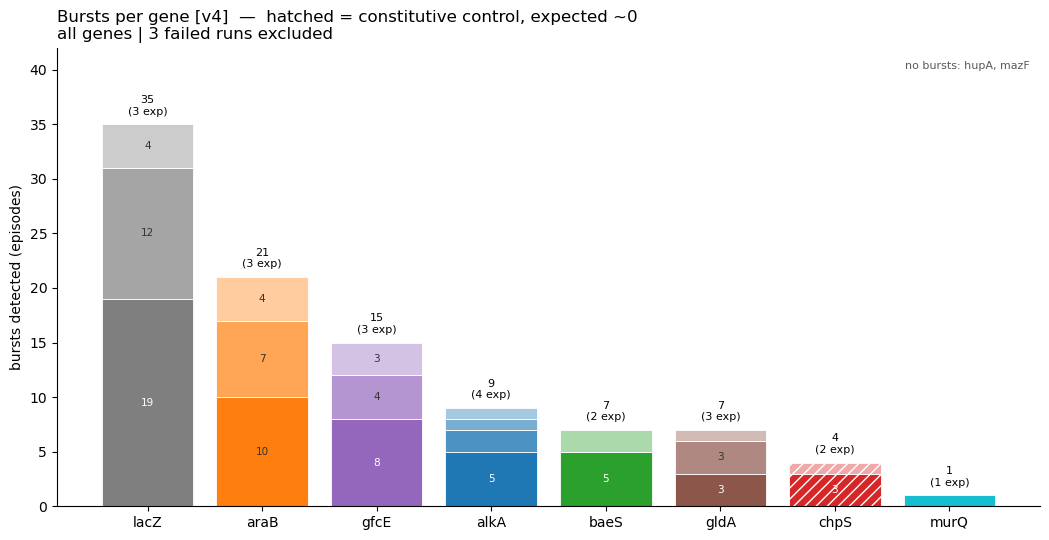

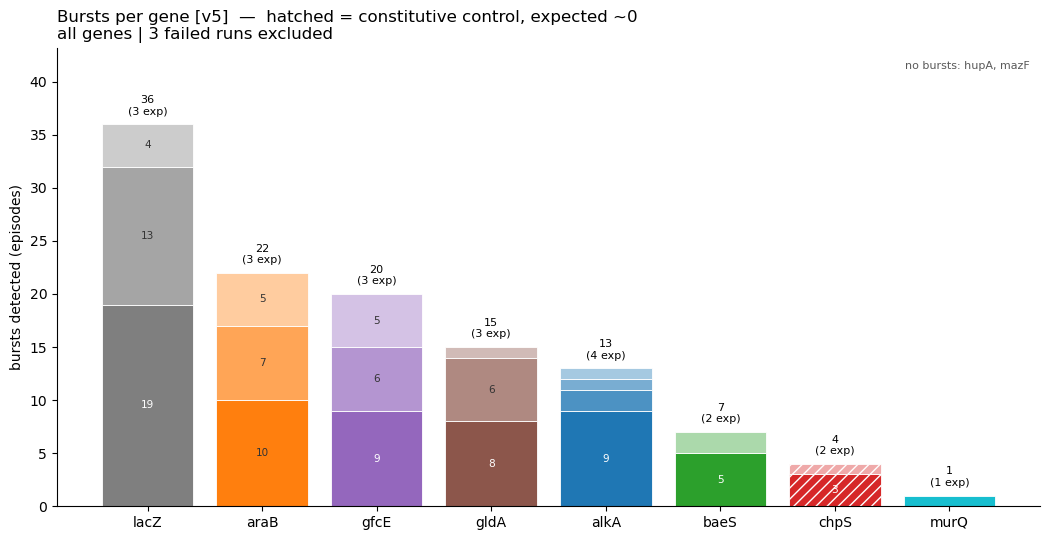

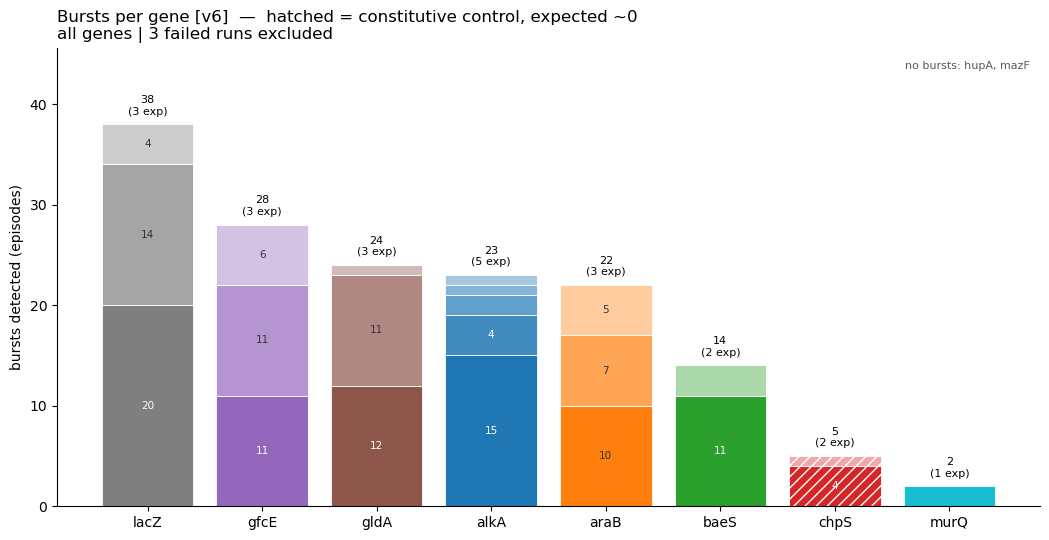

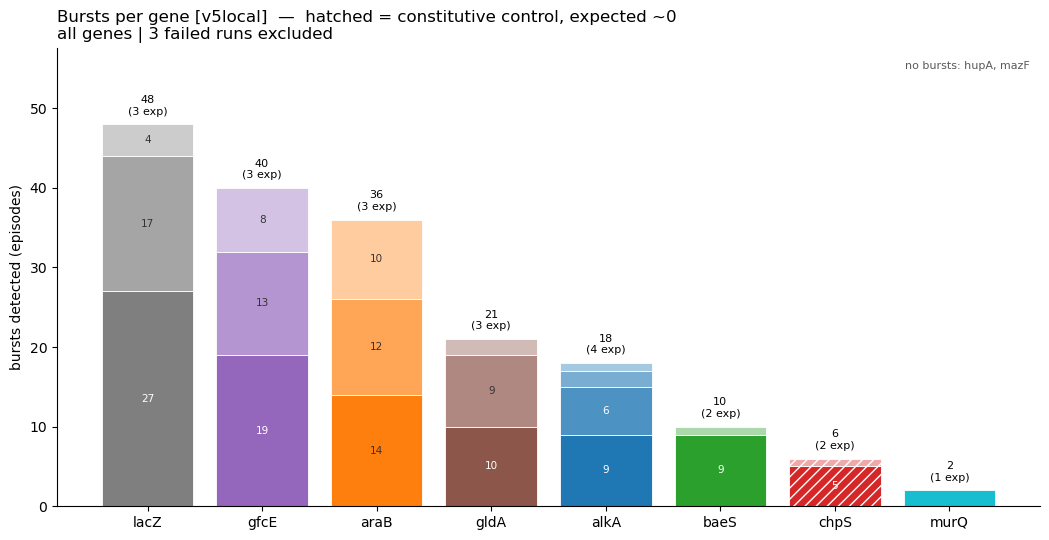

In [35]:
# Which definitions section 10 shows. DEF_ORDER is the export's column order; PLOT_DEFS
# drops v3, because v5 contains v4 contains v3 on all but one event and the panel would be a
# near-duplicate. v6 adds the left-base fold route -- section 11.
DEF_ORDER = ('v3', 'v4', 'v5', 'v6', 'v5local')
PLOT_DEFS = ('v4', 'v5', 'v6', 'v5local')

# The union export from 8k, and the divisions loaded in section 3.
print(f'union export: {len(burst_csv_all)} rows | '
      + ' | '.join(f'{v}={int(burst_csv_all[f"burst_{v}"].sum())}'
                   for v in DEF_ORDER))
print(f'divisions: {len(divisions):,} events '
      f'({int((~divisions.has_jump).sum()):,} with no jump in the parent\'s lifetime)')

for _v in PLOT_DEFS:
    F.plot_burst_counts(burst_csv_all, version=_v)


bursts per cell cycle [v4]

       n_bursts  n_divisions  per_cell_cycle   ci_lo   ci_hi  constitutive def_version denom_kind
gene                                                                                             
lacZ         35          688          0.0509  0.0354  0.0708         False          v4  divisions
gfcE         15          701          0.0214  0.0120  0.0353         False          v4  divisions
araB         21         1033          0.0203  0.0126  0.0311         False          v4  divisions
gldA          7          344          0.0203  0.0082  0.0419         False          v4  divisions
alkA          9          467          0.0193  0.0088  0.0366         False          v4  divisions
chpS          4          356          0.0112  0.0031  0.0288          True          v4  divisions
murQ          1          108          0.0093  0.0002  0.0516         False          v4  divisions
baeS          7         1255          0.0056  0.0022  0.0115         False          v4  d


bursts per cell cycle [v5]

       n_bursts  n_divisions  per_cell_cycle   ci_lo   ci_hi  constitutive def_version denom_kind
gene                                                                                             
lacZ         36          688          0.0523  0.0366  0.0724         False          v5  divisions
gldA         15          344          0.0436  0.0244  0.0719         False          v5  divisions
gfcE         20          701          0.0285  0.0174  0.0441         False          v5  divisions
alkA         13          467          0.0278  0.0148  0.0476         False          v5  divisions
araB         22         1033          0.0213  0.0133  0.0322         False          v5  divisions
chpS          4          356          0.0112  0.0031  0.0288          True          v5  divisions
murQ          1          108          0.0093  0.0002  0.0516         False          v5  divisions
baeS          7         1255          0.0056  0.0022  0.0115         False          v5  d


bursts per cell cycle [v5local]

       n_bursts  n_divisions  per_cell_cycle   ci_lo   ci_hi  constitutive def_version denom_kind
gene                                                                                             
lacZ         48          688          0.0698  0.0514  0.0925         False     v5local  divisions
gldA         21          344          0.0610  0.0378  0.0933         False     v5local  divisions
gfcE         40          701          0.0571  0.0408  0.0777         False     v5local  divisions
alkA         18          467          0.0385  0.0228  0.0609         False     v5local  divisions
araB         36         1033          0.0348  0.0244  0.0482         False     v5local  divisions
murQ          2          108          0.0185  0.0022  0.0669         False     v5local  divisions
chpS          6          356          0.0169  0.0062  0.0367          True     v5local  divisions
baeS         10         1255          0.0080  0.0038  0.0147         False     v5loc


bursts per cell cycle [v12] -- 1,091 events from bursts_v12_091026.csv

       n_bursts  n_divisions  per_cell_cycle   ci_lo   ci_hi  constitutive def_version denom_kind
gene                                                                                             
murQ         36          108          0.3333  0.2335  0.4615         False         v12  divisions
gldA         99          344          0.2878  0.2339  0.3504         False         v12  divisions
hupA         25           88          0.2841  0.1838  0.4194          True         v12  divisions
gfcE        186          701          0.2653  0.2286  0.3063         False         v12  divisions
chpS         94          356          0.2640  0.2134  0.3231          True         v12  divisions
mazF         57          239          0.2385  0.1806  0.3090          True         v12  divisions
alkA        100          467          0.2141  0.1742  0.2604         False         v12  divisions
baeS        267         1255          0.2127 


per cell cycle, every definition:

          v4      v5      v6  v5local     v12  divisions
gene                                                    
gldA  0.0203  0.0436  0.0698   0.0610  0.2878        344
lacZ  0.0509  0.0523  0.0552   0.0698  0.1424        688
alkA  0.0193  0.0278  0.0493   0.0385  0.2141        467
gfcE  0.0214  0.0285  0.0399   0.0571  0.2653        701
araB  0.0203  0.0213  0.0213   0.0348  0.1249       1033
murQ  0.0093  0.0093  0.0185   0.0185  0.3333        108
chpS  0.0112  0.0112  0.0140   0.0169  0.2640        356
baeS  0.0056  0.0056  0.0112   0.0080  0.2127       1255
hupA  0.0000  0.0000  0.0000   0.0000  0.2841         88
mazF  0.0000  0.0000  0.0000   0.0000  0.2385        239

hupA and mazF are at zero bursts under all 4 RULE definitions.
  v12: hupA 25, mazF 57, chpS 94 events -- reported, not asserted. See section 12.


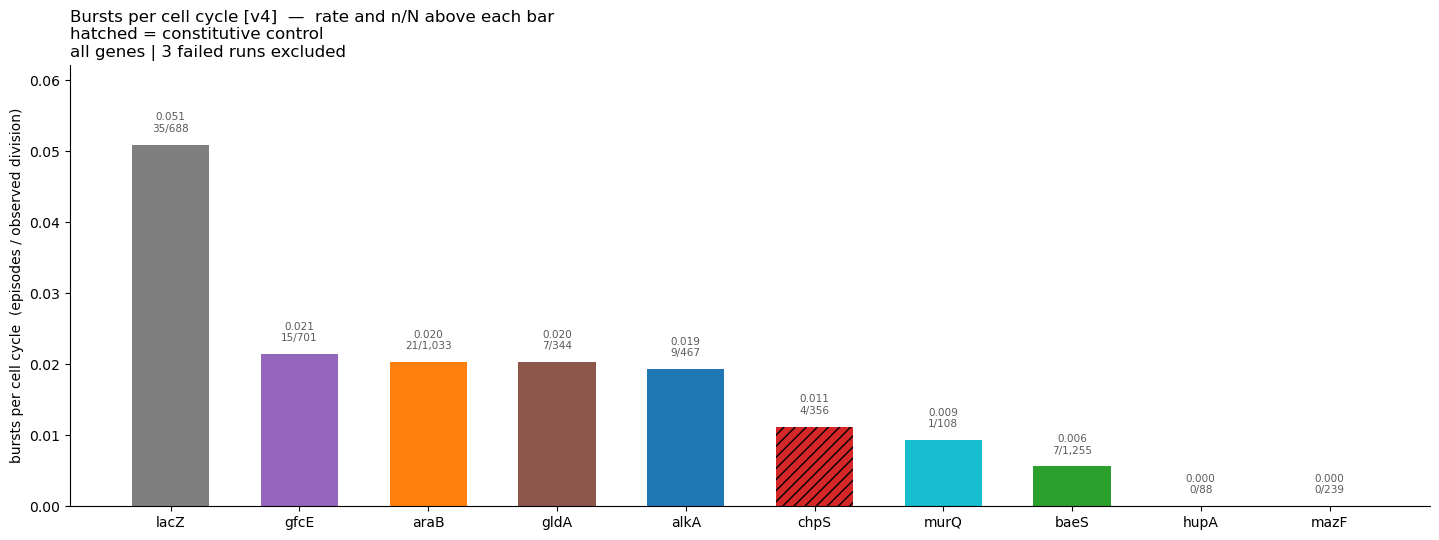

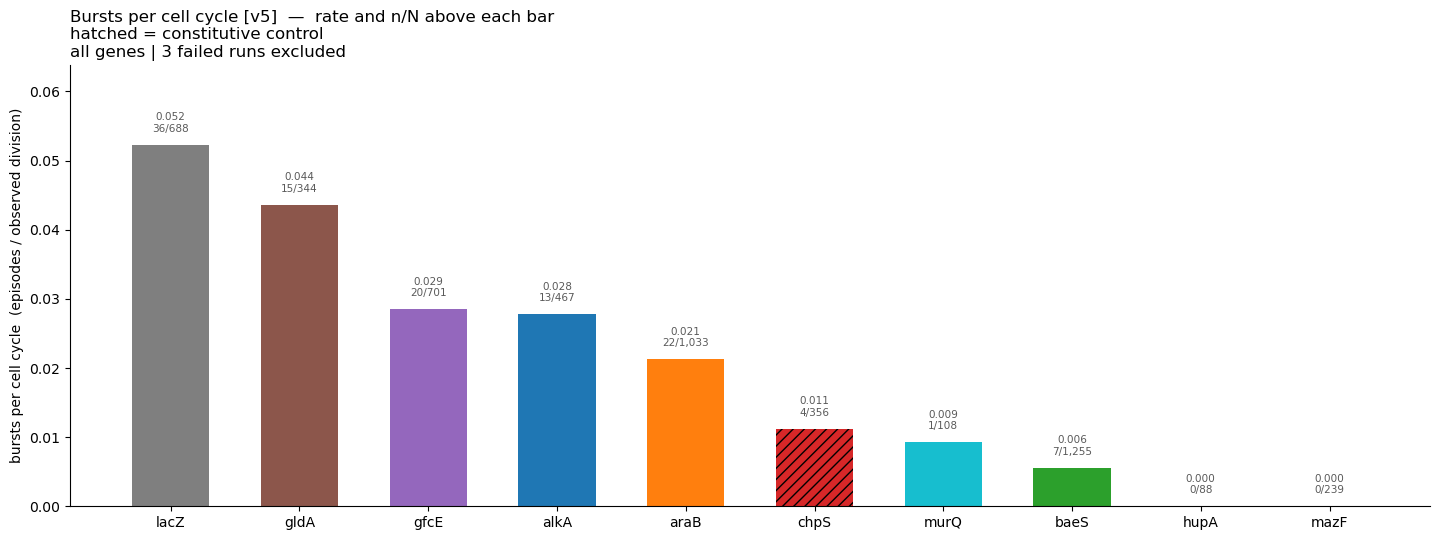

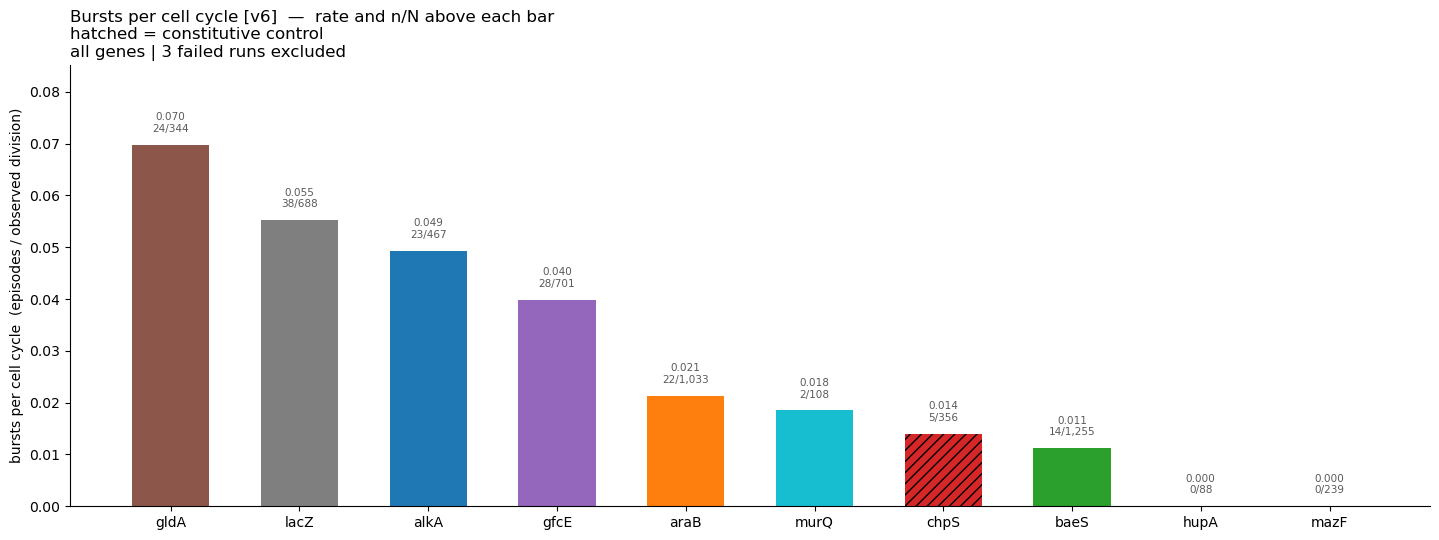

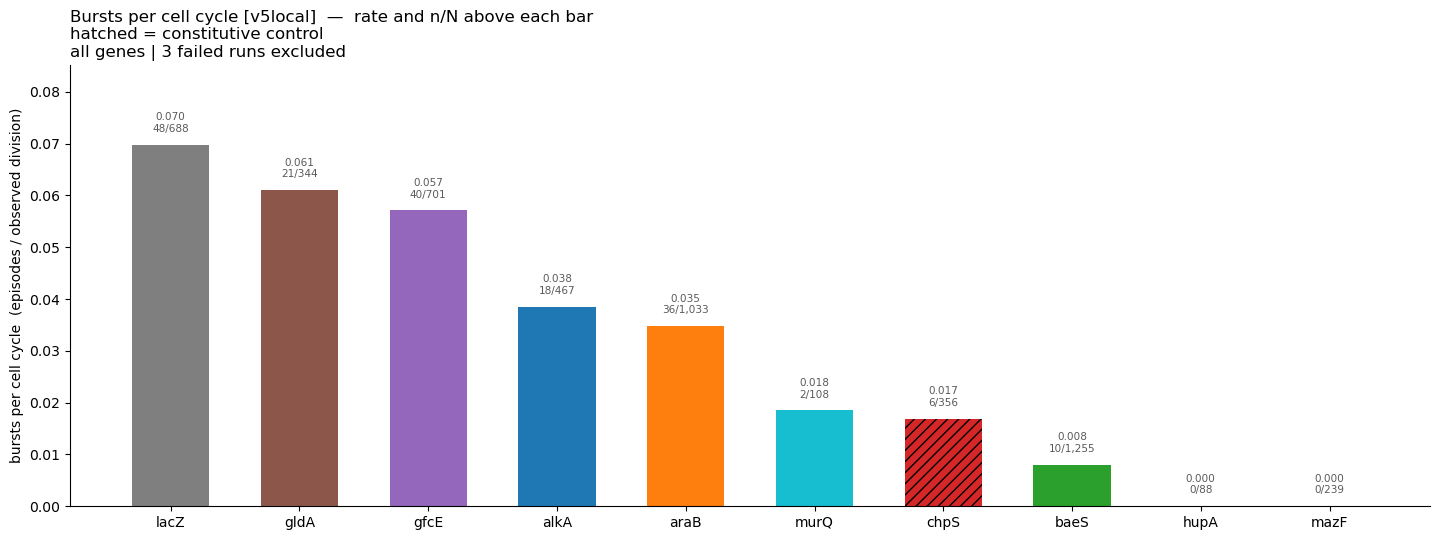

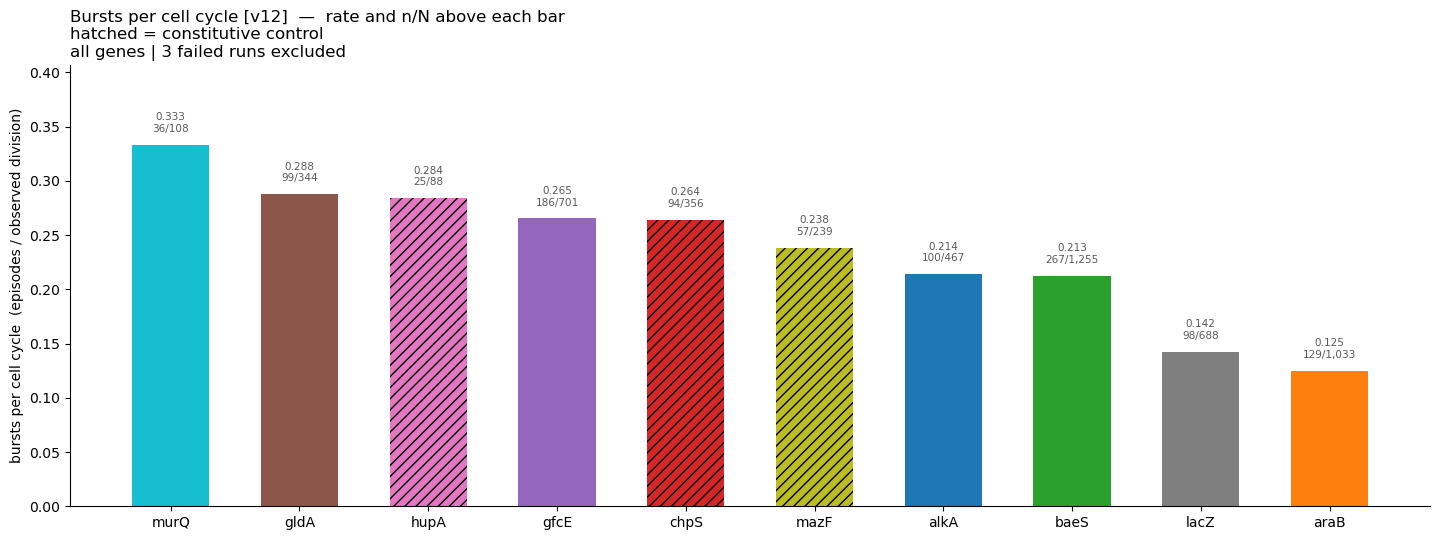

In [36]:
_rates = {}
for _v in PLOT_DEFS:
    _rates[_v] = F.bursts_per_cell_cycle(burst_csv_all, divisions, version=_v)
    print(f'\nbursts per cell cycle [{_v}]\n')
    print(_rates[_v].to_string())
    F.plot_bursts_per_cell_cycle(burst_csv_all, divisions, version=_v)

# The classifier on the SAME denominator, read from its own EVENT table. That table carries
# no burst_<v> column, so the boolean is synthesised here.
#
# Drawn as separate figures, never on a shared bar axis with v4-v7: those measure fluor_per_ms
# on the raw image and these measure the FIJI-transformed one, neither is a nested superset of
# anything, and the two families differ ~5x in magnitude anyway (v6 tops out at 0.070, v12 at
# 0.333). bursts.md section 14. suffix='_sec10' so this does not overwrite the copy
# section 12 saves under the same figure name.
_CLF_CSV = {'v12': 'data/bursts_v12_091026.csv'}            # 1,091 events at the 0.75 cutoff
for _v, _path in _CLF_CSV.items():
    _ev = pd.read_csv(f'{REPO_ROOT}/{_path}', dtype=F.READ_DTYPES)
    _ev[f'burst_{_v}'] = True
    _rates[_v] = F.bursts_per_cell_cycle(_ev, divisions, version=_v)
    print(f'\nbursts per cell cycle [{_v}] -- {len(_ev):,} events from '
          f'{os.path.basename(_path)}\n')
    print(_rates[_v].to_string())
    F.plot_bursts_per_cell_cycle(_ev, divisions, version=_v, suffix='_sec10')

_ALL_DEFS = tuple(PLOT_DEFS) + tuple(_CLF_CSV)

# Every column below is a ratio over the same denominator, which is the only reason they can
# sit in one table. Assert it rather than trust it: an event table scoped to a different set
# of experiments would silently rescale every rate in its column. sort_index() first -- each
# table comes back sorted by its own rate, so a bare .equals() fails on row order alone.
_denom = _rates[PLOT_DEFS[0]]['n_divisions'].sort_index()
for _v in _ALL_DEFS:
    assert _rates[_v]['n_divisions'].sort_index().equals(_denom), \
        f'{_v}: different denominator -- its column is not comparable to the others'

# Side by side, which is the only way the ranking shift is actually readable.
_side = pd.DataFrame({_v: _rates[_v]['per_cell_cycle'] for _v in _ALL_DEFS})
_side['divisions'] = _rates[PLOT_DEFS[0]]['n_divisions']
print('\nper cell cycle, every definition:\n')
print(_side.drop(index='TOTAL').sort_values('v6', ascending=False).round(4).to_string())

# The control has to hold under every RULE, not just the shipped one. v12 sits outside this
# loop deliberately: it never saw a control gene (bursts.md section 14), so its counts are
# REPORTED, not asserted.
for _v in PLOT_DEFS:
    assert _rates[_v].loc[['hupA', 'mazF'], 'n_bursts'].eq(0).all(), \
        f'{_v}: a hard constitutive control fired'
print(f'\nhupA and mazF are at zero bursts under all {len(PLOT_DEFS)} RULE definitions.')
for _v in _CLF_CSV:
    _ctl = ', '.join(f'{_g} {int(_rates[_v].loc[_g, "n_bursts"])}'
                     for _g in ('hupA', 'mazF', 'chpS'))
    print(f'  {_v}: {_ctl} events -- reported, not asserted. See section 12.')

### What the definitions do to the ranking

| gene | v4 | v5 | **v6** | v5local | v12 † | divisions |
|---|---|---|---|---|---|---|
| gldA | 0.020 | 0.044 | **0.070** | 0.061 | 0.288 | 344 |
| lacZ | 0.051 | 0.052 | **0.055** | 0.070 | 0.142 | 688 |
| alkA | 0.019 | 0.028 | **0.049** | 0.039 | 0.214 | 467 |
| gfcE | 0.021 | 0.029 | **0.040** | 0.057 | 0.265 | 701 |
| araB | 0.020 | 0.021 | **0.021** | 0.035 | 0.125 | 1,033 |
| murQ | 0.009 | 0.009 | **0.019** | 0.019 | 0.333 | 108 |
| chpS \* | 0.011 | 0.011 | **0.014** | 0.017 | 0.264 | 356 |
| baeS | 0.006 | 0.006 | **0.011** | 0.008 | 0.213 | 1,255 |
| hupA \* | 0.000 | 0.000 | **0.000** | 0.000 | 0.284 | 88 |
| mazF \* | 0.000 | 0.000 | **0.000** | 0.000 | 0.239 | 239 |

\* constitutive control. Rows sorted by v6.
† classifier, not a rule. Same denominator, so the column is a valid ratio, but it is **not**
a superset of the columns to its left and the magnitudes are not on the same scale — read
each family against itself.

**baeS/hupA/mazF stay at the bottom under all four rules**, and hupA/mazF stay at exactly zero
— the acceptance test holds through every *rule* change, which is the one result that never
moved.

**The classifier column is where it stops.** Under v12 hupA is 3rd of ten, so the rate no
longer sorts induced from constitutive. That is not a regression: v12 was never shown a
control gene (`bursts.md` §14), so its behaviour on hupA/mazF/chpS is untrained rather than
measured. It does mean **this rate cannot be quoted as evidence of induction under v12** —
section 12 says so at length.

**But "lacZ is top" does not survive v6.** gldA takes first place (0.070 vs 0.055), having
started 4th under v4 at 0.020. That is a 3.5× move on one gene from two changes to the same
ratio criterion, and it is not a coincidence: gldA has the *lowest* trench eligibility of any
gene (32%, section 8f), so it is the gene with most to gain each time a route stops requiring
an absolute bar to be cleared. alkA (52% eligible) moves the same way for the same reason.

**Whether that is a correction or an over-correction is still open, and the CIs do not settle
it.** gldA's v6 interval is 0.045–0.104 and lacZ's is 0.039–0.076 — they overlap, so the new
top-two ordering is not resolved by this data. What *is* resolved is that the v4-era ordering
was partly an artefact of coverage rather than of biology.

**v6 and v5local disagree in an informative direction.** They are not nested (113 shared, 43
v6-only, 68 v5local-only), and they move different genes: v5local favours lacZ and gfcE, v6
favours gldA and alkA. Since v6 is gene-scoped it also independently recovers 9 of the 77
events that used to be v5local's alone — so those 9 were never evidence for re-scoping the
baseline, just evidence that the max-base ratio was too strict.

On this denominator the whole field spans about 0.011–0.070 bursts per cell cycle under v6,
i.e. **a burst is seen in roughly 1 generation in 14 for gldA and 1 in 90 for baeS**. Still
rare events, and still the reason the Poisson intervals are wide.


---
# 11 — v6: anchoring the fold ratio on the left base

Section 8i's `fold` route divides a peak by $\max(b_{\text{left}}, b_{\text{right}})$. That
`max` binds on the **right** base whenever a burst's decay does not return to its pre-burst
floor — which is the normal case here, because the decay is dilution by growth, not protein
loss (§1 of `bursts.md`). So the max-base rule **systematically penalises exactly the
long-decay events**.

The case that forced this: gfcE `DUMM_giTG060_064_121425` FOV 013 trench 153, viewer frame
~32. It fails all three v5 gates and is in **no** event table — not v5, not v5local.

$$\text{v6 fold-left route:}\qquad
\frac{\mathcal{E}(t^\ast)}{\max\!\left(b_{\text{left}},\; f\cdot m\right)} \ge R_L
\qquad\text{and}\qquad
\mathcal{E}(t^\ast) \ge m + 1.0\,s
\qquad (R_L = 3.6,\; f = 0.5)$$

**This is not the left-base variant §4 of `bursts.md` rejects.** That measurement was on
*absolute* prominence in MAD units, where left-only **inverted** the control (hupA's best
wobble 6.855 vs a real chpS burst 6.061). As a unit-free **ratio** it does not invert. That
distinction is the entire justification for the route; keep the two measurements apart.

### 11a — The per-frame kymograph baseline: evaluated, not shipped

Before v6 was designed, the proposal on the table was different: take each kymograph's
**average fluorescence per time frame**, and score each cell against the average of its own
frame and the neighbouring frames.

$$B(t) = \frac{1}{2w+1}\sum_{t'=t-w}^{t+w} L(t'),
\qquad L(t) = \operatorname{mean}_{c \text{ at } t} F_c(t),
\qquad \text{score} = \frac{F_c(t)}{B(t)}$$

It is a good idea — unit-free, per-trench, and immune to slow drift. **Measured, it cannot
separate the target event from the constitutive controls**, and the cell below is the record
of that. Two things it establishes, both worth knowing before anyone tries it again.

In [37]:
# 11a -- the per-frame baseline statistic, measured. This is a NEGATIVE result kept on the
# record (the section-8j / v5local pattern); it is NOT the definition v6 uses.
import numpy as np

_W_SWEEP = (3, 5, 8, 12)
_M_SWEEP = (3, 5, 7)          # frames of smoothing ALONG a track, to demand coherence


def _window_sums(X, w):
    """Row-wise sums over a centred +/- w window, edge-truncated. X is (rows, n_frames)."""
    _c = np.concatenate([np.zeros((X.shape[0], 1)), np.cumsum(X, axis=1)], axis=1)
    _n = X.shape[1]
    _hi = np.minimum(np.arange(_n) + w + 1, _n)
    _lo = np.maximum(np.arange(_n) - w, 0)
    return _c[:, _hi] - _c[:, _lo]


def _perframe_scores(df, w=5):
    """Cell vs its kymograph's per-frame level, averaged over +/- w frames.

    Three denominators: the frame level with the cell included, the frame level with the
    cell's whole TRACK removed, and the trench's quiet level (20th pct of frame medians).

    Vectorised per trench rather than per cell, using the identity that a track's
    leave-one-out level is the frame level plus a correction supported only on that track's
    own lifetime: L_c(t) = L(t) + delta_c(t), delta_c = (S-F_c)/(n-1) - S/n where present and
    0 elsewhere. A frame where the track is the ONLY cell has no leave-one-out level at all,
    so it is dropped from that track's window (numerator and denominator both).
    """
    _out = []
    for _k, _g in df.groupby(F.KYMO_KEY, sort=False):
        _g = _g.sort_values(['time_frame', 'track_id']).copy()
        _f0, _f1 = int(_g.time_frame.min()), int(_g.time_frame.max())
        _nf = _f1 - _f0 + 1
        _pos = _g.time_frame.to_numpy() - _f0
        _fv = _g[F.FLUOR_COL].to_numpy(dtype=float)

        _S = np.zeros(_nf); _N = np.zeros(_nf)
        np.add.at(_S, _pos, _fv)
        np.add.at(_N, _pos, 1.0)
        _has = _N > 0
        _L = np.where(_has, _S / np.maximum(_N, 1), 0.0)

        # inclusive baseline
        _num = _window_sums((_L * _has)[None, :], w)[0]
        _den = _window_sums(_has.astype(float)[None, :], w)[0]
        _g['B_incl'] = np.where(_den > 0, _num / np.maximum(_den, 1), np.nan)[_pos]

        # leave-one-track-out baseline
        _tracks, _ti = np.unique(_g.track_id.to_numpy(), return_inverse=True)
        _D = np.zeros((len(_tracks), _nf))       # the delta correction
        _P = np.zeros((len(_tracks), _nf))       # 1 where this track has a cell
        _alone = _N[_pos] <= 1
        _d = np.where(_alone, 0.0,
                      (_S[_pos] - _fv) / np.maximum(_N[_pos] - 1, 1) - _L[_pos])
        _D[_ti, _pos] = _d
        _P[_ti, _pos] = 1.0
        _bad = np.zeros((len(_tracks), _nf))     # frames unusable for this track
        _bad[_ti[_alone], _pos[_alone]] = 1.0
        _V = _has[None, :] * (1.0 - _bad)
        _Lc = (_L[None, :] + _D) * _V
        _numc = _window_sums(_Lc, w)
        _denc = _window_sums(_V, w)
        _Bl = np.where(_denc > 0, _numc / np.maximum(_denc, 1e-12), np.nan)
        _g['B_loo'] = _Bl[_ti, _pos]

        _med = np.where(_has, 0.0, np.nan)
        _mv = _g.groupby('time_frame')[F.FLUOR_COL].median()
        _med[_mv.index.to_numpy() - _f0] = _mv.to_numpy()
        _g['B_quiet'] = np.nanpercentile(_med[_has], 20)
        _out.append(_g)

    _r = pd.concat(_out)
    for _c, _dn in (('S_incl', 'B_incl'), ('S_loo', 'B_loo'), ('S_quiet', 'B_quiet')):
        _r[_c] = _r[F.FLUOR_COL] / _r[_dn]
    return _r


CASE_V6 = ('DUMM_giTG060_064_121425', '013', '153')
FRAME_V6 = 31          # the peak; viewer frame 32 -- see 11b for the conversion
HARD = ['hupA', 'mazF', 'chpS']

_pf = _perframe_scores(clean, w=5)
_ev = _pf[(_pf.experiment_name == CASE_V6[0]) & (_pf.FOV == CASE_V6[1])
          & (_pf.trench_id == CASE_V6[2]) & (_pf.track_id == 2)
          & _pf.time_frame.between(FRAME_V6 - 2, FRAME_V6 + 2)]
_cols = ['S_incl', 'S_loo', 'S_quiet']
_tab = pd.DataFrame({
    'target': {_c: _ev[_c].max() for _c in _cols},
    'best_control': {_c: _pf[_pf.gene.isin(HARD)][_c].max() for _c in _cols},
    'hupA_max': {_c: _pf[_pf.gene == 'hupA'][_c].max() for _c in _cols},
})
_tab['margin'] = _tab.target / _tab.best_control
print('per-frame baseline, w=5 -- target event vs the constitutive controls')
print(_tab.round(3).to_string())
print('\nA margin < 1 means a bar that admits the target also fires on a control.')


per-frame baseline, w=5 -- target event vs the constitutive controls
         target  best_control  hupA_max  margin
S_incl    1.561         2.415     1.749   0.647
S_loo     1.846         2.662     1.915   0.694
S_quiet   2.895         3.564     2.881   0.812

A margin < 1 means a bar that admits the target also fires on a control.


In [38]:
# 11a (cont) -- is it a tuning problem? Sweep the temporal window, and smooth the ratio
# along each track to demand temporal coherence. If chpS's outliers were frame-to-frame
# noise, smoothing would suppress them and not the target.
_rows = []
for _w in _W_SWEEP:
    _s = _perframe_scores(clean, w=_w)
    _t = _s[(_s.experiment_name == CASE_V6[0]) & (_s.FOV == CASE_V6[1])
            & (_s.trench_id == CASE_V6[2]) & (_s.track_id == 2)
            & _s.time_frame.between(FRAME_V6 - 2, FRAME_V6 + 2)]
    _c = _s[_s.gene.isin(HARD)]
    _rec = {'w': _w, 'target': _t.S_loo.max(), 'control': _c.S_loo.max()}
    for _m in _M_SWEEP:
        _sm = (_s.sort_values('time_frame').groupby(F.KYMO_KEY + ['track_id'])['S_loo']
                 .transform(lambda s: s.rolling(_m, center=True, min_periods=_m).mean()))
        _s2 = _s.assign(_sm=_sm)
        _rec[f'tgt_m{_m}'] = _s2.loc[_t.index, '_sm'].max()
        _rec[f'ctl_m{_m}'] = _s2[_s2.gene.isin(HARD)]['_sm'].max()
    _rows.append(_rec)
_sw = pd.DataFrame(_rows).set_index('w')
for _m in ('',) + tuple(f'_m{_m}' for _m in _M_SWEEP):
    _a, _b = (('target', 'control') if not _m else (f'tgt{_m}', f'ctl{_m}'))
    _sw[f'margin{_m}'] = _sw[_a] / _sw[_b]
print('window and along-track-smoothing sweep (leave-one-track-out denominator)')
print(_sw[[c for c in _sw.columns if c.startswith('margin')]].round(3).to_string())

# The census that explains WHY: the denominator has almost no cells in it.
_n = clean.groupby(F.KYMO_KEY + ['time_frame']).size()
print(f'\ncells per trench-frame: median {int(_n.median())}, '
      f'<=2 in {(_n <= 2).mean():.1%} of trench-frames, <=3 in {(_n <= 3).mean():.1%}')
print(f'the target trench holds 2 cells at frame {FRAME_V6}')

assert _tab.loc['S_loo', 'margin'] < 1.0, (
    'the per-frame baseline now separates the target from the controls -- section 11a says '
    'it cannot, and v6 exists because of that. Re-read 11a before changing it.')


window and along-track-smoothing sweep (leave-one-track-out denominator)
    margin  margin_m3  margin_m5  margin_m7
w                                          
3    0.683      0.692      0.637      0.639
5    0.694      0.691      0.691      0.682
8    0.652      0.637      0.661      0.659
12   0.603      0.601      0.628      0.621

cells per trench-frame: median 5, <=2 in 25.5% of trench-frames, <=3 in 34.3%
the target trench holds 2 cells at frame 31


**Verdict: not shippable, and not a tuning problem.** The target scores ~0.65–0.81× the
best constitutive score under every denominator, every window $w \in \{3,5,8,12\}$ and every
along-track smoothing $m \in \{3,5,7\}$. Under the two frame-based denominators it lands
*below hupA's own maximum*.

Two reasons, both structural:

1. **The denominator is nearly empty.** The median trench-frame holds 5 cells, but **25.4%
   hold ≤ 2** and 34.3% hold ≤ 3. The target trench holds exactly 2 during the event, so the
   frame average is half the bursting cell — or, leaving it out, is one neighbour.
2. **Smoothing does not discriminate**, because chpS's high-contrast cells are *also*
   temporally coherent. The margin barely moves. Local contrast simply is not the axis that
   separates a burst from constitutive cell-to-cell scatter.

**One trap, recorded so nobody loses an afternoon to it.** A "leave-one-out" baseline built
per *frame* is not a change at all: with a mean aggregator, the mean over cells of their
leave-one-out means is *identically* the frame mean,
$\frac{1}{n}\sum_c \frac{S - F_c}{n-1} = \frac{S}{n}$. Only removing the whole **track**
(as `_perframe_scores` does) is a real leave-one-out.

### 11b — Why 013/153 is missed: the binding side is the right base

Viewer frame → `time_frame` first, always. Trench 153 has `start: 1`, so the two numbers
differ by one and reading the raw axis label would look up the wrong frame.

viewer frame 32 -> time_frame 31  (start=1)



the target peak, and the rest of its trench:
 time_frame  track_id  fluor  height_s  prom_s  fold  fold_left  left_base  right_base binding_side  is_local_max     route     verdict
         31         2  0.105     3.279   2.927 2.015      3.787      0.028       0.052        right          True fold_left       burst
         39         6  0.103     3.162   1.980 1.533      1.533      0.067       0.052         left          True           height+fold
         60        33  0.095     2.763   1.750 1.494      1.836      0.052       0.064        right          True           height+fold
         47        14  0.088     2.335   1.086 1.287      1.287      0.068       0.052         left          True           height+fold



gfcE/DUMM_giTG060_064_121425: median 0.04566 scale 0.01803 -> height bar 0.11778
trench 153 whole-trace max                       0.10478
v5local bar for this trench                      0.11090
-> unreachable by BOTH the gene bar and the per-trench bar, so no absolute candidate ever existed and prominence was never evaluated.



v3 prominence rejections: 84, binding side {'right': 53, 'left': 31}


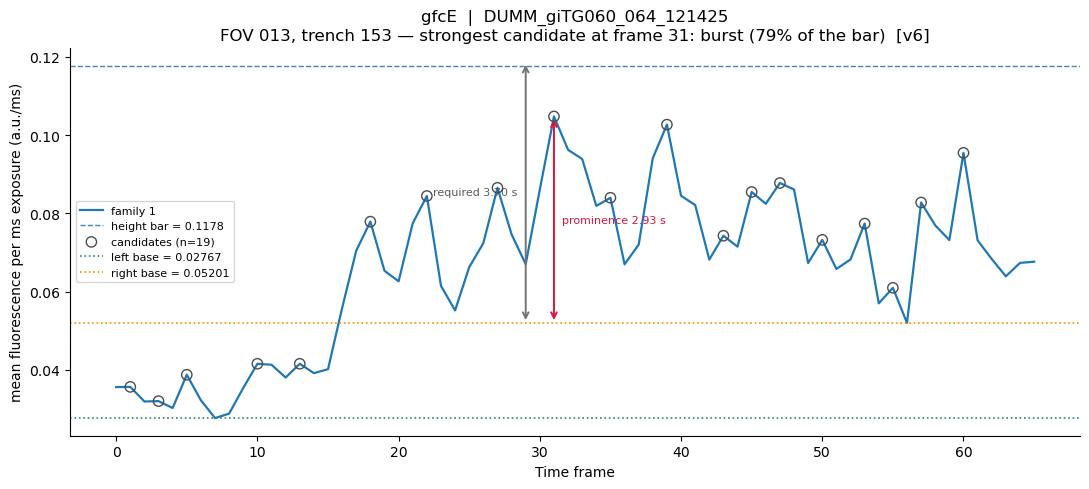

In [39]:
# 11b -- the audit row for the target peak. `binding_side` is the whole story.
_vf = 32
_start = F.trench_start_frame(*CASE_V6, data_root=REPO_ROOT)
print(f'viewer frame {_vf} -> time_frame '
      f'{F.viewer_frame_to_time_frame(*CASE_V6, _vf, data_root=REPO_ROOT)}'
      f'  (start={_start})')

_cand6 = Bu.burst_candidates(clean, Bu.BURST_DEF_V6)
_t153 = _cand6[(_cand6.experiment_name == CASE_V6[0]) & (_cand6.FOV == CASE_V6[1])
               & (_cand6.trench_id == CASE_V6[2])]
_show = ['time_frame', 'track_id', 'fluor', 'height_s', 'prom_s', 'fold', 'fold_left',
         'left_base', 'right_base', 'binding_side', 'is_local_max', 'route', 'verdict']
print('\nthe target peak, and the rest of its trench:')
print(_t153.sort_values('fluor', ascending=False).head(4)[_show].round(3).to_string(index=False))

# Why no absolute route was ever available: the whole trench sits under its gene's bar.
_bl = F.compute_baselines(clean)
_m, _s = _bl.loc[('gfcE', CASE_V6[0]), ['median', 'mad_scale']]
_tr = F.select_trench(clean, *CASE_V6)
_lo = Bu.attach_kymograph_baselines(clean, scope='kymograph', scale_floor_frac=0.25)
_lt = F.select_trench(_lo, *CASE_V6)
print(f'\ngfcE/{CASE_V6[0]}: median {_m:.5f} scale {_s:.5f} -> height bar {_m + 4 * _s:.5f}')
print(f'trench 153 whole-trace max                       {_tr[F.FLUOR_COL].max():.5f}')
print(f'v5local bar for this trench                      '
      f'{_lt._base_med.iloc[0] + 4 * _lt._base_scale.iloc[0]:.5f}')
print('-> unreachable by BOTH the gene bar and the per-trench bar, so no absolute candidate '
      'ever existed and prominence was never evaluated.')

# The right base binding is not peculiar to this trench. Among the peaks that v3 rejected
# on PROMINENCE -- height-clearing local maxima, so the comparison is apples to apples --
# the right base is the deciding one in 53 of 84, for exactly this reason: an envelope that
# has not returned to baseline by the end of the recording has its right base set by a
# plateau. v6 is aimed at the dominant rejection mode, not at one event.
#
# Do NOT read this off v6's own candidate set: that has no height gate, so it is dominated
# by low wobbles where the two sides are near-symmetric (939 right / 808 left) and the
# asymmetry that matters is washed out.
_pr = Bu.burst_candidates(clean, Bu.BURST_DEF_V3)
_pr = _pr[_pr.verdict.eq('prominence')]
print(f'\nv3 prominence rejections: {len(_pr)}, binding side '
      f'{_pr.binding_side.value_counts().to_dict()}')

F.plot_prominence_bases(clean, *CASE_V6, bdef=Bu.BURST_DEF_V6);


### 11c — Calibrating the left-base route

Two knobs, and the floor is the one that makes it safe: an unfloored ratio divides by a
near-zero left base and manufactures an arbitrary fold (chpS 010/46 has `left_base` 0.006 and
scores 30×). Flooring the denominator at $f\cdot m$ kills that without touching the target,
whose left base sits well above the floor.

In [40]:
# 11c -- the two sweeps that set f = 0.5 and R_L = 3.6. Candidate-level (burst_candidates
# reproduces neither merge), so these are UPPER BOUNDS on event counts, not event counts.
_lm = _cand6[_cand6.is_local_max].copy()
_lm = _lm.merge(_bl.reset_index(), on=['gene', 'experiment_name'], how='left')
_TGT = ((_lm.experiment_name == CASE_V6[0]) & (_lm.FOV == CASE_V6[1])
        & (_lm.trench_id == CASE_V6[2]) & (_lm.time_frame == FRAME_V6))

print('denominator floor sweep (bar held at 3.6):')
_rows = []
for _f in (0.0, 0.25, 0.5, 0.75):
    _fl = _lm.fluor / np.maximum(_lm.left_base, _f * _lm['median'])
    _rows.append({'floor_frac': _f,
                  'hupA_mazF_max': _fl[_lm.gene.isin(['hupA', 'mazF'])].max(),
                  'chpS_max': _fl[_lm.gene == 'chpS'].max(),
                  'target': _fl[_TGT].iloc[0]})
print(pd.DataFrame(_rows).set_index('floor_frac').round(3).to_string())

print('\nbar sweep at floor 0.5 (local maxima over the height floor):')
_fl = _lm.fluor / np.maximum(_lm.left_base, 0.5 * _lm['median'])
_ok = _lm.height_s >= Bu.BURST_DEF_V6['fold_height_floor_s']
_rows = []
for _R in (3.0, 3.3, 3.4, 3.6, 3.8, 4.0):
    _h = _lm[(_fl >= _R) & _ok]
    _rows.append({'R_L': _R, 'candidates': len(_h),
                  'hupA': int((_h.gene == 'hupA').sum()),
                  'mazF': int((_h.gene == 'mazF').sum()),
                  'chpS': int((_h.gene == 'chpS').sum()),
                  'target_caught': bool(((_fl >= _R) & _ok & _TGT).any())})
print(pd.DataFrame(_rows).set_index('R_L').to_string())
print(f"\nhupA best fold_left {_fl[_lm.gene == 'hupA'].max():.3f} | "
      f"target {_fl[_TGT].iloc[0]:.3f}  -> safe band [3.4, 3.79], 3.6 mid-plateau")


denominator floor sweep (bar held at 3.6):
            hupA_mazF_max  chpS_max  target
floor_frac                                 
0.00               14.024    30.038   3.787
0.25                4.316     6.115   3.787
0.50                3.372     4.218   3.787
0.75                2.438     3.650   3.059

bar sweep at floor 0.5 (local maxima over the height floor):
     candidates  hupA  mazF  chpS  target_caught
R_L                                             
3.0         231     1     0    12           True
3.3         165     1     0     4           True
3.4         153     0     0     2           True
3.6         130     0     0     1           True
3.8         109     0     0     1          False
4.0          87     0     0     1          False

hupA best fold_left 3.372 | target 3.787  -> safe band [3.4, 3.79], 3.6 mid-plateau


**The floor is bracketed on both sides**, which is what makes 0.5 a choice rather than a
knob: at $0.25\,m$ the controls are still loose (chpS 6.12), and at $0.75\,m$ the floor has
risen above the target's own left base and the event is lost (3.059). Only $0.5\,m$ does both
jobs.

**Safe band [3.4, 3.79].** hupA's best left-fold is 3.372, the target reaches 3.787;
hupA and mazF stay at zero candidates for every bar ≥ 3.4, so 3.6 is mid-plateau *on the
control side*. But **the upper edge is set by one event**, so the honest guard is ~5% either
way — narrower than v5's (3.10, 3.60]. Quote the band whenever the 3.6 is quoted.

Both prior anchors survive: alkA 001/1192 frame 9 (the case that motivated v5's fold route)
has `fold_left` 3.703, and chpS 010/1188 frame 25 sits at 3.563, *below* the new bar but
already admitted by the absolute route (`prom_s` 3.851 ≥ 3.7). Nothing is lost to reach the
target.

### 11d — v6 against v5, and the regression gate

In [41]:
# 11d -- v6 must ADD ONLY. v1-v5 bit-identical, v6 a strict superset of v5, controls at 0.
# Reuses the `burst_sets` built in 8c rather than re-detecting: since 8c now includes v6,
# re-running here would duplicate ~2 min of work and, worse, could silently diverge from the
# sets the export in 8k is actually built from.
_KEY = F.KYMO_KEY + ['track_id', 'time_frame']
_sets = {_v: _as_set(burst_sets[_v]) for _v in ('v1', 'v2', 'v3', 'v4', 'v5', 'v6')}
for _v, _b in ((_v, burst_sets[_v]) for _v in ('v1', 'v2', 'v3', 'v4', 'v5', 'v6')):
    print(f'{_v}: {len(_b):4d}  routes={_b.route.value_counts().to_dict()}')

assert {_v: len(_sets[_v]) for _v in ('v1', 'v2', 'v3', 'v4', 'v5')} == \
       {'v1': 73, 'v2': 89, 'v3': 89, 'v4': 99, 'v5': 118}, \
       'v6 changed an older definition -- the route was made non-additive, not additive'
assert _sets['v6'] >= _sets['v5'], 'v6 must be a strict superset of v5'
_v6 = burst_sets['v6']
assert _v6[_v6.gene.isin(['hupA', 'mazF'])].empty, \
       'v6: a hard constitutive control fired -- re-run the 11c bar sweep before shipping'
assert ((_v6.trench_id == '153') & (_v6.time_frame == FRAME_V6)
        & (_v6.route == 'fold_left')).any(), \
       'v6 lost gfcE 013/153, the case it exists for -- see 11b'
print(f"\nv6 adds {len(_sets['v6'] - _sets['v5'])} events to v5, loses 0")

_pg = pd.DataFrame({_v: burst_sets[_v].gene.value_counts() for _v in ('v4', 'v5', 'v6')}
                   ).fillna(0).astype(int)
_pg['v6_new'] = _pg.v6 - _pg.v5
print('\nper gene:'); print(_pg.sort_values('v6', ascending=False).to_string())


v1:   73  routes={'absolute': 73}
v2:   89  routes={'absolute': 89}
v3:   89  routes={'absolute': 89}
v4:   99  routes={'absolute': 99}
v5:  118  routes={'absolute': 99, 'fold': 19}
v6:  156  routes={'absolute': 99, 'fold_left': 38, 'fold': 19}

v6 adds 38 events to v5, loses 0

per gene:
      v4  v5  v6  v6_new
gene                    
lacZ  35  36  38       2
gfcE  15  20  28       8
gldA   7  15  24       9
alkA   9  13  23      10
araB  21  22  22       0
baeS   7   7  14       7
chpS   4   4   5       1
murQ   1   1   2       1



=== v5 ===
       n_bursts  n_divisions  per_cell_cycle   ci_lo   ci_hi  constitutive def_version denom_kind
gene                                                                                             
lacZ         36          688          0.0523  0.0366  0.0724         False          v5  divisions
gldA         15          344          0.0436  0.0244  0.0719         False          v5  divisions
gfcE         20          701          0.0285  0.0174  0.0441         False          v5  divisions
alkA         13          467          0.0278  0.0148  0.0476         False          v5  divisions
araB         22         1033          0.0213  0.0133  0.0322         False          v5  divisions
chpS          4          356          0.0112  0.0031  0.0288          True          v5  divisions
murQ          1          108          0.0093  0.0002  0.0516         False          v5  divisions
baeS          7         1255          0.0056  0.0022  0.0115         False          v5  divisions
hupA    

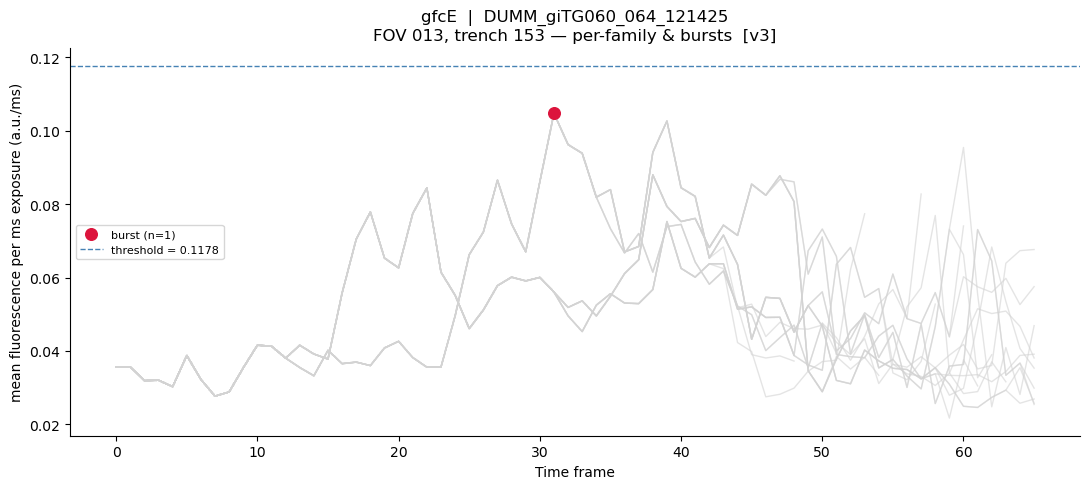

In [42]:
# 11d (cont) -- the headline rate, and the target drawn against its trench. Reads the union
# export built in 8k; section 10 plots the same table across every definition.
for _v in ('v5', 'v6'):
    print(f'\n=== {_v} ===')
    print(F.bursts_per_cell_cycle(burst_csv_all, divisions, version=_v).to_string())

_S = {_v: set(map(tuple, burst_csv_all[burst_csv_all[f'burst_{_v}']][_KEY].values.tolist()))
      for _v in ('v5', 'v6', 'v5local')}
print(f"\nv6 vs v5local: shared {len(_S['v6'] & _S['v5local'])}, "
      f"v6-only {len(_S['v6'] - _S['v5local'])}, v5local-only {len(_S['v5local'] - _S['v6'])}"
      '  -- two different re-scopings, not a nesting')

F.plot_bursts_for_trench(cells, F.select_definition(burst_csv_all, 'v6'), *CASE_V6);


**v6 = 99 absolute + 19 fold + 38 fold-left = 156**, a strict superset of v5, with hupA and
mazF still at zero and chpS at 5. The gains land where the mechanism predicts — the genes
whose trenches were least able to clear an absolute bar: alkA +10, gldA +9, gfcE +8, baeS +7,
lacZ +2, araB +0.

**One ranking change, and it needs saying.** §11 of `bursts.md` records "lacZ is top under
every definition". Under v6 it is not: **gldA 0.070 overtakes lacZ 0.055**, because gldA is
the gene most starved by the absolute bar (32% trench eligibility) and so gains most from a
second ratio route. Its interval (0.045–0.104) still overlaps lacZ's (0.039–0.076), so this
is not a resolved reordering — but the claim as previously written no longer holds.

**v6 and v5local are not nested**: 113 shared, 43 v6-only, 68 v5local-only. They re-scope
different things — v5local moves the *baseline*, v6 changes the *base of the ratio* — so the
overlap being partial is expected, and neither subsumes the other.

### Export: v3 / v4 / v5 / v5local / v6

In [43]:
# 11e -- the export is written by 8k, which is the single authoritative writer for this
# notebook (data/bursts_090426.csv). This cell only checks that what landed on disk carries
# v6 and agrees with what was detected here, so the file and the narrative cannot drift.
#
# bursts_082026.csv stays frozen as the regression fixture; bursts_090326.csv stays as the
# v5-era record. Neither is rewritten.
_disk = F.load_bursts(BURSTS_CSV_OUT, version=None)
print(f'{BURSTS_CSV_OUT}: {len(_disk)} rows | '
      + ' | '.join(f'{_v}={int(_disk[f"burst_{_v}"].sum())}' for _v in DEF_ORDER))
print('  by route:', _disk.route.value_counts().to_dict())

for _v in DEF_ORDER:
    _on_disk = set(map(tuple, _disk[_disk[f'burst_{_v}']][_KEY].values.tolist()))
    assert _on_disk == _as_set(burst_sets[_v]), f'{_v}: the export disagrees with detection'
assert ((_disk.trench_id == '153') & (_disk.time_frame == FRAME_V6)
        & _disk.burst_v6).any(), 'the export lost gfcE 013/153'
print(f'\nexport agrees with detection for all {len(DEF_ORDER)} definitions, '
      'and carries the gfcE 013/153 event')


/Users/adrianjuarez/Documents/Covert_lab/repos/mother_machine_cell_tracker/data/bursts_090426.csv: 225 rows | v3=89 | v4=99 | v5=118 | v6=156 | v5local=181
  by route: {'absolute': 164, 'fold_left': 38, 'fold': 23}

export agrees with detection for all 5 definitions, and carries the gfcE 013/153 event


---
# 12 — v12: bursts per cell cycle under the trained classifier

Section 10 compared the rule-based definitions on this axis. v12 is not a rule — it is a
gradient-boosted classifier fitted to **211 hand-identified lacZ/gfcE bursts** over 60
exhaustively reviewed trenches (`mmtrack/burst_training.py`, `bursts.md` §14). It is the first
definition here that was fitted to what a person actually called a burst, and against those
labels it dominates v11 outright: precision 0.607 at recall 0.739, versus v11's 0.592 at 0.429.

**Read the rate with the same two caveats section 10 carries** — the numerator counts episodes
and the denominator counts divisions, so a gene whose bursts are long relative to its cell cycle
scores lower at equal biology; and both terms are observation-limited.

**And one more that is specific to v12.** It is plotted on its own, not on a shared
`burst_rate_comparison` axis with v4–v7: those measure `fluor_per_ms` on the raw image, v12
measures the FIJI-transformed one *and* is a model rather than a nested rule, so it is neither
a superset nor a subset of anything. `bursts.md` §7 makes that prohibition explicit for v8–v11
and it applies here unchanged.

**The constitutive control fails, and the plot shows it.** hupA / mazF / chpS were deliberately
excluded from training at the labeller's direction, so the model has never seen a gene that is
uniformly bright, and it has no way to know that is not a burst. Section 10's assertion that
hupA and mazF sit at zero is **not** repeated below — it would fail. That is reported, not
patched over.

bursts_viewer_v12_091026.csv: 1328 rows | v7=164 | v11=469 | v12=1091

bursts per cell cycle [v12]

       n_bursts  n_divisions  per_cell_cycle   ci_lo   ci_hi  constitutive def_version denom_kind
gene                                                                                             
murQ         36          108          0.3333  0.2335  0.4615         False         v12  divisions
gldA         99          344          0.2878  0.2339  0.3504         False         v12  divisions
hupA         25           88          0.2841  0.1838  0.4194          True         v12  divisions
gfcE        186          701          0.2653  0.2286  0.3063         False         v12  divisions
chpS         94          356          0.2640  0.2134  0.3231          True         v12  divisions
mazF         57          239          0.2385  0.1806  0.3090          True         v12  divisions
alkA        100          467          0.2141  0.1742  0.2604         False         v12  divisions
baeS        267   

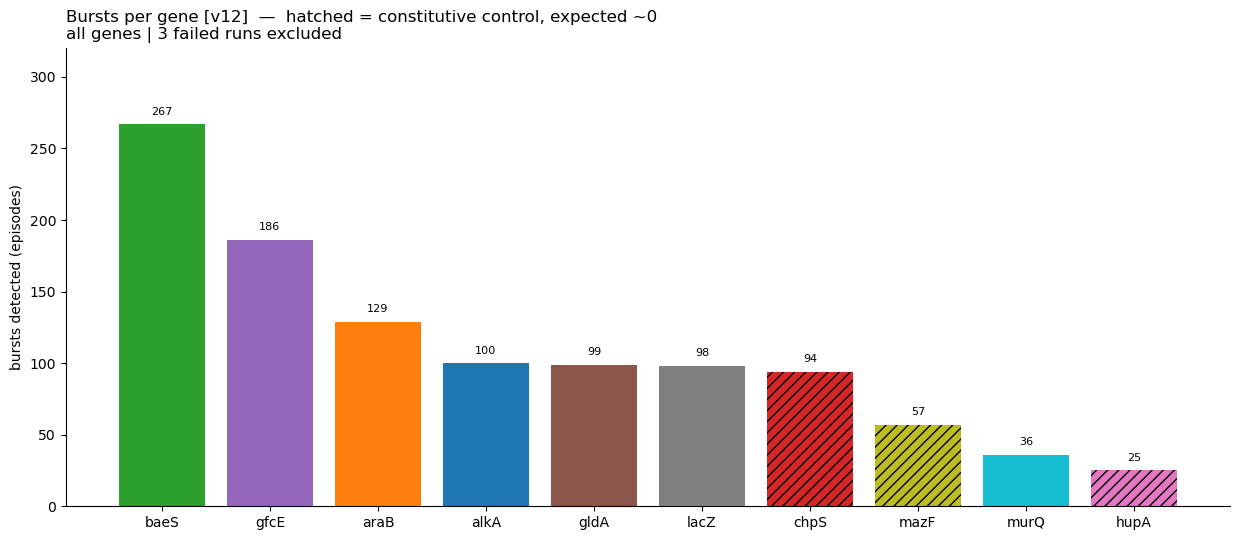

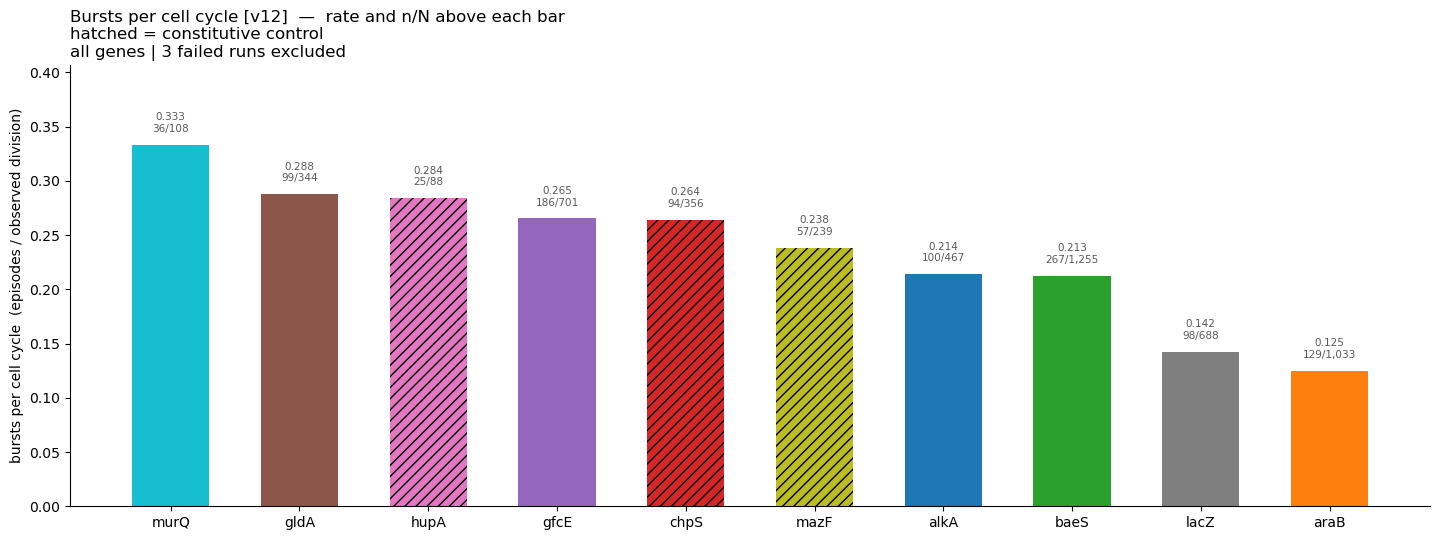

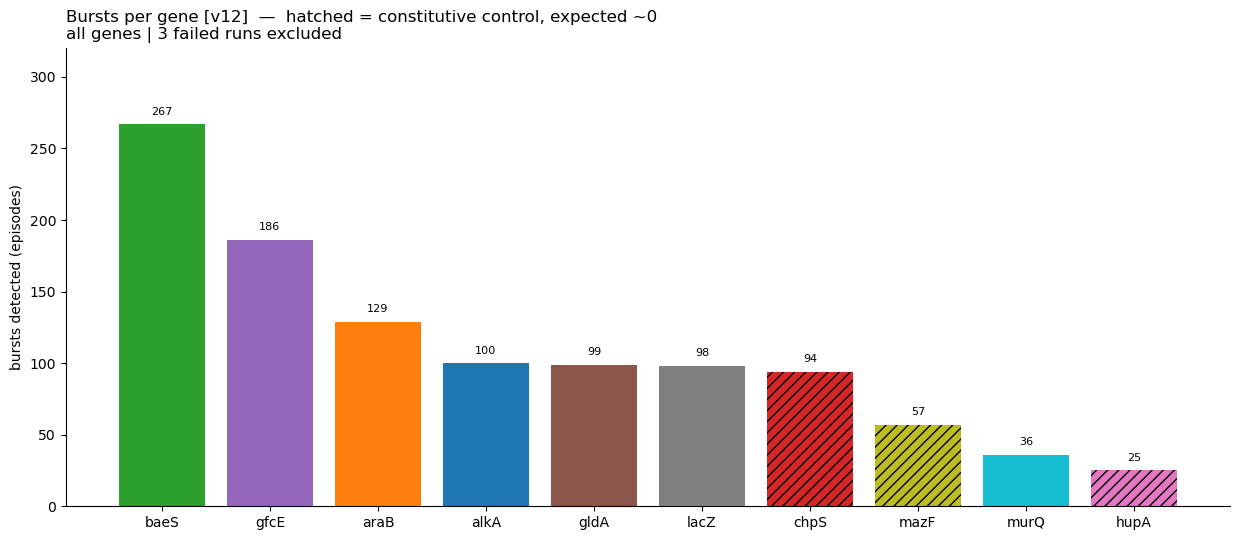

In [44]:
# The v12 union export (v7 / v11 / v12), written by mmtrack.burst_training. Separate from
# burst_csv_all, which section 8k writes and which carries only the rule-based definitions.
V12_CSV = f'{REPO_ROOT}/data/bursts_viewer_v12_091026.csv'
burst_csv_v12 = pd.read_csv(V12_CSV, dtype=F.READ_DTYPES)
print(f'{os.path.basename(V12_CSV)}: {len(burst_csv_v12)} rows | '
      + ' | '.join(f'{v}={int(burst_csv_v12[f"burst_{v}"].sum())}'
                   for v in ('v7', 'v11', 'v12')))

rate_v12 = F.bursts_per_cell_cycle(burst_csv_v12, divisions, version='v12')
print('\nbursts per cell cycle [v12]\n')
print(rate_v12.to_string())

F.plot_bursts_per_cell_cycle(burst_csv_v12, divisions, version='v12')
F.plot_burst_counts(burst_csv_v12, version='v12', by_experiment=False)

In [45]:
# Side by side with the two rules drawn beside it in the viewer. A TABLE, not a grouped bar
# chart: v7 measures a different image from v11/v12, so a shared bar axis would invite exactly
# the comparison bursts.md forbids. The numbers are still worth seeing together.
_rv = {v: F.bursts_per_cell_cycle(burst_csv_v12, divisions, version=v)
       for v in ('v7', 'v11', 'v12')}
_cmp = pd.DataFrame({v: _rv[v]['per_cell_cycle'] for v in ('v7', 'v11', 'v12')})
_cmp['n_divisions'] = _rv['v12']['n_divisions']
_cmp['CTL'] = ['<<<' if g in ('hupA', 'mazF', 'chpS') else '' for g in _cmp.index]
print('per cell cycle, by definition\n')
print(_cmp.drop(index='TOTAL').sort_values('v12', ascending=False).round(4).to_string())

# The acceptance test of section 9, REPORTED rather than asserted -- v12 fails it, by design
# of the training set rather than by accident.
_t = rate_v12.drop(index='TOTAL').sort_values('per_cell_cycle', ascending=False)
_rank = {g: i + 1 for i, g in enumerate(_t.index)}
print('\nconstitutive controls under v12 (bursts.md §9 would require ~0):')
for _g in ('hupA', 'mazF', 'chpS'):
    print(f'  {_g}: {int(rate_v12.loc[_g, "n_bursts"]):3d} events, '
          f'{rate_v12.loc[_g, "per_cell_cycle"]:.4f} per cell cycle, '
          f'rank {_rank[_g]} of {len(_t)}')
print('\nhupA ranks 3rd of ten. Under v11 it is 0 events and last. The model has never seen')
print('a control gene -- labelling a few hupA/mazF/chpS trenches is the fix, not retuning.')

per cell cycle, by definition

          v7     v11     v12  n_divisions  CTL
gene                                          
murQ  0.0278  0.2222  0.3333          108     
gldA  0.0727  0.1599  0.2878          344     
hupA  0.0114  0.0000  0.2841           88  <<<
gfcE  0.0414  0.1484  0.2653          701     
chpS  0.0140  0.0955  0.2640          356  <<<
mazF  0.0000  0.0377  0.2385          239  <<<
alkA  0.0493  0.1049  0.2141          467     
baeS  0.0112  0.0861  0.2127         1255     
lacZ  0.0567  0.0625  0.1424          688     
araB  0.0242  0.0416  0.1249         1033     

constitutive controls under v12 (bursts.md §9 would require ~0):
  hupA:  25 events, 0.2841 per cell cycle, rank 3 of 10
  mazF:  57 events, 0.2385 per cell cycle, rank 6 of 10
  chpS:  94 events, 0.2640 per cell cycle, rank 5 of 10

hupA ranks 3rd of ten. Under v11 it is 0 events and last. The model has never seen
a control gene -- labelling a few hupA/mazF/chpS trenches is the fix, not retuning.


---
# 13 — Cell cycles observed per trench, and bursts per *effective* cell cycle

Section 10b divides burst episodes by **observed divisions**, and `bursts_per_cell_cycle`'s own
docstring says what is wrong with that: *"a division only enters the denominator if the tracker
followed the cell through it, so a trench with poor tracking contributes bursts while contributing
fewer divisions, which inflates the rate."* `bursts.md` §11 repeats it. This section measures the
gap instead of only warning about it.

**The construction.** Per trench, take the cycles that were watched end to end, average their
length, and use that to convert the trench's *whole* observation record into cycle units:

$$\text{frames per cycle} = \operatorname{mean}\left(n_\text{frames}\right)
\ \ \text{over full cycles},
\qquad
\text{effective cycles} = \frac{n_\text{cell-frames}}{\text{frames per cycle}}$$

### Three choices, each of which moves the answer

**`mean(n_frames)`, not `mean(doubling_min)/\tau`.** The two differ by exactly one frame per
cycle — measured, `doubling_min == (n_frames - 1) * \tau` with **0 exceptions**. A parent on
frames $[f, l]$ divides *at* $l$ and its daughter's first frame is $l+1$, so birth-to-birth is
$n_\text{frames}$ intervals, not $n_\text{frames}-1$. On a synthetic trench — one cell slot, 100
frames, division every 10 — the right answer is 10 complete cycles, and $100/10=10$ gives it
while $100/9=11.1$ does not. Two consequences: **section 3's $T_d$ is one interval short of a
generation time**, and using it here would inflate every effective count by 12%. Both the identity
and the synthetic case are asserted below.

**The numerator is cell-frames, not trench time-frames.** A trench holds 1.4–9.8 cells per frame
(CV 0.38, p95/p05 = 4.0), so the two are not interchangeable — swapping them re-weights rather
than rescales. Trench-frames come out at **0.36×** the raw division count, i.e. they undercount
what was observed by ~2.8×, because they count the trench once instead of each cell in it.
`eff_cycles_timeframes` is kept as a column — "how many generations deep did the movie go" is a
real question — but it is not the denominator.

**Full cycle = `birth_observed & ~has_jump & n_frames >= 2`.** Stricter than section 3, which
reports those flags rather than applying them, and deliberately so: a mean doubling time survives
a few bad lifetimes, whereas here the number is **inverted and then multiplied by the entire
observation record**. The 186 single-frame parents are not merely soft in this use — a zero cycle
length makes `cycles_per_frame` infinite. Costs 5,279 → 4,225 cycles.

### What it buys, and what it does not

The effective count is **1.68–1.86× the division count per gene, 1.75× pooled** — a 1.11× spread
over ten genes. So this is an **honesty fix to the absolute rate, not a reordering**: under v6 the
gene ranking does not move at all, and under v12 only adjacent near-ties swap (v12's alkA/baeS
differ by 0.7%, gldA/hupA by 1.3%). Read it as *"the per-division rate was ~1.75× high because a
large share of the imaging never produced a closed division"*, not as a new result about any gene.

**The interval gets worse, not better.** `eff_cycles` is an estimate, so the exact-Poisson bounds —
which treat the denominator as a known count — are now too narrow by however much
`frames_per_cycle` is uncertain. And **29 of 255 trenches** have fewer than 3 full cycles of their
own and borrow their gene's median; they are open markers on the figure and flagged in
`cycle_len_source`. Dropping them instead would be the worse bug, because a trench missing from
the denominator still has bursts in the numerator.

255 trenches | cycle length from own trench: 226, borrowed from gene: 29, pooled: 0 (threshold 3 full cycles)
  full cycles: 4,225 of 5,279 divisions (birth_observed & ~has_jump & n_frames >= 2) | 186 single-frame parents in the dataset, none of which can be a full cycle
  frames per cycle: median 8.53 | minutes per cycle: median 75.4
  effective cycles 9,230 vs 5,279 observed divisions | per-trench ratio median 1.695
synthetic check: 100 cell-frames / 10 frames per cycle = 10.0 cycles (mean(n_frames-1) would give 11.11)

effective cell cycles per gene

       n_trenches  n_divisions  eff_cycles  n_cell_frames  median_min_per_cycle  n_borrowed  eff_per_division
gene                                                                                                         
baeS           53         1255    2160.012          18255                84.500           1             1.721
araB           56         1033    1810.626          14156                75.385           9             1.753


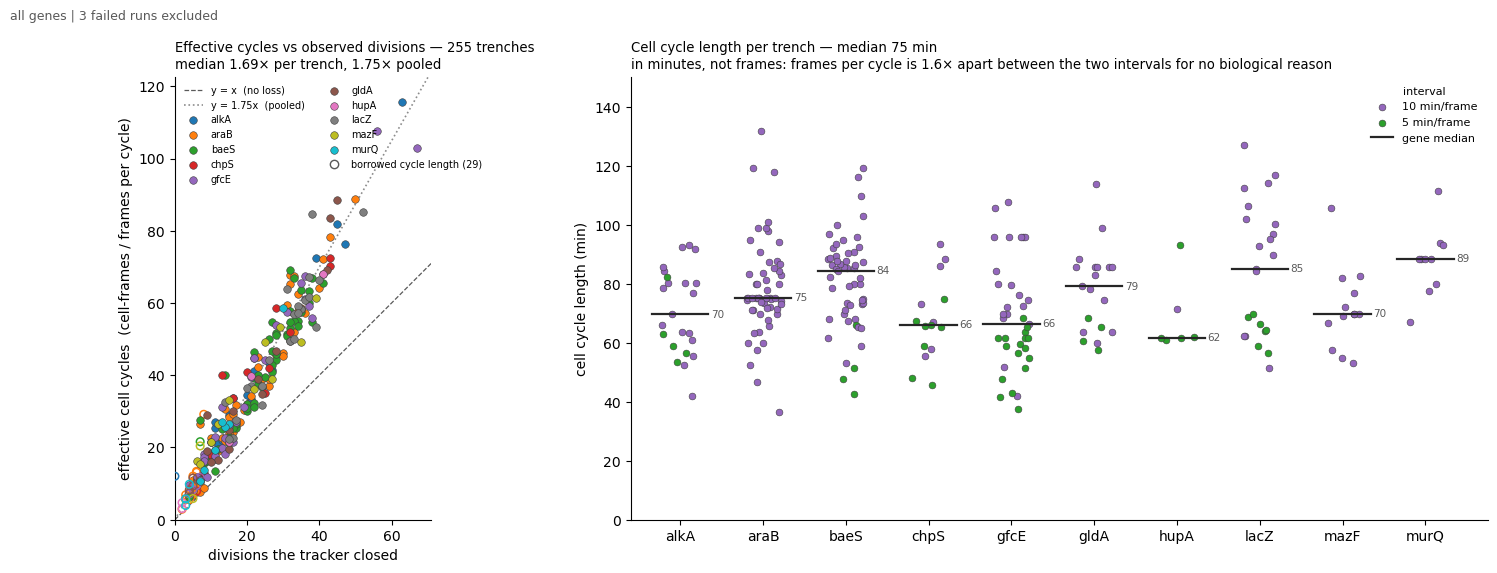

In [46]:
import mmtrack.lineage_stats as LS

# `cells`, not `clean`: a degenerate 1-px mask is a segmentation failure, but the cell was still
# there consuming cell-cycle time, and `divisions` is built from the full frame too. Filtering
# one side of a ratio and not the other is exactly how a denominator goes silently wrong.
cycles = LS.cell_cycles_per_trench(divisions, cells)

# The invariants. Each guards a specific failure, not a style preference.
assert int(cycles.n_cell_frames.sum()) == len(cells), 'cell-frames lost or double-counted'
assert int(cycles.n_divisions.sum()) == len(divisions), 'divisions lost in the trench join'
assert (cycles.frames_per_cycle > 0).all(), 'a zero cycle length is an infinite rate'
assert cycles.eff_cycles.notna().all(), 'a trench with no cycle-length estimate at all'
# The off-by-one the section rests on. If either of these ever fails, the choice of
# mean(n_frames) has to be re-derived before any number below can be quoted.
assert (divisions.n_frames == divisions.last_frame - divisions.first_frame + 1).all(), \
    'parent tracks are no longer gapless'
assert ((divisions.n_frames - 1) * divisions.minutes_per_frame
        == divisions.doubling_min).all(), \
    'doubling_min is no longer (n_frames - 1) * tau -- re-check the markdown above'

# The synthetic case from the markdown, computed rather than asserted in prose: one cell slot,
# 100 frames, a division exactly every 10 -> ten complete cycles.
_syn_cells = pd.DataFrame([
    dict(experiment_name='SYN', FOV='001', trench_id='1', track_id=c, time_frame=t,
         gene='lacZ', minutes_per_frame=10.0)
    for c in range(10) for t in range(10 * c, 10 * c + 10)])
_syn_div = pd.DataFrame([
    dict(experiment_name='SYN', FOV='001', trench_id='1', track_id=c, gene='lacZ',
         n_frames=10, first_frame=10 * c, last_frame=10 * c + 9, minutes_per_frame=10.0,
         doubling_min=90.0, birth_observed=c > 0, has_jump=False) for c in range(10)])
_syn = LS.cell_cycles_per_trench(_syn_div, _syn_cells, verbose=False).iloc[0]
assert _syn.eff_cycles == 10.0, f'synthetic trench gives {_syn.eff_cycles}, not 10.0'
print(f'synthetic check: {_syn.n_cell_frames:.0f} cell-frames / '
      f'{_syn.frames_per_cycle:.0f} frames per cycle = {_syn.eff_cycles:.1f} cycles '
      f'(mean(n_frames-1) would give {100 / 9:.2f})')

eff_by_gene = LS.effective_cycles_by_gene(cycles)
print('\neffective cell cycles per gene\n')
print(eff_by_gene.round(3).to_string())

F.plot_cell_cycles_per_trench(cycles);


=== v6 ===  0 of 10 genes change rank
       per_division  per_eff_cycle   fold  rank_div  rank_eff
gene                                                         
gldA         0.0698         0.0394  1.772       1.0       1.0
lacZ         0.0552         0.0326  1.693       2.0       2.0
alkA         0.0493         0.0273  1.806       3.0       3.0
gfcE         0.0399         0.0227  1.758       4.0       4.0
araB         0.0213         0.0122  1.746       5.0       5.0
murQ         0.0185         0.0099  1.869       6.0       6.0
chpS         0.0140         0.0079  1.772       7.0       7.0
baeS         0.0112         0.0065  1.723       8.0       8.0
hupA         0.0000         0.0000    NaN       9.0       9.0
mazF         0.0000         0.0000    NaN      10.0      10.0
TOTAL        0.0296         0.0169  1.751       NaN       NaN

=== v12 ===  4 of 10 genes change rank: gldA, hupA, alkA, baeS
       per_division  per_eff_cycle   fold  rank_div  rank_eff
gene                         


per-gene fold 1.683-1.864 (spread 1.11x), pooled 1.748 -- a rescale of every rate, not a reordering of the genes.


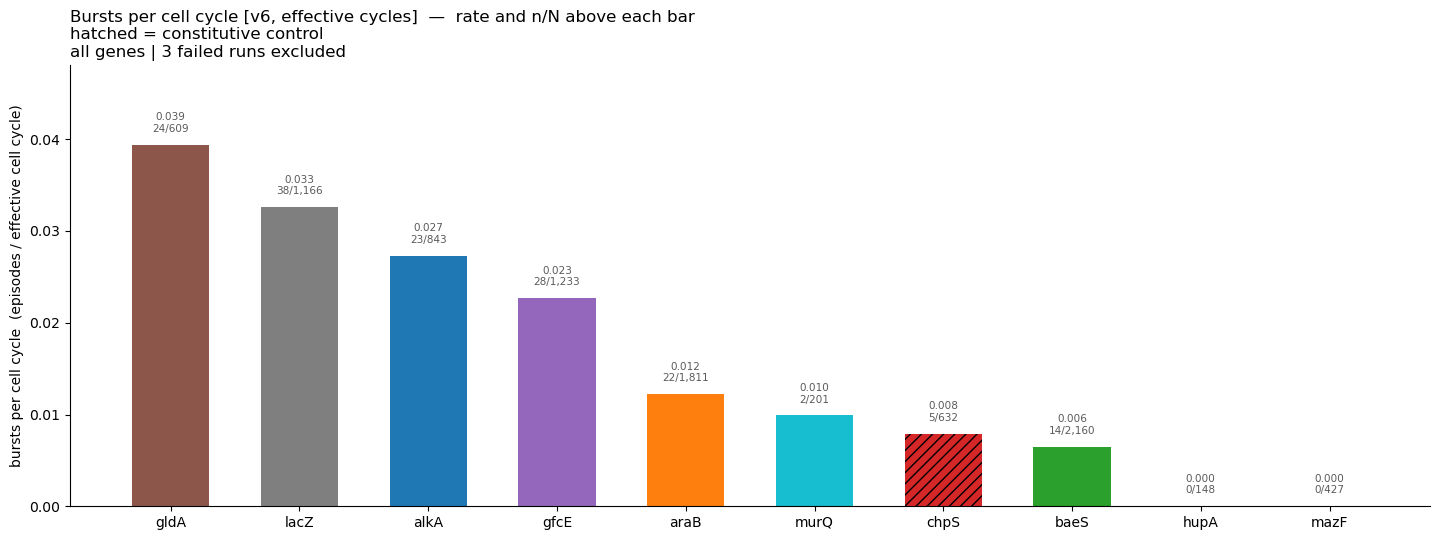

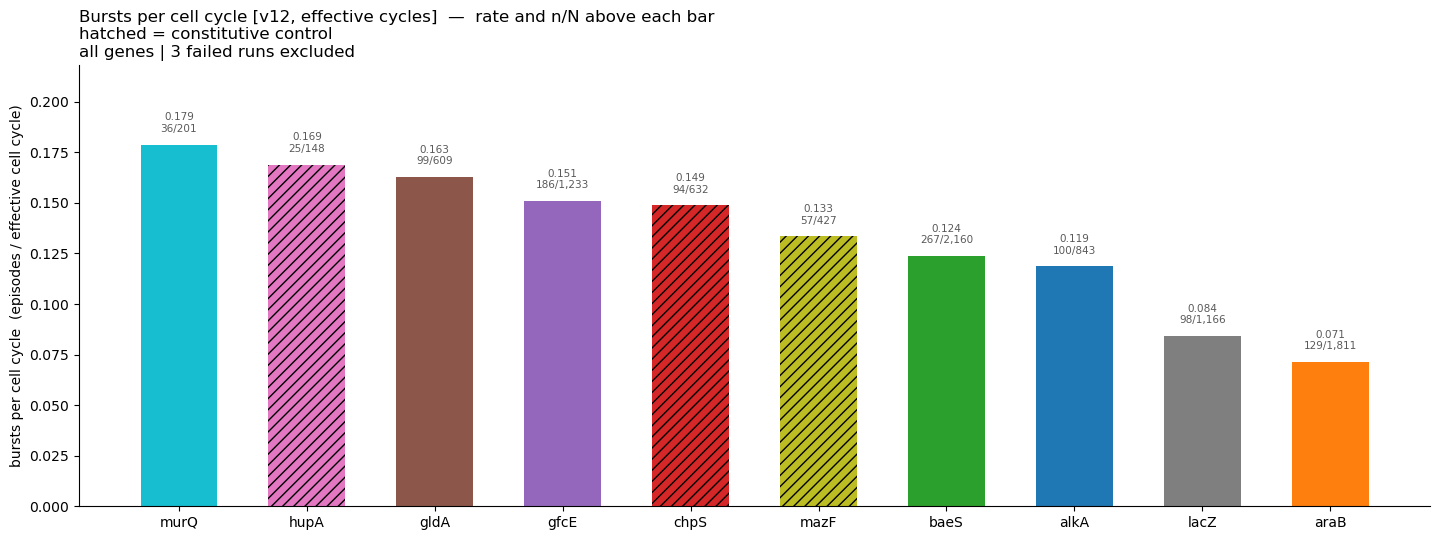

In [47]:
# The two denominators side by side: v6 is the last closed-form rule and v12 the classifier.
# Same numerator throughout -- only the denominator changes.
_EFF = eff_by_gene['eff_cycles']
_SRC = {'v6': burst_csv_all}
for _v, _p in (('v12', 'data/bursts_v12_091026.csv'),):
    _e = pd.read_csv(f'{REPO_ROOT}/{_p}', dtype=F.READ_DTYPES)
    _e[f'burst_{_v}'] = True
    _SRC[_v] = _e

for _v, _b in _SRC.items():
    _div = F.bursts_per_cell_cycle(_b, divisions, version=_v)
    _eff = F.bursts_per_cell_cycle(_b, divisions, version=_v, denom=_EFF)
    _oa = [g for g in _div.index if g != 'TOTAL']
    _ox = [g for g in _eff.index if g != 'TOTAL']
    _t = pd.DataFrame({'per_division': _div['per_cell_cycle'],
                       'per_eff_cycle': _eff['per_cell_cycle']})
    _t['fold'] = (_t.per_division / _t.per_eff_cycle).round(3)
    _t['rank_div'] = [_oa.index(g) + 1 if g in _oa else np.nan for g in _t.index]
    _t['rank_eff'] = [_ox.index(g) + 1 if g in _ox else np.nan for g in _t.index]
    _moved = [g for g in _oa if _oa.index(g) != _ox.index(g)]
    print(f'\n=== {_v} ===  {len(_moved)} of {len(_oa)} genes change rank'
          + (f': {", ".join(_moved)}' if _moved else ''))
    print(_t.round(4).to_string())
    F.plot_bursts_per_cell_cycle(_b, divisions, version=_v, denom=_EFF)

# The claim the whole section rests on, checked rather than asserted in prose. If the fold ever
# becomes gene-dependent, the swap stops being a rescale and the rankings above need re-reading.
_fold = eff_by_gene.drop(index='TOTAL')['eff_per_division']
assert 1.6 < _fold.min() and _fold.max() < 1.9, _fold
print(f'\nper-gene fold {_fold.min():.3f}-{_fold.max():.3f} '
      f'(spread {_fold.max() / _fold.min():.2f}x), pooled '
      f'{eff_by_gene.loc["TOTAL", "eff_per_division"]:.3f} '
      f'-- a rescale of every rate, not a reordering of the genes.')